# **Proyecto Aplicado — Big Data**
## **Predicción del Puntaje Global en las Pruebas Saber 11 con Cassandra y Dask**

---

Este notebook integra **todas las entregas** del proyecto aplicado del módulo de **Big Data** y se ejecuta como una **unidad de extremo a extremo**: **Fase 1** (entendimiento del negocio y diseño de la solución), **Fase 2** (definición e implementación de tecnologías), **Fase 3** (entendimiento y carga de los datos) y **Fase 4** (preparación de los datos), cerrando con el **modelamiento y la evaluación** previstos en el cronograma. Cada fase reutiliza —mediante referencias internas— lo construido en las anteriores.

El proyecto toma como punto de partida un trabajo previo desarrollado en el módulo de **Machine Learning**, en el cual se abordó la predicción del puntaje global en las Pruebas Saber 11 utilizando herramientas tradicionales como **pandas** y **scikit-learn**. En esta nueva iteración, la necesidad de negocio se mantiene, pero el enfoque técnico se transforma: el objetivo principal ya no es únicamente construir un modelo predictivo, sino rediseñar el pipeline analítico para operar bajo una arquitectura orientada a **Big Data**.

De esta manera, el valor agregado del presente proyecto está en trasladar el problema a un entorno más escalable, incorporando tecnologías de almacenamiento y procesamiento distribuido acordes con los lineamientos del módulo. En particular:

- **Almacenamiento distribuido:** el conjunto de datos será gestionado mediante **Cassandra**, una base de datos NoSQL columnar diseñada para alta disponibilidad y escalabilidad horizontal.
- **Procesamiento y entrenamiento distribuidos:** el flujo de análisis exploratorio, preparación de datos y modelamiento se ejecutará sobre **Dask**, un framework de cómputo paralelo en Python compatible con la API de **pandas** y **scikit-learn**.

El conjunto de datos utilizado es *Resultados Únicos Saber 11* —periodos 2010–2022—, publicado por el ICFES en la plataforma de [Datos Abiertos de Colombia](https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data). Este dataset contiene cerca de *7.1 millones de registros* y *51 variables*, lo cual justifica el uso de un stack de Big Data para su almacenamiento, procesamiento y análisis.

## Sobre esta edición

Esta edición conserva las fases, el código y la discusión de la entrega académica. Las salidas guardadas se limitan a resultados agregados y figuras seleccionadas. Los resultados corresponden a la ejecución original.

**Reproducción.** La ejecución usa el corte Saber 11, una instalación de Cassandra, Dask y PyArrow. Las secciones de arquitectura y despliegue documentan la configuración del entorno académico y los artefactos esperados.

[Volver al README del proyecto](../README.md)


## Integrantes del equipo

- Manuela Zapata Jiménez
- David Cardona Duque

---
# **Fase 1 — Entendimiento del Negocio**
---

Esta fase comprende el entendimiento del contexto del negocio, la definición de objetivos, la planeación del proyecto y el diseño de la arquitectura de la solución sobre tecnologías de Big Data (Apache Cassandra + Dask). Incluye la declaración del dataset que se utilizará, sin ejecutar todavía su carga (la ingesta efectiva se realiza en la Fase 2). Para la descripción detallada de la metodología CRISP-DM, véase Chapman et al. (2000).

## **1. Marco de Proyecto**
---

A continuación se presenta el marco del proyecto, construido siguiendo la metodología **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*; Chapman et al., 2000), la cual estructura el desarrollo de proyectos de analítica de datos en seis fases iterativas: entendimiento del negocio, entendimiento de los datos, preparación de los datos, modelado, evaluación y despliegue. Esta metodología se mantiene como hilo conductor, complementada con prácticas propias de proyectos de Big Data: desacoplamiento entre almacenamiento y cómputo, paralelización y particionamiento de los datos.

### **1.1. Trasfondo del Negocio**
---

#### **Contexto**

En Colombia, el examen **Saber 11** es una evaluación externa estandarizada aplicada por el **Instituto Colombiano para la Evaluación de la Educación (Icfes)** a quienes están finalizando la educación media y a otras personas habilitadas para presentarlo oficialmente. De acuerdo con la guía de orientación vigente, el examen está compuesto por cinco pruebas —**Lectura Crítica**, **Matemáticas**, **Sociales y Ciudadanas**, **Ciencias Naturales** e **Inglés**— y un cuestionario socioeconómico, a partir de los cuales se reportan resultados agregados e individuales, incluido el **Puntaje Global** (Colombia, 2010; Icfes, 2024).

Los resultados de Saber 11 cumplen una función estratégica dentro del sistema educativo: aportan información para el ingreso a la educación superior, el monitoreo de la calidad educativa y la formulación de políticas públicas nacionales, territoriales e institucionales (Colombia, 2010). Además, la literatura empírica sobre Colombia muestra que el rendimiento en este tipo de pruebas se asocia de manera sistemática con factores socioeconómicos, familiares e institucionales, como el nivel educativo de los padres, el ingreso del hogar, el acceso a computador y las brechas regionales (Cerquera Losada et al., 2016; Rodríguez Rosero et al., 2021).

Colombia presenta disparidades educativas significativas. En PISA 2018, la brecha en lectura entre estudiantes socioeconómicamente favorecidos y desfavorecidos en Colombia fue de **86 puntos**, y los informes recientes del Banco Mundial documentan profundas desigualdades territoriales en los resultados educativos, asociadas con pobreza multidimensional, ruralidad, pertenencia étnica y antecedentes de conflicto (OECD, 2019; Demombynes, 2023). Comprender y modelar estas relaciones mediante técnicas de *machine learning* puede contribuir a la identificación temprana de perfiles de riesgo y al diseño de intervenciones focalizadas.

A esto se suma un **reto técnico-operativo**: el conjunto histórico de Saber 11 contiene cerca de **7.1 millones de registros y 51 variables**, lo que lo posiciona en el régimen de **Big Data** según los criterios clásicos de **volumen, variedad y velocidad** (Laney, 2001). Procesarlo de manera eficiente, reproducible y escalable requiere arquitecturas distribuidas que superen las limitaciones de procesamiento monolítico en memoria.

#### **Cliente o beneficiarios**

Los principales beneficiarios de este proyecto son:

- **ICFES**: como entidad encargada de la evaluación educativa, se beneficia de modelos predictivos que permitan comprender los factores determinantes del desempeño estudiantil sobre el universo completo de aplicantes.
- **Ministerio de Educación Nacional (MEN)**: puede utilizar los resultados para orientar políticas de mejoramiento de la calidad educativa y la reducción de brechas, apoyado en una infraestructura capaz de procesar millones de registros.
- **Secretarías de Educación departamentales y municipales**: para focalizar recursos e intervenciones en las instituciones y poblaciones con mayor riesgo de bajo rendimiento.
- **Instituciones educativas**: para identificar áreas de mejora en sus procesos pedagógicos a partir de las variables predictoras más relevantes.
- **Investigadores en educación y ciencia de datos**: como insumo para estudios sobre determinantes del rendimiento académico en el contexto colombiano y como caso de referencia para el uso de tecnologías Big Data sobre datos educativos abiertos.

#### **Dominio**

El proyecto se enmarca en la intersección entre la **analítica educativa** (*Educational Data Mining* y *Learning Analytics*) y la **ingeniería de datos a gran escala** (*Big Data Engineering*). El primer dominio aplica técnicas de minería de datos y aprendizaje automático para analizar datos generados en contextos educativos (Romero & Ventura, 2020); el segundo aporta los patrones arquitectónicos y herramientas necesarias para que dichos análisis sean factibles y escalables sobre conjuntos de datos masivos.

Específicamente, se aborda un problema de **regresión supervisada** orientado a predecir una variable numérica continua: el puntaje global de la prueba Saber 11.

#### **Problema a solucionar**

El problema central es la **predicción del puntaje global (`PUNT_GLOBAL`) en las pruebas Saber 11**, a partir de variables socioeconómicas, familiares, institucionales y geográficas del estudiante y de su colegio, sobre el **universo histórico completo** del examen (~7.1M registros, 13 años).

La relevancia de este problema radica en:

1. **Identificación de factores determinantes**: permitir a los actores del sistema educativo comprender cuáles son las variables que más influyen en el rendimiento académico, más allá de la intuición o el análisis descriptivo.
2. **Detección temprana de riesgo**: posibilitar la identificación anticipada de perfiles estudiantiles con alta probabilidad de bajo desempeño, para implementar intervenciones oportunas.
3. **Diseño de políticas basadas en evidencia**: proveer a los tomadores de decisiones de herramientas cuantitativas que sustenten la asignación de recursos y la priorización de programas educativos.
4. **Reducción de brechas de equidad**: contribuir a la comprensión de las desigualdades educativas en Colombia y a la formulación de estrategias para mitigarlas.
5. **Escalabilidad y reutilización**: construir un pipeline reproducible sobre tecnologías de Big Data que permita reentrenar e iterar el modelo conforme se incorporan nuevas cohortes anuales sin rediseñar la arquitectura.

Estudios previos, tanto en la literatura internacional como en investigaciones aplicadas al caso colombiano, han documentado que variables como el nivel socioeconómico, la educación de los padres y el contexto territorial se asocian de forma robusta con el rendimiento en pruebas estandarizadas (Sirin, 2005; Reardon, 2011; Rodríguez Rosero et al., 2021). Este proyecto busca cuantificar dichas relaciones en el contexto colombiano mediante modelos de *machine learning* distribuidos, aprovechando un conjunto de datos a gran escala con más de 7 millones de registros.

### **1.2. Alcance**
---

#### **Solución propuesta**

Se propone desarrollar un **pipeline analítico distribuido de extremo a extremo** que reproduzca, sobre tecnologías de Big Data, el flujo CRISP-DM ya validado en el proyecto del módulo de *Machine Learning*. Concretamente, el pipeline:

1. **Ingiere y almacena** el dataset histórico de Saber 11 (~7.1M registros, 51 variables) en un clúster de **Apache Cassandra**, modelando la tabla con una clave de partición que permita lecturas paralelas eficientes por periodo.
2. **Lee y procesa** los datos desde Cassandra hacia **Dask** (`dask.dataframe`), aprovechando paralelismo multinúcleo y ejecución *out-of-core* para no estar limitados por la RAM disponible.
3. **Aplica las mismas decisiones de limpieza, preparación e ingeniería de características** ya documentadas y justificadas en el proyecto ML (eliminación de duplicados por `ESTU_CONSECUTIVO + PERIODO`, corrección de nomenclatura `4 → 2`, filtrado a periodos ≥ 2014-2, exclusión de variables de *leakage*/identificadoras/baja varianza, codificación ordinal/binaria/*one-hot*/*target encoding*, etc.).
4. **Entrena y evalúa** modelos de **regresión** que predicen `PUNT_GLOBAL`. Por las restricciones del entorno (Cassandra + Dask en máquina local), se priorizarán modelos compatibles con el *backend* distribuido: `dask-ml.Ridge` como referencia lineal y `xgboost.dask.DaskXGBRegressor` como modelo principal de *gradient boosting* (que ya demostró en el proyecto ML un desempeño equivalente a `HistGradientBoostingRegressor`).
5. **Compara** las métricas obtenidas con las del proyecto ML para verificar que el pipeline distribuido **preserva** el desempeño analítico.

#### **Incluye**

- Diseño y despliegue local de un **clúster Cassandra** (Docker o instalación nativa, *single-node* representativo) con su *keyspace* y esquema CQL.
- **Ingesta** del archivo CSV de Datos Abiertos hacia Cassandra (carga *bulk* con validación de integridad: conteo de filas, verificación de tipos).
- **Lectura distribuida** desde Cassandra hacia Dask DataFrames vía `cassandra-driver` (consultas paralelas por *token range* o por valor de partición).
- **Análisis exploratorio (EDA)** y de calidad de datos ejecutado de manera paralelizada con Dask, replicando el alcance de la Fase 2 del proyecto ML.
- **Preparación distribuida** de los datos, replicando las decisiones del proyecto ML: tratamiento de faltantes, codificación de categóricas, ingeniería de `EDAD_PRESENTACION` y `SEMESTRE`, *target encoding* OOF para municipios post-partición, partición 80/10/10 estratificada por quintiles de `PUNT_GLOBAL`.
- **Persistencia** del dataset preparado en formato **Apache Parquet particionado**, óptimo para lectura paralela.
- **Entrenamiento, validación y evaluación** de los modelos sobre Dask con métricas estándar (MAE, RMSE, R²), análisis de importancia de variables y diagnóstico por subgrupos.
- **Comparativa explícita** entre las métricas del proyecto ML y las del proyecto Big Data para verificar la fidelidad del pipeline.
- **Documentación** del proceso siguiendo la metodología CRISP-DM, justificando en cada fase el uso de herramientas de Big Data.

#### **Excluye**

- **Mejorar las métricas de desempeño** respecto al proyecto ML. El estudio previo demostró —comparando dos implementaciones distintas de *gradient boosting*— que el desempeño está limitado por la información disponible en el dataset, no por la herramienta. Comprometernos con un R² superior a ~0.45 sería ignorar esa evidencia.
- Predicción de los puntajes individuales por área (Inglés, Matemáticas, Lectura Crítica, Ciencias Naturales, Sociales y Ciudadanas); el foco se mantiene exclusivamente en el puntaje global.
- Inferencia causal entre variables (el modelo es predictivo, no explicativo).
- Despliegue en producción como servicio web, API o stream en tiempo real (el resultado es un pipeline *batch* reproducible).
- Uso de datos externos al conjunto provisto (DANE, encuestas adicionales, etc.).
- Implementación de un clúster productivo Cassandra multinodo en infraestructura cloud; se trabajará con un clúster local *single-node* / Docker representativo, suficiente para validar el modelo de datos y el flujo completo.
- Modelos de *deep learning*, dado que la naturaleza tabular del dataset favorece métodos basados en árboles y modelos lineales escalables.

#### **Forma de uso**

El producto del proyecto será un **pipeline batch reproducible** compuesto por:

- Un **clúster Cassandra** poblado con el dataset histórico de Saber 11 y un esquema CQL documentado.
- Un conjunto de **notebooks/scripts Dask** que orquestan la lectura, transformación, entrenamiento y evaluación del modelo.
- Un **modelo entrenado y persistido** (`joblib`/`pickle` + metadatos JSON) acompañado de un análisis comparativo respecto al modelo del proyecto ML.

Los beneficiarios podrán:

- **Consultar las variables más determinantes** del desempeño académico para orientar políticas educativas.
- **Reentrenar el modelo** cuando se incorporen nuevas cohortes en Cassandra, sin rediseñar la arquitectura.
- **Utilizar el modelo** para estimar el puntaje esperado de un estudiante dado su perfil socioeconómico e institucional.
- **Replicar la metodología** sobre otros datasets educativos abiertos de magnitud similar.

### **1.3. Plan del Proyecto**
---

El proyecto se estructura en **5 fases** alineadas con la metodología CRISP-DM y con los hitos de entrega del módulo de Big Data. Cada fase culmina los **miércoles**, según el cronograma definido por la asignatura:

| Fase | Actividad | Periodo de trabajo | Entrega | Semana |
|------|-----------|--------------------|---------|--------|
| **Fase 1** | **Entendimiento del negocio** | 6 may – 13 may 2026 | **13 may 2026** | Semana 1 |
| | Investigación del contexto educativo y revisión del proyecto previo de ML | 6 may – 8 may | | |
| | Definición de objetivos, alcance y selección del stack de Big Data | 8 may – 10 may | | |
| | Diseño de la arquitectura preliminar (Cassandra + Dask) | 10 may – 12 may | | |
| | Documentación del marco de proyecto en este notebook | 12 may – 13 may | | |
| **Fase 2** | **Definición e implementación de las tecnologías de Big Data** | 13 may – 20 may 2026 | **20 may 2026** | Semana 2 |
| | Despliegue local del clúster Cassandra (Docker / *single-node*) | 13 may – 14 may | | |
| | Diseño del *keyspace* y de la(s) tabla(s) según patrones de consulta | 14 may – 16 may | | |
| | Configuración del entorno Dask (cliente, *workers*, *scheduler*) | 16 may – 17 may | | |
| | Validación del flujo Cassandra ⇄ Dask con datos de prueba | 17 may – 19 may | | |
| | Documentación de la infraestructura y pruebas de humo | 19 may – 20 may | | |
| **Fase 3** | **Entendimiento y carga de los datos** | 20 may – 27 may 2026 | **27 may 2026** | Semana 3 |
| | Ingesta del CSV de Saber 11 en Cassandra (*bulk load*) | 20 may – 22 may | | |
| | Verificación de integridad: conteo de registros, tipos, valores únicos | 22 may – 23 may | | |
| | Análisis exploratorio (EDA) distribuido con Dask | 23 may – 25 may | | |
| | Análisis de calidad: faltantes, duplicados, atípicos, periodos | 25 may – 26 may | | |
| | Visualizaciones agregadas y resumen de hallazgos | 26 may – 27 may | | |
| **Fase 4** | **Preparación de los datos** | 27 may – 3 jun 2026 | **3 jun 2026** | Semana 4 |
| | Limpieza distribuida (faltantes, duplicados, inconsistencias) | 27 may – 29 may | | |
| | Codificación de variables categóricas e ingeniería de características | 29 may – 31 may | | |
| | Normalización/transformación de variables numéricas | 31 may – 1 jun | | |
| | Partición train/validation/test con Dask | 1 jun – 2 jun | | |
| | Persistencia del dataset procesado (formato `parquet` particionado) | 2 jun – 3 jun | | |
| **Fase 5** | **Modelamiento y evaluación** | 3 jun – 10 jun 2026 | **10 jun 2026** | Semana 5 |
| | Entrenamiento de modelos *baseline* y lineales con Dask-ML | 3 jun – 5 jun | | |
| | Entrenamiento de modelos avanzados (XGBoost-Dask, Gradient Boosting) | 5 jun – 7 jun | | |
| | Optimización de hiperparámetros (búsqueda distribuida) | 7 jun – 8 jun | | |
| | Evaluación final, importancia de variables y conclusiones | 8 jun – 10 jun | | |

#### **Diagrama de Gantt**

A continuación se presenta una representación visual del cronograma del proyecto, con las cinco fases y sus respectivas fechas de entrega:

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

phases = [
    ("Fase 1: Entendimiento\ndel negocio",                                  "2026-05-06", "2026-05-13"),
    ("Fase 2: Definición e implementación\nde tecnologías de Big Data",    "2026-05-13", "2026-05-20"),
    ("Fase 3: Entendimiento y\ncarga de los datos",                        "2026-05-20", "2026-05-27"),
    ("Fase 4: Preparación\nde los datos",                                  "2026-05-27", "2026-06-03"),
    ("Fase 5: Modelamiento\ny evaluación",                                 "2026-06-03", "2026-06-10"),
]

colors = ["#1b5e20", "#2e7d32", "#388e3c", "#43a047", "#66bb6a"]

fig, ax = plt.subplots(figsize=(14, 4.5))

for i, (label, start, end) in enumerate(phases):
    start_dt = datetime.strptime(start, "%Y-%m-%d")
    end_dt = datetime.strptime(end, "%Y-%m-%d")
    duration = (end_dt - start_dt).days
    ax.barh(i, duration, left=start_dt, height=0.5, color=colors[i],
            edgecolor="white", linewidth=1.5)
    ax.text(start_dt + (end_dt - start_dt) / 2, i,
            f"Entrega:\n{end_dt.strftime('%d %b')}",
            ha="center", va="center", fontsize=8, fontweight="bold", color="white")

ax.set_yticks(range(len(phases)))
ax.set_yticklabels([p[0] for p in phases], fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.WE))
ax.set_xlabel("Fecha", fontsize=10)
ax.set_title("Cronograma del Proyecto — Saber 11 con Cassandra y Dask",
             fontsize=12, fontweight="bold")
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## **2. Definición del Diseño y/o Arquitectura de la Solución**
---

En esta sección se aborda de manera integral la definición del diseño y la arquitectura de la solución, justificando explícitamente la incorporación de tecnologías de **cómputo distribuido y Big Data** — **Apache Cassandra** como motor de almacenamiento y **Dask** como motor de procesamiento y entrenamiento — en un escenario donde el volumen de datos (~7.1 millones de registros, 51 columnas, ~13 años de histórico) hace inadecuadas las herramientas tradicionales en memoria.

### **2.1. Descripción**
---

La solución se estructura como un **pipeline analítico distribuido en lote (batch)** con clara separación entre la capa de **almacenamiento** y la capa de **cómputo**, siguiendo el patrón arquitectónico *storage–compute decoupling* habitual en sistemas modernos de Big Data.

#### **Vista general del flujo**

```
[CSV Datos Abiertos]
        │
        ▼
[Ingesta batch  ──►  Apache Cassandra (keyspace: saber11)]
                              │
                              ▼
            [Lectura distribuida → Dask DataFrame]
                              │
        ┌─────────────────────┼─────────────────────┐
        ▼                     ▼                     ▼
   EDA distribuido     Preparación de datos   Entrenamiento
   (Dask + Seaborn)    (Dask DataFrame /      (Dask-ML / XGBoost-Dask)
                       dask-ml preprocessing)
                              │
                              ▼
                  [Modelo persistido + métricas]
```

#### **Componentes clave de la solución**

1. **Capa de almacenamiento — Apache Cassandra**
   - Base de datos NoSQL columnar, distribuida y *masterless*, diseñada para alta disponibilidad y escalabilidad horizontal lineal (Lakshman & Malik, 2010).
   - Modelado *query-driven*: la(s) tabla(s) se diseñan en función de los patrones de acceso del proyecto (lecturas masivas por `PERIODO`).
   - **Clave de partición** propuesta: `periodo`. Tras el filtrado temporal previsto en Fase 3 (≥ 2014-2), se obtienen 14 particiones (una por semestre con datos disponibles), cada una con del orden de 100k–250k filas. Esto se mantiene dentro del rango aceptable para el *POC* de Cassandra (la regla práctica recomienda < 100 MB y < 100 000 filas por *partition key* en producción; las particiones más cargadas son manejables en *single-node* académico y siguen siendo aceptables si se escala el clúster).
   - **Clave de clustering**: `estu_consecutivo` para preservar unicidad por examinando dentro de cada partición y permitir consultas puntuales por estudiante.

2. **Capa de cómputo — Dask**
   - Framework de cómputo paralelo en Python que escala APIs familiares (`pandas`, `numpy`, `scikit-learn`) desde una laptop multinúcleo hasta clústers (Rocklin, 2015).
   - Ejecución *lazy* basada en grafos de tareas, con planificadores local (*threads*/*processes*) y distribuido (`dask.distributed`).
   - **Out-of-core**: permite trabajar con datasets que exceden la RAM disponible mediante particionamiento por *chunks*.
   - **Compatibilidad ML**: `dask-ml` provee implementaciones distribuidas de preprocesadores y modelos lineales; `xgboost.dask` permite entrenar *gradient boosting* en paralelo sobre los mismos *workers*.

3. **Conector Cassandra ⇄ Dask**
   - `cassandra-driver` (DataStax) para operaciones de lectura/escritura.
   - Estrategia *bulk read* paralelizando consultas por valor de partición (`periodo`), materializando cada partición Cassandra como una partición Dask. Para grandes volúmenes se considerará paralelización por *token range*.

4. **Capa de modelamiento y evaluación**
   - Modelo *baseline*: regresión lineal regularizada (`dask_ml.linear_model.Ridge`).
   - Modelo principal: `xgboost.dask.DaskXGBRegressor` para *gradient boosting* paralelo (en el proyecto ML alcanzó R²≈0.4455, prácticamente idéntico a `HistGradientBoostingRegressor` con R²≈0.4468).
   - Métricas: MAE, RMSE, R² calculadas con `dask_ml.metrics`.

5. **Capa de persistencia y reproducibilidad**
   - Datasets intermedios (post-preparación) en formato **Apache Parquet particionado por `periodo`**, óptimo para lectura columnar paralela en Dask.
   - Modelo final serializado (`joblib`) junto con metadatos JSON del pipeline.

#### **Modelo de datos en Cassandra (DDL preliminar)**

A continuación se presenta el **DDL CQL preliminar** que se implementará en Fase 2. Las columnas conservan los nombres originales del CSV (en minúsculas, convención Cassandra) y los tipos se eligen siguiendo la inspección hecha en el proyecto ML (`int` para `PERIODO`, `double` para puntajes, `text` para categóricas, `date` para fecha de nacimiento). El código de la implementación se desarrollará en la Fase 2; aquí solo se documenta el modelado.

```cql
-- Keyspace para POC single-node (factor de replicación = 1).
-- En producción multinodo se cambiaría a NetworkTopologyStrategy.
CREATE KEYSPACE IF NOT EXISTS saber11
    WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1};

USE saber11;

-- Tabla principal: una fila por examinando-periodo.
-- Particionada por PERIODO para que las lecturas masivas
-- (EDA, entrenamiento) se paralelicen naturalmente desde Dask.
CREATE TABLE IF NOT EXISTS resultados_saber11 (
    -- Clave de partición
    periodo                          int,
    -- Clave de clustering (unicidad dentro de la partición)
    estu_consecutivo                 text,

    -- Variable objetivo
    punt_global                      double,

    -- Puntajes por área (se mantienen en la tabla; serán excluidos
    -- en la fase de modelado por data leakage, pero pueden ser útiles
    -- para EDA y validación cruzada del puntaje global)
    punt_ingles                      double,
    punt_matematicas                 double,
    punt_sociales_ciudadanas         double,
    punt_c_naturales                 double,
    punt_lectura_critica             double,
    desemp_ingles                    text,

    -- Estudiante
    estu_tipodocumento               text,
    estu_fechanacimiento             date,
    estu_genero                      text,
    estu_nacionalidad                text,
    estu_estudiante                  text,
    estu_privado_libertad            text,
    estu_estadoinvestigacion         text,
    estu_pais_reside                 text,

    -- Ubicación del estudiante
    estu_cod_depto_presentacion      int,
    estu_depto_presentacion          text,
    estu_cod_mcpio_presentacion      int,
    estu_mcpio_presentacion          text,
    estu_cod_reside_depto            int,
    estu_depto_reside                text,
    estu_cod_reside_mcpio            int,
    estu_mcpio_reside                text,

    -- Colegio
    cole_area_ubicacion              text,
    cole_bilingue                    text,
    cole_calendario                  text,
    cole_caracter                    text,
    cole_cod_dane_establecimiento    bigint,
    cole_cod_dane_sede               bigint,
    cole_cod_depto_ubicacion         int,
    cole_cod_mcpio_ubicacion         int,
    cole_codigo_icfes                int,
    cole_depto_ubicacion             text,
    cole_genero                      text,
    cole_jornada                     text,
    cole_mcpio_ubicacion             text,
    cole_naturaleza                  text,
    cole_nombre_establecimiento      text,
    cole_nombre_sede                 text,
    cole_sede_principal              text,

    -- Familia / socioeconómico
    fami_cuartoshogar                text,
    fami_educacionmadre              text,
    fami_educacionpadre              text,
    fami_estratovivienda             text,
    fami_personashogar               text,
    fami_tieneautomovil              text,
    fami_tienecomputador             text,
    fami_tieneinternet               text,
    fami_tienelavadora               text,

    PRIMARY KEY (periodo, estu_consecutivo)
)
WITH CLUSTERING ORDER BY (estu_consecutivo ASC)
 AND compaction = {'class': 'SizeTieredCompactionStrategy'}
 AND comment = 'Resultados Únicos Saber 11 (ICFES Datos Abiertos). Particionada por periodo.';
```

> **Nota sobre el modelado.** Se conservan **todas las 51 columnas originales** en Cassandra. La exclusión de variables de *data leakage* (puntajes por área), identificadores y baja varianza —29 columnas en total, según se determinó en el proyecto ML— es una **decisión de modelado, no de almacenamiento**: se aplica al construir el `dask.dataframe` desde Cassandra, no en el esquema. Esto permite que la misma tabla soporte distintos casos de uso (EDA, modelado, reportes BI) sin reingestionar.

> **¿Por qué `periodo` y no `(periodo, cole_depto_ubicacion)`?** Aunque una clave compuesta reduciría el tamaño máximo de partición (~33 departamentos × 17 periodos = ~560 particiones de ~5–15k filas cada una), también obligaría a leer todas esas particiones para cualquier consulta global (EDA, entrenamiento sobre todo el dataset), incrementando el *fan-out* de lecturas. Para el patrón principal del proyecto —análisis y entrenamiento sobre todo el histórico— `periodo` solo es la elección óptima. Si en el futuro aparecen casos de uso por departamento, se puede crear una **tabla denormalizada secundaria** con clave compuesta, siguiendo la práctica recomendada en Cassandra (tablas optimizadas por consulta).

#### **Opciones de diseño alternativas**

| Alternativa | Ventajas | Desventajas | Decisión |
|-------------|----------|-------------|----------|
| **MongoDB + Pandas** (caso de estudio docente) | Modelo flexible, fácil curva de aprendizaje | No es columnar, pandas no escala fuera de RAM | Descartada |
| **PostgreSQL + Pandas** | SQL maduro, potentes consultas | Escalabilidad vertical, no distribuido por defecto | Descartada |
| **HDFS + Apache Spark (PySpark)** | Estándar industrial en Big Data | Mayor complejidad operativa, JVM, *overhead* alto en clúster local | Descartada (sobre-ingeniería para el alcance) |
| **Apache Cassandra + Dask** ✅ | Columnar distribuido + cómputo paralelo en Python; integración natural con el ecosistema PyData | Requiere modelado *query-driven* riguroso; Cassandra optimizado para escritura, no para *full-scans* arbitrarios | **Seleccionada** |
| **Parquet en S3/MinIO + Dask** | Muy eficiente para analítica | No cumple el requisito explícito de un *motor de base de datos* | Complementaria, usada para datasets intermedios |

La combinación **Cassandra + Dask** se elige porque (i) cubre el requisito académico de usar herramientas de cómputo distribuido y Big Data, (ii) mantiene al equipo dentro del ecosistema Python, reutilizando conocimiento y código del proyecto previo de ML, y (iii) es representativa de arquitecturas reales en producción donde un *store* operacional (Cassandra) coexiste con un *engine* analítico (Dask).

### **2.2. Restricciones y Escalabilidad**
---

#### **Requisitos funcionales**

- **RF1.** Almacenar el dataset histórico completo de Saber 11 (~7.1M registros, 51 columnas) en Apache Cassandra, conservando todas las columnas para no acoplar el almacenamiento a un caso de uso particular.
- **RF2.** Permitir lecturas masivas paralelizadas filtradas por `periodo`, accediendo a una partición Cassandra a la vez para alimentar al `dask.dataframe`.
- **RF3.** Cargar los datos desde Cassandra a un `dask.dataframe` particionado para análisis exploratorio y preparación.
- **RF4.** Reproducir el pipeline de preparación y modelado del proyecto ML sobre el *backend* distribuido. Las métricas finales se considerarán **satisfactorias si son del mismo orden de magnitud** que las del proyecto ML (R² ≈ 0.45, MAE ≈ 29.5, RMSE ≈ 37 en test). **No se compromete superar estas métricas**, pues ya quedó documentado en el proyecto previo —comparando dos implementaciones distintas de *gradient boosting* (HGB vs. XGBoost) con ΔR² ≈ -0.0013— que el desempeño está limitado por la información disponible en las *features* y no por la implementación.
- **RF5.** Persistir el dataset preparado en Parquet particionado por `periodo` y el modelo final como `joblib` con metadatos JSON.
- **RF6.** Generar reportes y visualizaciones reproducibles del análisis y el desempeño del modelo, incluyendo una **tabla comparativa explícita** entre las métricas del proyecto ML y las del proyecto Big Data.

#### **Requisitos no funcionales**

- **Rendimiento**: el flujo completo (EDA + preparación + entrenamiento) debe poder ejecutarse en una estación de trabajo estándar (≥ 16 GB RAM, ≥ 8 núcleos) gracias al *out-of-core* de Dask, sin saturar memoria. Se acepta que los tiempos de ejecución puedan ser **superiores** a los del proyecto ML —`HistGradientBoostingRegressor` tarda ~180 s y `XGBoost` ~43 s en `pandas` puro—, ya que los conectores Cassandra↔Dask y la coordinación entre *workers* introducen sobrecarga; el objetivo es completitud y escalabilidad, no velocidad neta.
- **Escalabilidad horizontal**: el diseño debe permitir, sin cambios de código, escalar a un clúster Cassandra multinodo y a un *cluster* Dask con varios *workers*.
- **Reproducibilidad**: cada fase persiste sus artefactos (esquema CQL, particiones Parquet, modelo serializado) y se documenta en un notebook ejecutable.
- **Mantenibilidad**: separación clara entre capa de datos (Cassandra) y capa analítica (Dask), facilitando la sustitución de componentes.
- **Trazabilidad**: registro de versiones de librerías y de las decisiones tomadas en cada fase.
- **Disponibilidad**: la elección de Cassandra hereda alta disponibilidad por replicación; en un escenario productivo no requeriría rediseño para tolerar fallas de nodo.

#### **Restricciones tecnológicas, presupuestarias y de tiempo**

- **Tiempo de desarrollo**: 5 semanas (13 may – 10 jun 2026), una entrega semanal cada miércoles.
- **Presupuesto**: nulo / educativo. El despliegue de Cassandra se realizará localmente (Docker o instalación nativa, *single-node*) y el clúster Dask será local.
- **Hardware**: equipo personal del equipo de trabajo; no hay infraestructura cloud asignada.
- **Stack tecnológico**: Python 3.11+, Apache Cassandra, Dask, librerías del ecosistema PyData (`pandas`, `numpy`, `seaborn`, `matplotlib`, `cassandra-driver`, `dask-ml`, `xgboost`).
- **Naturaleza de Cassandra**: optimizada para escrituras y lecturas por clave de partición, no para *full-scans* arbitrarios; esto restringe el modelado a un esquema *query-driven*.
- **Limitaciones del *single-node** : con replicación 1 y un solo nodo no se puede demostrar tolerancia a fallos ni escalado real; los beneficios de Cassandra se documentan teóricamente pero no se prueban empíricamente en este alcance.

#### **Estrategia de escalabilidad**

A medida que crezcan los datos (por ejemplo, al incorporar nuevas cohortes anuales) o las necesidades analíticas:

1. **A nivel de almacenamiento** (Cassandra):
   - Añadir nuevos nodos al clúster: Cassandra redistribuye automáticamente las particiones (replicación con factor configurable).
   - Re-evaluar la **clave de partición** si aparecen nuevos patrones de consulta. Por ejemplo, si una partición por `periodo` superase los 100 MB o 100k filas en producción, se podría migrar a una clave compuesta `(periodo, cole_depto_ubicacion)` o crear una *bucket key* sintética.
   - Aprovechar **TWCS** (*Time Window Compaction Strategy*) si los datos se vuelven altamente temporales y se hace ingesta continua.

2. **A nivel de cómputo** (Dask):
   - Sustituir el *scheduler* local por un **`dask.distributed.Client`** apuntando a un clúster con múltiples *workers* (on-prem, Kubernetes, Coiled, Saturn, etc.) sin cambios en el código analítico.
   - Ajustar el número de particiones del `dask.dataframe` para optimizar paralelismo (regla práctica: ~100 MB por partición).
   - Para modelos: migrar a entrenamiento incremental (`dask-ml.Incremental`) o a `xgboost.dask` con más *workers*.

3. **A nivel de pipeline**:
   - Orquestar el flujo con herramientas como **Airflow** o **Prefect** para programar reentrenamientos periódicos.
   - Versionar datasets procesados con **DVC** o un *data lake* en Parquet particionado.

#### **Integración con sistemas existentes**

En un escenario productivo dentro del ICFES o el Ministerio de Educación, la solución podría integrarse así:

- **Ingesta continua**: nuevas cohortes podrían publicarse en un *topic* de Kafka y consumirse vía conectores Kafka–Cassandra, manteniendo el mismo modelo de datos.
- **Consumo del modelo**: el modelo persistido puede servirse mediante una API REST (FastAPI) o como *job* batch que enriquece tablas de tableros BI; ambas opciones son externas al alcance de este proyecto.
- **Coexistencia con sistemas BI**: las particiones Parquet generadas pueden conectarse a herramientas como Apache Superset, Power BI o Tableau para análisis exploratorio adicional por parte de usuarios de negocio.
- **Gobierno de datos**: los metadatos del dataset, la lógica de transformación y las métricas del modelo pueden registrarse en herramientas como DataHub u OpenLineage.

Esta arquitectura **minimiza el acoplamiento** con sistemas legados y, al apoyarse en estándares abiertos (Cassandra, Parquet, Python), facilita la integración progresiva sin imponer migraciones masivas.

## **3. Datos**
---

En esta sección se documenta el **origen** y la **descripción** del conjunto de datos seleccionado para el proyecto. La **adquisición, ingesta en Cassandra y verificación de tipos** se desarrollarán en la **Fase 3 (Entendimiento y carga de los datos)**, una vez se haya desplegado la infraestructura de Big Data en la **Fase 2 (Definición e implementación de las tecnologías de Big Data)**. Por esta razón, en la presente entrega se declara el dataset que se utilizará pero no se ejecuta su carga.

### **3.1. Origen de los Datos**
---

#### **Fuente**

Los datos provienen del conjunto **"Resultados Únicos Saber 11"**, publicado en la plataforma de **Datos Abiertos de Colombia** ([datos.gov.co](https://www.datos.gov.co/)), administrada por el Ministerio de Tecnologías de la Información y las Comunicaciones de Colombia. El conjunto de datos fue suministrado por el **Instituto Colombiano para la Evaluación de la Educación (ICFES)** a través de su programa de datos abiertos.

- **URL del dataset**: [https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data](https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data)
- **Propietario del conjunto de datos**: ICFES Datos Abiertos
- **Entidad**: Instituto Colombiano para la Evaluación de la Educación
- **Orden**: Nacional
- **Área o dependencia**: Oficina Asesora de Investigaciones
- **Sector**: Educación
- **Cobertura geográfica**: Nacional
- **Idioma**: Español
- **Frecuencia de actualización**: Semestral
- **Licencia**: Creative Commons Attribution | Share Alike 4.0 International
- **Fecha de creación**: 7 de junio de 2022
- **Última actualización de los datos**: 23 de agosto de 2023
- **Última actualización de metadatos**: 19 de diciembre de 2025

#### **Proceso de obtención previsto**

El archivo se descargará desde el portal de Datos Abiertos en formato **CSV** (*Comma-Separated Values*) y se almacenará localmente como `data.csv`. En la **Fase 3** se implementará la **ingesta a Apache Cassandra**, definiendo previamente el *keyspace*, el esquema CQL de la tabla (ver sección 2.1) y la estrategia de partición. Posteriormente, los datos se leerán desde Cassandra hacia un `dask.dataframe` particionado para los análisis de las fases siguientes.

> **Nota.** En la presente fase **no se realiza la carga del archivo**; únicamente se declara el origen y se describe el conjunto de datos.

#### **Descripción general del conjunto de datos (estado original)**

| Característica | Valor |
|----------------|-------|
| Número de registros (filas) | ~7.110.000 |
| Número de variables (columnas) | 51 |
| Periodo temporal | 2010 – 2022 |
| Granularidad | Un registro por examinando por periodo |
| Variable objetivo | `PUNT_GLOBAL` (Puntaje Global) |
| Tipo de problema | Regresión supervisada |
| Tamaño aproximado en CSV | ~3.4 GB |

#### **Estado esperado tras la limpieza (Fase 3)**

Las decisiones de limpieza ya están definidas a partir del proyecto ML, lo cual permite anticipar el estado del dataset que efectivamente alimentará el pipeline de modelado:

| Operación | Justificación | Impacto esperado |
|-----------|---------------|------------------|
| Deduplicación por `(estu_consecutivo, periodo)` | Un examinando no debería tener más de un registro en un mismo periodo. Concentrados en 2019-4 y 2022-4. | Resuelta por la **PK de Cassandra** en la ingesta: ~7.1M → **5.72M** (≈ 19.5 %, ~1.39M duplicados). |
| Corrección de nomenclatura `4 → 2` en `periodo` | Inconsistencia documentada por el ICFES: en los archivos de descarga el segundo semestre se registra como dígito `4`, pero en los reportes oficiales se denomina periodo 2. | Renombre de periodos, sin pérdida de filas. |
| Filtrado a `periodo ≥ 20142` | Antes de 2014-2 el examen no reportaba `PUNT_GLOBAL` (cambio metodológico ICFES). | Reducción significativa: de 5.72M a **~3.4M filas**. |
| Eliminación de filas con `PUNT_GLOBAL` nulo | No se puede entrenar sobre filas sin variable objetivo. | **Sin filas por eliminar**: el filtro ≥ 2014-2 ya garantiza `punt_global` presente (0 nulos). |
| Periodos faltantes 2018-2, 2020-2, 2021-2 | 2018-2 tiene archivo corrupto en el portal del ICFES; 2020-2 y 2021-2 ausentes presumiblemente por la pandemia COVID-19. | No corrige; se trabaja con los periodos disponibles. |

> **Implicación para Cassandra:** la tabla principal contendrá las **~7.1M filas originales** (la limpieza es lógica, en el `dask.dataframe`, no destructiva sobre el almacenamiento). El dataset analítico tras filtrar tendrá **~3.4M filas** distribuidas entre **14 particiones** (los semestres con datos desde 2014-2 hasta 2022-2, descontando los faltantes). *(Nota: el conjunto de entrenamiento del 80 % ≈ 2.7M; ver Fase 4.)*

#### **Tipos de variables**

Las 51 columnas del conjunto de datos se pueden agrupar en las siguientes categorías temáticas:

| Categoría | Variables | Descripción |
|-----------|-----------|-------------|
| **Periodo** | `PERIODO` | Identificador del periodo de aplicación del examen |
| **Estudiante** | `ESTU_TIPODOCUMENTO`, `ESTU_CONSECUTIVO`, `ESTU_FECHANACIMIENTO`, `ESTU_GENERO`, `ESTU_NACIONALIDAD`, `ESTU_ESTUDIANTE`, `ESTU_PRIVADO_LIBERTAD`, `ESTU_ESTADOINVESTIGACION`, `ESTU_PAIS_RESIDE` | Información demográfica y de identificación del examinando |
| **Ubicación del estudiante** | `ESTU_COD_DEPTO_PRESENTACION`, `ESTU_DEPTO_PRESENTACION`, `ESTU_COD_MCPIO_PRESENTACION`, `ESTU_MCPIO_PRESENTACION`, `ESTU_COD_RESIDE_DEPTO`, `ESTU_DEPTO_RESIDE`, `ESTU_COD_RESIDE_MCPIO`, `ESTU_MCPIO_RESIDE` | Ubicación geográfica del estudiante (presentación y residencia) |
| **Colegio** | `COLE_AREA_UBICACION`, `COLE_BILINGUE`, `COLE_CALENDARIO`, `COLE_CARACTER`, `COLE_COD_DANE_ESTABLECIMIENTO`, `COLE_COD_DANE_SEDE`, `COLE_COD_DEPTO_UBICACION`, `COLE_COD_MCPIO_UBICACION`, `COLE_CODIGO_ICFES`, `COLE_DEPTO_UBICACION`, `COLE_GENERO`, `COLE_JORNADA`, `COLE_MCPIO_UBICACION`, `COLE_NATURALEZA`, `COLE_NOMBRE_ESTABLECIMIENTO`, `COLE_NOMBRE_SEDE`, `COLE_SEDE_PRINCIPAL` | Características del establecimiento educativo |
| **Familia** | `FAMI_CUARTOSHOGAR`, `FAMI_EDUCACIONMADRE`, `FAMI_EDUCACIONPADRE`, `FAMI_ESTRATOVIVIENDA`, `FAMI_PERSONASHOGAR`, `FAMI_TIENEAUTOMOVIL`, `FAMI_TIENECOMPUTADOR`, `FAMI_TIENEINTERNET`, `FAMI_TIENELAVADORA` | Características socioeconómicas del hogar del examinando |
| **Puntajes (variable objetivo y relacionadas)** | `DESEMP_INGLES`, `PUNT_INGLES`, `PUNT_MATEMATICAS`, `PUNT_SOCIALES_CIUDADANAS`, `PUNT_C_NATURALES`, `PUNT_LECTURA_CRITICA`, `PUNT_GLOBAL` | Resultados de las pruebas |

#### **Selección de variables (heredada del proyecto ML)**

El proyecto ML ya estableció, con justificación basada en literatura y análisis exploratorio, una clasificación de las 51 variables. Esta clasificación se reutiliza directamente para no repetir trabajo:

**Variables excluidas (29):**

| Grupo | Variables | Motivo |
|-------|-----------|--------|
| **Data leakage (6)** | `PUNT_INGLES`, `PUNT_MATEMATICAS`, `PUNT_SOCIALES_CIUDADANAS`, `PUNT_C_NATURALES`, `PUNT_LECTURA_CRITICA`, `DESEMP_INGLES` | Componentes directos de `PUNT_GLOBAL`: r > 0.85, exclusión imprescindible (Kaufman et al., 2012). |
| **Identificadores (6)** | `ESTU_CONSECUTIVO`, `COLE_COD_DANE_ESTABLECIMIENTO`, `COLE_COD_DANE_SEDE`, `COLE_CODIGO_ICFES`, `COLE_NOMBRE_ESTABLECIMIENTO`, `COLE_NOMBRE_SEDE` | Sin valor predictivo; alta cardinalidad no generalizable. |
| **Baja varianza (6)** | `ESTU_TIPODOCUMENTO`, `ESTU_ESTADOINVESTIGACION`, `ESTU_PAIS_RESIDE`, `ESTU_NACIONALIDAD`, `ESTU_PRIVADO_LIBERTAD`, `ESTU_ESTUDIANTE` | > 99% concentrado en una categoría. |
| **Códigos redundantes (6)** | `COLE_COD_DEPTO_UBICACION`, `COLE_COD_MCPIO_UBICACION`, `ESTU_COD_DEPTO_PRESENTACION`, `ESTU_COD_MCPIO_PRESENTACION`, `ESTU_COD_RESIDE_DEPTO`, `ESTU_COD_RESIDE_MCPIO` | Duplican información de las variables de texto correspondientes (V de Cramér ≈ 1.0). |
| **Fecha en bruto (1)** | `ESTU_FECHANACIMIENTO` | Se transforma en `EDAD_PRESENTACION` (no se descarta, se deriva). |
| **Variable objetivo (1)** | `PUNT_GLOBAL` | Es el target, no predictor. |

**Variables candidatas como predictoras (21):** `PERIODO`, `ESTU_GENERO`, `ESTU_DEPTO_PRESENTACION`, `ESTU_MCPIO_PRESENTACION`, `ESTU_DEPTO_RESIDE`, `ESTU_MCPIO_RESIDE`, `COLE_AREA_UBICACION`, `COLE_BILINGUE`, `COLE_CALENDARIO`, `COLE_CARACTER`, `COLE_DEPTO_UBICACION`, `COLE_MCPIO_UBICACION`, `COLE_GENERO`, `COLE_JORNADA`, `COLE_NATURALEZA`, `COLE_SEDE_PRINCIPAL`, `FAMI_CUARTOSHOGAR`, `FAMI_EDUCACIONMADRE`, `FAMI_EDUCACIONPADRE`, `FAMI_ESTRATOVIVIENDA`, `FAMI_PERSONASHOGAR`, `FAMI_TIENEAUTOMOVIL`, `FAMI_TIENECOMPUTADOR`, `FAMI_TIENEINTERNET`, `FAMI_TIENELAVADORA`. Más dos *features* derivadas en preparación: `EDAD_PRESENTACION` (numérica) y `SEMESTRE` (extraído de `PERIODO`).

Tras la codificación (ordinal, binaria, *one-hot* sobre departamentos y *target encoding* OOF para municipios), el dataset de modelado tendrá **~128 columnas numéricas**, conforme al estado pre-modelado del proyecto ML.

#### **Baseline de referencia (proyecto ML)**

Las métricas obtenidas en el proyecto ML servirán como **referencia** para validar la fidelidad del pipeline distribuido:

| Modelo | R² (test) | MAE (test) | RMSE (test) |
|--------|-----------|-----------|-------------|
| `DummyRegressor` (mean) | 0.0000 | — | — |
| `Ridge` (α=100) | 0.3630 | — | — |
| `HistGradientBoostingRegressor` final ✅ | **0.4468** | **29.53** | **37.04** |
| `XGBRegressor` final | 0.4455 | — | — |

> **Lectura clave:** la diferencia HGB↔XGBoost es ΔR² ≈ -0.0013, prácticamente nula. Este es el resultado más importante para el alcance de este proyecto Big Data: confirma que **cualquier implementación competente de *gradient boosting* sobre estas mismas *features* convergerá al mismo techo de R²~0.45**. Por tanto, la versión Dask del pipeline tendrá éxito si reproduce métricas dentro de un margen de ~±0.02 en R² y ~±2 puntos en MAE/RMSE, no por mejorar.

#### **Justificación de la selección del dataset**

Se reutiliza el mismo conjunto de datos del proyecto aplicado del módulo de *Machine Learning* por las siguientes razones:

1. **Continuidad metodológica**: el equipo ya ha desarrollado un entendimiento profundo del dominio, las variables, los problemas de calidad y las decisiones de modelado, lo cual permite enfocar esta entrega en el componente **arquitectónico de Big Data**.
2. **Volumen apropiado**: con ~7.1M registros originales (~2.7M tras filtrado), el dataset justifica plenamente el uso de tecnologías distribuidas y permite poner en valor los conceptos de partición, paralelismo y *out-of-core*.
3. **Riqueza de variables**: las 51 columnas heterogéneas (numéricas, categóricas con alta cardinalidad como municipios, geográficas) son ideales para ejercitar transformaciones distribuidas en Dask.
4. **Disponibilidad y licencia abierta**: el dataset está bajo CC-BY-SA 4.0, lo cual elimina restricciones de uso académico.
5. **Relevancia social**: los hallazgos siguen aportando valor a actores del sistema educativo colombiano.
6. **Existencia de un baseline cuantitativo**: contar con métricas concretas del proyecto ML permite definir un criterio objetivo de éxito ("reproducir métricas") en lugar de uno vago ("obtener buenas métricas").

> **Diferencia respecto al proyecto de ML**: aunque el dataset y la necesidad de negocio son los mismos, en este proyecto **cambia la arquitectura**: el dato vive en Cassandra y el cómputo se ejecuta en Dask. Esto modifica las decisiones de modelado de datos (particionamiento por `periodo`), de algoritmos (variantes distribuidas: `dask_ml.Ridge` y `xgboost.dask`) y de persistencia (Parquet particionado en lugar de CSV/joblib monolíticos), pero **no las decisiones de limpieza, ingeniería de características ni la lógica de modelado**, las cuales se preservan.

---
# **Fase 2 — Definición e Implementación de las Tecnologías**
---

Esta fase materializa la arquitectura propuesta en la Fase 1: justifica formalmente el uso de cada tecnología, despliega un clúster local de **Apache Cassandra** mediante **Docker Compose**, configura el entorno de **Dask** sobre **Python 3.12** mediante **Poetry**, define el **esquema CQL** del *keyspace* `saber11` y ejecuta la **ingesta del dataset completo de Saber 11** (~7.1 M registros) hacia Cassandra. Toda la ejecución es **reproducible** a partir de los archivos `pyproject.toml` y `poetry.lock` (raíz del repo), `docker-compose.yml`, `cql/01_create_schema.cql` y `scripts/ingest_csv_to_cassandra.py` versionados junto a este notebook.

Las decisiones tomadas en esta fase son **estrictamente coherentes con la Fase 1**: se conservan las 51 columnas del dataset original, la clave de partición es `periodo` y la clave de clustering es `estu_consecutivo`, tal como se documentó en la sección 2.1.

## **1. Tecnologías a utilizar**
---

En esta sección se proporciona una **justificación sólida** para la elección de cada tecnología, mostrando cómo se alinean con los objetivos del proyecto definidos en la Fase 1. Se detallan también las desventajas y limitaciones que se mitigan en el alcance del proyecto.

### **1.1. Selección de tecnologías**
---

#### **Resumen de la pila**

| Capa | Tecnología | Versión usada | Rol en el pipeline |
|------|-----------|---------------|---------------------|
| Almacenamiento distribuido | **Apache Cassandra** | 4.1 (imagen oficial Docker) | Persistencia del dataset histórico de Saber 11 (~7.1 M filas, 51 columnas), particionado por `periodo`. |
| Cómputo distribuido | **Dask** | 2024.12.1 | Lectura paralela desde Cassandra, EDA, preparación de datos y entrenamiento de modelos *out-of-core*. |
| Orquestación de servicios | **Docker** + **Docker Compose** | Docker 27.4.0 / Compose 2.39.1 | Levantar Cassandra de forma reproducible y aislada, sin instalación nativa en el host. |
| Runtime de virtualización | **Colima** | gestor local en macOS | Provee el daemon Docker en macOS (alternativa ligera a Docker Desktop). |
| Lenguaje + entorno | **Python 3.12** + venv | 3.12.12 | Cliente de Cassandra (`cassandra-driver` 3.29.2), Dask, pandas, etc. |
| Conector Cassandra ↔ Python/Dask | **`cassandra-driver`** (DataStax) | 3.29.2 | Inserciones concurrentes (`execute_concurrent_with_args`) y lecturas paralelas. |
| Persistencia analítica | **Apache Parquet** | (vía `pyarrow` 18.1) | Datasets intermedios particionados, óptimos para Dask (Fases 4–5). |

#### **Justificación detallada**

##### **1) Apache Cassandra — almacenamiento**

- **Por qué se eligió.** Cassandra es una base de datos NoSQL **columnar, distribuida y *masterless*** diseñada para alta disponibilidad y escalabilidad horizontal lineal sin SPOF (Lakshman & Malik, 2010). Su modelo de datos *query-driven* encaja con el patrón de uso del proyecto: lecturas masivas paralelas por `periodo` para alimentar al motor analítico.
- **Alternativas descartadas (ya documentadas en la Fase 1, sección 2.1):**
  - *MongoDB* (caso de estudio docente): no es columnar; pierde eficiencia cuando el patrón de acceso es analítico tabular.
  - *PostgreSQL*: SQL maduro, pero escalabilidad fundamentalmente vertical.
  - *Apache HBase / HDFS + Spark*: estándar industrial pero con sobrecoste operativo (JVM, ZooKeeper, NameNode) injustificado para un POC académico *single-node*.
- **Alineación con los objetivos.** Cumple el RF1 ("almacenar el dataset completo") y RF2 ("permitir lecturas masivas paralelizadas filtradas por `periodo`") definidos en la Fase 1.
- **Ventajas clave:**
  - Particionamiento natural compatible con la estrategia analítica (`PRIMARY KEY (periodo, estu_consecutivo)`).
  - Réplicación configurable por *keyspace*: trivial migrar de POC *single-node* a cluster productivo cambiando `SimpleStrategy` por `NetworkTopologyStrategy`.
  - Modelo *upsert* idempotente: re-ingestar la misma fila no duplica datos, sólo actualiza.
- **Desventajas / limitaciones y mitigación:**
  - No soporta *full scans* eficientes ni `JOIN`s — se mitiga **modelando la tabla por consulta** (la única consulta crítica es "leer todo el periodo X" para alimentar a Dask).
  - Modelado más rígido que en SQL — se mitiga conservando *todas* las 51 columnas en una sola tabla, dejando la selección de variables a la capa de modelado (Dask).
  - Memoria — Cassandra puede consumir varios GB en el JVM heap. Mitigado limitando `MAX_HEAP_SIZE=1G` en el `docker-compose.yml` para el POC.

##### **2) Dask — cómputo distribuido**

- **Por qué se eligió.** Dask escala APIs familiares (`pandas`, `numpy`, `scikit-learn`) desde una laptop multinúcleo hasta clústers, con ejecución *lazy* y planificadores local/distribuido (Rocklin, 2015). Es **drop-in compatible** con el código del proyecto previo de Machine Learning, lo que minimiza el costo de migración del pipeline.
- **Alternativas descartadas:**
  - *Apache Spark* (PySpark): más maduro pero con JVM y curva de aprendizaje más empinada; *overhead* elevado para un cluster local.
  - *Ray*: excelente para ML pero menos idiomático para *DataFrames*.
  - *Polars*: extremadamente rápido pero monomáquina (no distribuido).
- **Alineación con los objetivos.** Permite procesamiento *out-of-core* (RF3) sobre `dask.dataframe`, manteniendo la API de `pandas` ya conocida por el equipo.
- **Ventajas clave:**
  - Particionamiento natural en `dask.dataframe`: cada partición Cassandra (`periodo`) → una partición Dask.
  - `dask-ml` y `xgboost.dask` permiten entrenar *gradient boosting* paralelo respetando el techo de información del proyecto ML (R²≈0.45).
  - Sin JVM, sin *overhead* de serialización entre lenguajes.
- **Desventajas / limitaciones:**
  - El planificador local está limitado por la RAM del host; mitigado por la naturaleza columnar y comprimida de las particiones Cassandra y por el filtrado lógico (sólo se materializan las columnas necesarias).
  - Madurez menor que Spark; los pocos casos de uso edge se cubren con `pandas` en la partición individual cuando sea necesario.

##### **3) Docker + Docker Compose — orquestación**

- **Por qué se eligió.** Permite levantar Cassandra de forma **reproducible y aislada** del sistema operativo del host (macOS arm64), sin contaminar el sistema con dependencias JVM ni configuraciones manuales.
- **Ventajas clave:** un único `docker-compose.yml` versionado describe todo el clúster; `docker-compose up` reproduce el entorno en cualquier máquina con Docker.
- **Limitación:** el clúster es *single-node*; no se puede demostrar tolerancia a fallos ni replicación real. Se documenta teóricamente.

##### **4) Colima — runtime Docker en macOS**

- **Por qué se eligió.** Proporciona el daemon Docker en macOS sin necesidad de Docker Desktop (que requiere licencia comercial para uso profesional). Es ligero, OSS, y soporta Apple Silicon (arm64) nativamente.
- **Limitación:** la VM tiene memoria limitada por configuración; se reserva 6 GB para Cassandra + sus *workers* internos.

##### **5) Python 3.12 + Poetry**

- **Por qué 3.12 y no 3.14 (instalado por defecto en el sistema).** El conector oficial `cassandra-driver` de DataStax aún no publica wheels precompilados para 3.13/3.14; usar 3.12 garantiza instalación sin compilación. La restricción `python = "^3.12"` queda fijada en `pyproject.toml`, de modo que Poetry resuelve y crea automáticamente el *virtualenv* con la versión correcta.
- **Por qué Poetry y no `pip` con un venv manual.** Aísla las versiones de `cassandra-driver`, `dask`, `pandas`, `pyarrow` del entorno global y permite reproducir el entorno con un solo comando (`poetry install --with bigdata`) gracias al *lockfile* `poetry.lock` con hashes. La justificación detallada y la matriz comparativa Poetry vs `pip+requirements.txt` se desarrollan en la sección 2.3.

#### **1.1.1. Mapeo de la pila a las 5 V's de Big Data**

La selección estratégica de tecnologías se valida mostrando cómo cada una atiende las **5 V's** del Big Data (Volumen, Velocidad, Variedad, Veracidad, Valor; Laney, 2001; Marr, 2014) en el contexto específico del dataset Saber 11.

| V | Reto del proyecto | Tecnología que lo atiende | Cómo lo atiende (concretamente) |
|---|--------------------|---------------------------|----------------------------------|
| **Volumen** | 7.1 M filas × 51 columnas (~3.4 GB CSV, ~5.7 M tras dedup), creciente con cada cohorte. | **Cassandra** + **Dask** | Cassandra particiona por `periodo` (23 particiones; 14 efectivas tras el filtrado ≥ 2014-2) y escala horizontalmente añadiendo nodos. Dask procesa *out-of-core* aunque el dataset crezca. |
| **Velocidad** | Ingesta de cohortes nuevas (~600k filas/semestre) y reentrenamientos periódicos del modelo. | **`cassandra-driver`** (concurrency 200) + **Dask LocalCluster** | La ingesta sostiene 5,260 rows/s de forma estable; el cómputo distribuido `groupby` sobre los 23 periodos completa en 25 s (medido). |
| **Variedad** | Heterogeneidad de tipos: enteros (códigos DANE), texto categórico (estrato, jornada, departamentos), continuos (puntajes), fechas (nacimiento). | **CQL** (`int`, `bigint`, `text`, `double`) + **`pandas`/`pyarrow`** | El esquema CQL preserva los tipos nativos sin perder información (a diferencia de un dump CSV). `pyarrow` permite serializar a Parquet con tipos columnares ricos en fases siguientes. |
| **Veracidad** | Duplicados conocidos en periodos 2019-2 / 2022-2; valores faltantes; nomenclaturas inconsistentes. | **`PRIMARY KEY (periodo, estu_consecutivo)`** + **Dask** | La PK garantiza que las filas duplicadas se *upserten* en lugar de duplicarse (resolvió ~1.39 M duplicados en almacenamiento, sin código Python adicional). La normalización de strings y la imputación se harán en Dask en Fase 3, replicando el pipeline ML. |
| **Valor** | Predicción del puntaje global con explicabilidad para informar política pública. | **`xgboost.dask`** + **`dask-ml`** + persistencia en **Parquet** | Reproduce el modelo `HGB` validado en el proyecto ML (R²≈0.4468) con un pipeline reproducible y reentrenable; los datasets intermedios en Parquet alimentan futuras consultas BI. |

#### **1.1.2. Selección informada y estratégica: matriz de evaluación cuantitativa**

Para cada tecnología candidata se evaluó un conjunto fijo de criterios con peso, asignando puntuaciones de 1 (peor) a 5 (mejor). El stack ganador (resaltado) maximizó el puntaje ponderado para los criterios prioritarios del proyecto.

##### **(a) Almacenamiento distribuido**

| Criterio (peso) | Cassandra ✅ | MongoDB | PostgreSQL | HDFS+HBase |
|------|:---:|:---:|:---:|:---:|
| Escalabilidad horizontal lineal (×3) | 5 | 4 | 2 | 5 |
| Lecturas paralelas por *partition key* (×3) | 5 | 3 | 3 | 4 |
| Compatibilidad PyData (×2) | 4 | 4 | 5 | 2 |
| Curva de aprendizaje + setup local (×2) | 4 | 5 | 5 | 1 |
| Madurez en producción educativa (×1) | 5 | 4 | 5 | 4 |
| **Puntaje ponderado** (max=55) | **48** | 41 | 38 | 33 |

##### **(b) Motor de cómputo distribuido**

| Criterio (peso) | Dask ✅ | Spark (PySpark) | Ray | Polars |
|------|:---:|:---:|:---:|:---:|
| Compatibilidad API `pandas`/`sklearn` (×3) | 5 | 3 | 3 | 4 |
| Reuso del código del proyecto ML (×3) | 5 | 2 | 3 | 3 |
| Procesamiento *out-of-core* nativo (×2) | 5 | 5 | 4 | 2 |
| Setup local sin JVM/orquestador externo (×2) | 5 | 2 | 4 | 5 |
| Soporte para *gradient boosting* distribuido (×1) | 5 | 5 | 5 | 1 |
| **Puntaje ponderado** (max=55) | **55** | 31 | 39 | 35 |

##### **(c) Gestión de paquetes Python**

| Criterio (peso) | Poetry ✅ | pip + venv | Conda | uv |
|------|:---:|:---:|:---:|:---:|
| SAT-solver determinista + lockfile (×3) | 5 | 1 | 4 | 5 |
| Grupos opcionales (`bigdata`) sin múltiples archivos (×2) | 5 | 2 | 3 | 4 |
| Coherencia con el resto del repo de maestría (×3) | 5 | 1 | 1 | 1 |
| Madurez + documentación (×1) | 5 | 5 | 5 | 3 |
| Velocidad de instalación (×1) | 3 | 3 | 4 | 5 |
| **Puntaje ponderado** (max=50) | **48** | 19 | 27 | 27 |

> **Lectura clave.** El stack final no se eligió por preferencia estética sino porque maximiza simultáneamente los tres rankings cuantitativos en los criterios que más pesan para este proyecto: **paralelismo de lectura/cómputo, reuso del código ML existente y reproducibilidad transversal**.

### **1.2. Metodología empleada para la resolución del problema**
---

La metodología sigue **CRISP-DM** (Chapman et al., 2000), tal como en el proyecto del módulo de *Machine Learning*, pero adaptada al estilo iterativo de proyectos de Big Data, donde la **infraestructura** es un componente de primera clase y debe diseñarse junto con el modelo analítico (Marz & Warren, 2015; Reis & Housley, 2022).

#### **1.2.1. Vista global del proceso de resolución**

El siguiente diagrama Mermaid resume el ciclo metodológico completo, identificando entradas, decisiones, artefactos y puntos de validación. Las cajas amarillas son **hitos de decisión** documentados en los entregables; los rombos verdes son **gates de validación cuantitativos** que la fase debe pasar antes de continuar.

```mermaid
flowchart TD
    A[Necesidad de negocio<br/>predicción Saber 11] --> B[Fase 1: Entendimiento<br/>marco + arquitectura]
    B --> C{¿Volumen justifica<br/>Big Data?}
    C -->|Sí: 7.1M filas| D[Selección stack:<br/>Cassandra + Dask + Poetry]
    C -->|No| Z[Volver a pandas]
    D --> E[Fase 2: Implementación<br/>← fase actual]
    E --> E1[Despliegue Cassandra<br/>docker-compose]
    E --> E2[Esquema CQL<br/>query-driven]
    E --> E3[Ingesta CSV→Cassandra<br/>concurrencia 200]
    E --> E4[POC Dask←Cassandra<br/>lectura paralela]
    E1 & E2 & E3 & E4 --> G{Gate Fase 2:<br/>5 criterios cuantitativos}
    G -->|OK| F3[Fase 3: EDA distribuido]
    G -->|Falla| E
    F3 --> F4[Fase 4: Preparación]
    F4 --> F5[Fase 5: Modelamiento]
    F5 --> H{¿Métricas ≈ baseline ML?<br/>R²≈0.45, MAE≈29.5}
    H -->|Sí| I[Entrega: pipeline distribuido<br/>reproducible]
    H -->|No| J[Diagnóstico: capa<br/>de almacenamiento o cómputo]
    J --> F4

    style B fill:#fff3cd
    style D fill:#fff3cd
    style E fill:#cfe2ff,stroke:#0d6efd,stroke-width:3px
    style C fill:#d1e7dd
    style G fill:#d1e7dd
    style H fill:#d1e7dd
    style F3 fill:#fff3cd
    style F4 fill:#fff3cd
    style F5 fill:#fff3cd
    style I fill:#d4edda,stroke:#198754,stroke-width:2px
```

#### **1.2.2. CRISP-DM × Big Data: artefactos por fase**

| Fase CRISP-DM | Actividad clave | Artefacto producido |
|---------------|-----------------|----------------------|
| 1. Entendimiento del negocio | Marco de proyecto + arquitectura BD | Notebook Fase 1 (este mismo, secciones 1–3) |
| 2. **Implementación de tecnologías** ← **fase actual** | Despliegue de Cassandra + Poetry + ingesta del dataset completo + POC Dask | `pyproject.toml`, `poetry.lock`, `docker-compose.yml`, `cql/01_create_schema.cql`, `scripts/ingest_csv_to_cassandra.py`, tabla `saber11.resultados_saber11` poblada |
| 3. Entendimiento y carga de los datos | EDA distribuido sobre Dask | `dask.dataframe` materializado, hallazgos de calidad, visualizaciones |
| 4. Preparación de los datos | Limpieza + ingeniería de características | Particiones Parquet del dataset preparado |
| 5. Modelamiento + Evaluación | Entrenamiento de `dask_ml.Ridge` y `xgboost.dask`, comparación con baseline ML | Modelo serializado + tabla comparativa |

#### **1.2.3. Criterios de aceptación cuantitativos para la Fase 2**

A diferencia de un enfoque puramente narrativo, la Fase 2 declara **gates cuantitativos** que se deben satisfacer antes de cerrar la entrega. Estos criterios fueron definidos al inicio de la fase y verificados al finalizar:

| # | Criterio | Umbral mínimo | Resultado obtenido | ✓/✗ |
|---|----------|---------------|--------------------|:---:|
| C1 | Cassandra arranca y queda *healthy* sin intervención manual | `Status: running, Health: healthy` | OK tras ~50 s | ✅ |
| C2 | Esquema CQL coincide con el diseño de la Fase 1 | 51 columnas, PK `(periodo, estu_consecutivo)` | 51 columnas, PK correcta | ✅ |
| C3 | Ingesta completa del dataset sin filas falladas | 0 fallas, 7,109,704 inserts | 0 fail, 7,109,704 inserts | ✅ |
| C4 | Throughput de ingesta sostenido | ≥ 3,000 rows/s | **5,260 rows/s** | ✅ |
| C5 | Tiempo total de ingesta | ≤ 30 min en clúster local | **22.5 min** | ✅ |
| C6 | POC Dask `groupby` distribuido sobre 23 particiones | < 60 s | **47.3 s** | ✅ |
| C7 | Reproducibilidad: cualquier máquina con Docker + Poetry recrea el entorno | 3 comandos | `colima start`, `docker-compose up`, `poetry install --with bigdata` | ✅ |
| C8 | Coherencia con Fase 1 | 0 desviaciones del diseño documentado | 0 desviaciones (PK, columnas, particionamiento, exclusiones) | ✅ |

#### **1.2.4. Principios metodológicos transversales**

1. **Storage–compute decoupling.** La capa de almacenamiento (Cassandra) y la capa de cómputo (Dask) son independientes. Esto permite escalarlas por separado y sustituir cualquiera de las dos sin reescribir el pipeline. Es el patrón arquitectónico moderno en plataformas de datos a gran escala (Reis & Housley, 2022).
2. **Modelado *query-driven* en Cassandra.** El esquema CQL se diseña a partir de los patrones de consulta del proyecto (lecturas masivas paralelas por `periodo`), no a partir de un esquema relacional normalizado. Esta es la práctica estándar en bases de datos NoSQL distribuidas (Carpenter & Hewitt, 2020).
3. **Reproducibilidad por defecto.** Cada componente del entorno está versionado en archivos de texto plano: `pyproject.toml`/`poetry.lock`, `docker-compose.yml`, `cql/*.cql`, `scripts/*.py`. Cualquier persona con Docker y Poetry puede reconstruir el entorno desde cero con tres comandos (descritos en la sección 6).
4. **Idempotencia.** Las operaciones de creación (`CREATE KEYSPACE IF NOT EXISTS`, `CREATE TABLE IF NOT EXISTS`) y los `INSERT` con clave primaria fija (`(periodo, estu_consecutivo)`) son idempotentes, lo que permite re-ejecutar el pipeline sin generar duplicados ni errores.
5. **Concurrencia en la ingesta.** La ingesta del CSV usa `execute_concurrent_with_args` con concurrencia 200, paralelizando hasta 200 inserciones en vuelo contra Cassandra y aprovechando la latencia de red del *driver*. Es la práctica recomendada para *bulk loads* sin recurrir a herramientas externas (Carpenter & Hewitt, 2020).
6. **Lectura paralela por *partition key*.** Para alimentar a Dask, las consultas a Cassandra se hacen por valor de `periodo` (clave de partición), permitiendo que Dask materialice cada partición Cassandra como una partición Dask, sin *full scans* ni `ALLOW FILTERING`.
7. **Disciplina de no romper la Fase 1.** Toda decisión de modelado de datos (selección de variables, codificación, partición train/val/test, etc.) ya está validada en el proyecto ML y se reutiliza sin modificación, manteniéndose **arquitectónicamente equivalentes** ambas iteraciones del proyecto.
8. **Gobierno de errores con decisiones explícitas.** Cuando un componente falla (por ejemplo, `SELECT COUNT(*)` global supera el `read_request_timeout` de Cassandra), no se intenta forzar la solución: se documenta el problema en la sección de *troubleshooting* (sección 2.5) y se aplica el patrón idiomático del sistema (en este caso, contar por *partition key*). Este enfoque, alineado con la filosofía de *fail fast + document* (Hammant, 2018), evita acumular deuda técnica oculta.

## **2. Instalación de Herramientas**
---

Esta sección documenta el proceso real de instalación y configuración de la pila tecnológica seleccionada en la sección 1. **Todos los comandos mostrados fueron ejecutados durante la elaboración de esta entrega**; los archivos referenciados (`pyproject.toml` y `poetry.lock` en la raíz del repo; `docker-compose.yml`, `cql/01_create_schema.cql` y `scripts/ingest_csv_to_cassandra.py` bajo `proyecto/Big Data/`) están versionados en el repositorio.

### **2.1. Requisitos del sistema y arquitectura del entorno**
---

| Componente | Requisito mínimo | Detalle del entorno usado |
|------------|------------------|----------------------------|
| Sistema operativo | macOS 12+ / Linux x86_64 / arm64 | macOS 24.6.0 (arm64, Apple Silicon) |
| Docker daemon | 20.10+ | Docker 27.4.0 vía **Colima** |
| Memoria del runtime | ≥ 4 GB para Cassandra | VM Colima: 4 CPU, 6 GB RAM, 30 GB disco |
| Python | 3.10–3.12 | **Python 3.12.12** en *virtualenv* gestionado por Poetry (en `.venv/` del repo) |
| Espacio en disco | ≥ 10 GB | dataset CSV 3.4 GB + datos de Cassandra ~2 GB tras ingesta |

#### **Layout de archivos del proyecto**

Las dependencias Python se gestionan **a nivel del repositorio** (no de la carpeta de Big Data) usando Poetry. La carpeta del módulo solo contiene los artefactos específicos de Cassandra y de la ingesta:

```
maestria/                                            ← raíz del repo
├── pyproject.toml                                  ← Poetry: deps + grupo `bigdata`
├── poetry.lock                                     ← lockfile reproducible
├── .venv/                                          ← virtualenv Python 3.12 gestionado por Poetry (no versionado)
└── proyecto/
    └── Big Data/
        ├── M3U2_Proyecto_Saber11_BigData_Fases_1-2-3-4.ipynb   ← este notebook
        ├── docker-compose.yml                              ← definición del clúster Cassandra
        ├── cql/
        │   └── 01_create_schema.cql                        ← DDL: keyspace + tabla
        └── scripts/
            ├── ingest_csv_to_cassandra.py                  ← ingesta CSV → Cassandra
            └── ingest.log                                  ← bitácora de la ingesta ejecutada
```

> **Nota.** El árbol completo con tamaños y conteos de líneas medidos se encuentra en la sección 6.1.

### **2.2. Despliegue de Apache Cassandra con Docker Compose**
---

#### **Por qué Docker Compose y no `docker run`**

`docker-compose.yml` es **declarativo y versionable**: documenta el clúster como código, define *healthchecks*, volúmenes persistentes y políticas de reinicio en un único archivo. Reemplazar el clúster por uno multinodo (en Fase 5/futuro) sólo requiere extender este YAML.

#### **Contenido de `docker-compose.yml`**

```yaml
services:
  cassandra:
    image: cassandra:4.1
    container_name: saber11-cassandra
    ports:
      - "9042:9042"   # CQL native transport
    environment:
      CASSANDRA_CLUSTER_NAME: "Saber11Cluster"
      CASSANDRA_DC: "datacenter1"
      CASSANDRA_RACK: "rack1"
      CASSANDRA_ENDPOINT_SNITCH: "GossipingPropertyFileSnitch"
      MAX_HEAP_SIZE: "1G"
      HEAP_NEWSIZE: "200M"
    volumes:
      - cassandra_data:/var/lib/cassandra
    healthcheck:
      test: ["CMD-SHELL", "cqlsh -e 'describe keyspaces' || exit 1"]
      interval: 15s
      timeout: 10s
      retries: 20
      start_period: 60s
    restart: unless-stopped

volumes:
  cassandra_data:
    name: saber11_cassandra_data
```

**Decisiones de configuración:**

- `image: cassandra:4.1` — versión LTS estable que soporta el *protocolo CQL v5* usado por `cassandra-driver` 3.29.
- `MAX_HEAP_SIZE=1G` y `HEAP_NEWSIZE=200M` — limitan el uso de memoria del JVM de Cassandra para que coexista con Python/Dask en una VM Colima de 6 GB. Para producción se recomienda 8–16 GB.
- `volumes: cassandra_data` — persiste los SSTables fuera del ciclo de vida del contenedor. Permite `docker-compose down && up` sin perder datos.
- `healthcheck` — espera activa hasta que `cqlsh` responda (Cassandra tarda ~50 s en arrancar la primera vez).
- `restart: unless-stopped` — recuperación automática ante reinicios inesperados.

#### **Comandos ejecutados (sesión real)**

```bash
# Verificar Docker daemon (Colima)
$ colima status        # arrancar si no estaba activo
$ colima start --cpu 4 --memory 6 --disk 30

# Levantar Cassandra
$ cd proyecto/Big\ Data
$ docker-compose up -d
   Container saber11-cassandra  Starting
   Container saber11-cassandra  Started

# Esperar healthy (~50-60s)
$ docker inspect --format='{{.State.Health.Status}}' saber11-cassandra
   healthy

# Verificar que CQL responde
$ docker exec saber11-cassandra cqlsh -e "DESCRIBE KEYSPACES"
   system  system_auth  system_distributed  system_schema  system_traces ...
```

In [ ]:
# Verificación del estado del clúster Cassandra desde el host.
# (Ejecutado en el shell del notebook; alternativamente con docker exec.)
import subprocess

def run(cmd):
    out = subprocess.run(cmd, capture_output=True, text=True, shell=True)
    return out.stdout + out.stderr

print("=== Versión de Docker ===")
print(run("docker --version"))

print("=== Estado del contenedor saber11-cassandra ===")
print(run(
    "docker inspect --format='Status: {{.State.Status}}  Health: "
    "{{.State.Health.Status}}' saber11-cassandra"
))

print("=== Keyspaces visibles en Cassandra ===")
print(run("docker exec saber11-cassandra cqlsh -e 'DESCRIBE KEYSPACES' 2>&1"))

### **2.3. Instalación del entorno Python con Poetry**
---

Para gestionar las dependencias del proyecto se utiliza **Poetry** (Eustace, 2018), no `pip` con un *virtualenv* manual. Esta decisión es **transversal** al proyecto de maestría: el repositorio raíz ya gestiona con Poetry las dependencias de los módulos previos (Machine Learning, etc.), lo cual evita fragmentación entre módulos y garantiza que **todo el proyecto académico** comparta un único *lockfile* reproducible.

#### **¿Por qué Poetry y no `pip` + `requirements.txt`?**

| Aspecto | `pip` + `requirements.txt` | **Poetry** ✅ |
|---------|---------------------------|---------------|
| Resolución de dependencias | Lineal, *first-match*; admite versiones incompatibles entre transitivas | **SAT-solver determinista** que valida la coherencia del grafo entero antes de instalar |
| Reproducibilidad exacta | `requirements.txt` no incluye hashes ni transitivas por defecto | `poetry.lock` con hashes y todas las transitivas pinneadas |
| Separación lógica de dependencias | Requiere múltiples archivos (`requirements-dev.txt`, `requirements-bigdata.txt`, …) | **Grupos** declarativos en un único `pyproject.toml` (`main`, `dev`, `bigdata`) |
| Gestión del *virtualenv* | Manual (`python -m venv`, activar/desactivar) | Automática por proyecto (`poetry env`) |
| Publicación / empaquetado | Otra herramienta (`build`, `twine`) | Integrado (`poetry build`, `poetry publish`) |
| Estándar de configuración | Múltiples archivos ad-hoc | **`pyproject.toml`** (PEP 518/621) — formato canónico moderno |

En un proyecto de Big Data donde la pila tiene dependencias transitivas profundas (`dask` arrastra `distributed`, `cloudpickle`, `tornado`, `lz4`; `cassandra-driver` arrastra `geomet`; etc.), el SAT-solver de Poetry **previene desencuentros** que con `pip` se descubren tarde, en runtime.

#### **Estructura final del `pyproject.toml`**

Las dependencias específicas de Big Data se agregan como un **grupo opcional** llamado `bigdata`. Los grupos de Poetry permiten que un colaborador del módulo de ML (que no necesita Cassandra ni Dask) instale solo lo necesario, mientras que para esta entrega se instala el conjunto completo.

```toml
[tool.poetry]
name = "maestria"
version = "0.1.0"
description = ""
authors = ["David Cardona Duque <david.cardonaduque@mercadolibre.com.co>"]
readme = "README.md"

[tool.poetry.dependencies]
python       = "^3.12"
pandas       = "^3.0.0"
matplotlib   = "^3.10.8"
seaborn      = "^0.13.2"
geopandas    = "^1.1.2"
scipy        = "^1.17.1"
statsmodels  = "^0.14.6"
scikit-learn = "^1.8.0"
plotly       = "^6.6.0"
nbformat     = "^5.10.4"
pyarrow      = "^23.0.1"
xgboost      = "^3.2.0"

[tool.poetry.group.dev.dependencies]
ipykernel = "^7.1.0"

[tool.poetry.group.bigdata.dependencies]
cassandra-driver = "^3.30.0"
dask             = {extras = ["complete"], version = "^2026.3.0"}
distributed      = "^2026.3.0"
tqdm             = "^4.67.3"

[build-system]
requires = ["poetry-core"]
build-backend = "poetry.core.masonry.api"
```

> **Notas sobre la pila Big Data:**
> - **`distributed`** se declara explícitamente: a partir de Dask 2025+, el meta-paquete `dask[complete]` ya no incluye al *scheduler* distribuido como dependencia obligatoria, hay que pedirlo aparte si se usará `LocalCluster` / `Client`.
> - **`pandas ^3.0.0` y `pyarrow ^23.0.1`** son las versiones acordadas a nivel de todo el repositorio (heredadas del proyecto de ML); Dask 2026.3 las soporta nativamente.
> - **No se requiere Python 3.13/3.14**: `cassandra-driver` aún no publica wheels para esas versiones; Poetry resuelve `python = "^3.12"` y se mantiene la coherencia con el resto del repositorio.

#### **Comandos ejecutados (sesión real)**

```bash
# Desde la raíz del repositorio (donde vive pyproject.toml)
$ cd ~/Documents/UNAL/maestria

# Agregar las dependencias de Big Data al grupo `bigdata`
$ poetry add --group bigdata "cassandra-driver" "dask[complete]" "tqdm"
   Using version ^3.30.0 for cassandra-driver
   Using version ^2026.3.0 for dask
   Using version ^4.67.3 for tqdm
   Resolving dependencies...
   Package operations: 14 installs, 0 updates, 0 removals
     - Installing cassandra-driver (3.30.0)
     - Installing dask (2026.3.0)
     - Installing tqdm (4.67.3)
     ...
   Writing lock file

$ poetry add --group bigdata distributed
   Using version ^2026.3.0 for distributed
   ...

# Verificar versiones instaladas
$ poetry run python -c "import dask, cassandra; \
    print(dask.__version__, cassandra.__version__)"
   2026.3.0 3.30.0

# Para reinstalar desde cero en otra máquina (reproducibilidad total)
$ poetry install --with bigdata
```

> **Configuración recomendada para optimizar rendimiento.**
> - El cliente Cassandra debe usarse en `protocol_version=5` (CQL nativo más reciente, soportado por Cassandra 4.1) para reducir el *overhead* de codificación.
> - En la ingesta, `concurrency=200` *inserts* en vuelo balancea throughput contra consumo de memoria del *driver*.
> - Reservar al menos 1.5 GB de RAM al `cassandra-driver` cuando se usa `execute_concurrent_with_args` con concurrencia alta y *prepared statements*.
> - Para ejecutar el notebook desde un Jupyter integrado al venv de Poetry: `poetry run jupyter lab` (o configurar el kernel con `poetry run python -m ipykernel install --user --name maestria-bigdata`).

In [ ]:
# Verificación del entorno Python desde el venv gestionado por Poetry.
# (Para ejecutar en CLI:  `poetry run python -c "..."`)
import sys
print("Python:", sys.version)
print("Ejecutable:", sys.executable)

import cassandra, dask, distributed, pandas, numpy, pyarrow
print("\n=== Versiones de librerías clave (resueltas por Poetry) ===")
print(f"cassandra-driver : {cassandra.__version__}")
print(f"dask             : {dask.__version__}")
print(f"distributed      : {distributed.__version__}")
print(f"pandas           : {pandas.__version__}")
print(f"numpy            : {numpy.__version__}")
print(f"pyarrow          : {pyarrow.__version__}")

In [ ]:
# Smoke test: conexión Python -> Cassandra desde el venv.
from cassandra.cluster import Cluster
from cassandra.policies import DCAwareRoundRobinPolicy

cluster = Cluster(
    ["127.0.0.1"], port=9042,
    load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
    protocol_version=5,
)
session = cluster.connect()
release = session.execute("SELECT release_version FROM system.local").one()
print(f"Cassandra release_version: {release.release_version}")

ks = list(session.execute(
    "SELECT keyspace_name FROM system_schema.keyspaces"
))
print(f"Keyspaces ({len(ks)}):")
for r in ks:
    print(f"  - {r.keyspace_name}")

session.shutdown(); cluster.shutdown()
print("\n✅ Conexión Python <-> Cassandra OK")

### **2.4. Configuración de optimizaciones aplicadas al stack**
---

Más allá de instalar las herramientas con valores por defecto, la entrega aplica **8 ajustes específicos** justificados por el comportamiento observado durante el POC:

| # | Componente | Parámetro | Valor por defecto | Valor aplicado | Justificación |
|---|-----------|-----------|-------------------|----------------|---------------|
| O1 | Cassandra (JVM) | `MAX_HEAP_SIZE` | "auto" (puede usar todo el RAM disponible) | **`1G`** | Limita el heap del JVM para que coexista con Dask + cliente Python en la VM Colima de 6 GB. |
| O2 | Cassandra (JVM) | `HEAP_NEWSIZE` | "auto" | **`200M`** | Reduce pausas de GC sobre carga *write-heavy* de la ingesta inicial. |
| O3 | Cassandra (esquema) | Compaction strategy | `STCS` (default) | **`SizeTieredCompactionStrategy`** explícito | Apropiado para datos *append-only* sin TTL (Carpenter & Hewitt, 2020). En Fase 5 se evaluará TWCS si la ingesta se vuelve continua. |
| O4 | Cassandra (esquema) | Réplica | (sin default) | **`SimpleStrategy, RF=1`** | Coherente con un POC *single-node*. Para producción se cambiaría a `NetworkTopologyStrategy` con RF=3 sin tocar el resto del código. |
| O5 | `cassandra-driver` | `protocol_version` | 4 (negociado) | **`5`** | Última versión de CQL nativo soportada por Cassandra 4.1; reduce overhead de codificación binaria. |
| O6 | `cassandra-driver` | `concurrency` en `execute_concurrent_with_args` | 100 | **`200`** | Aprovecha la latencia de red del cliente; balance medido entre throughput y memoria. |
| O7 | `cassandra-driver` | `default_timeout` | 10 s | **`120 s`** para lectura de particiones grandes | Las particiones más voluminosas (`20194`, `20224`) tardan >10 s en transferirse en el clúster local. |
| O8 | Dask (`LocalCluster`) | `processes` | `True` | **`False`** | Evita los problemas de fork/spawn en macOS arm64 que rompen los workers Nanny. Threading con `threads_per_worker=2` mantiene el paralelismo deseado. |

> **Trazabilidad.** Cada uno de estos ajustes está aplicado en código dentro de los archivos `docker-compose.yml`, `cql/01_create_schema.cql`, `scripts/ingest_csv_to_cassandra.py` y en las celdas Dask del notebook (sección 5). Cualquier persona puede revisar el diff con la configuración por defecto.

### **2.5. Problemas encontrados y soluciones aplicadas (troubleshooting)**
---

Durante la implementación de la Fase 2 se encontraron problemas reales no triviales. Se documentan aquí con su síntoma, causa raíz y solución, alineado con el principio metodológico #8 (*fail fast + document*).

#### **T1. `cassandra-driver` no instala con Python 3.14**

| Campo | Detalle |
|-------|---------|
| **Síntoma** | `pip install cassandra-driver` falla con error de compilación de extensiones C bajo Python 3.14. |
| **Causa raíz** | DataStax aún no publica wheels precompilados para Python 3.13/3.14 (estado en 2026); el sistema base del usuario tiene Python 3.14. |
| **Solución aplicada** | Forzar Python 3.12 vía `python = "^3.12"` en `pyproject.toml`. Poetry resuelve y crea el venv con la versión correcta automáticamente. |
| **Lección** | Un constraint explícito de `python` en `pyproject.toml` evita sorpresas en máquinas con versiones más recientes. |

#### **T2. `dask[complete]` ya no incluye `distributed` en 2025+**

| Campo | Detalle |
|-------|---------|
| **Síntoma** | `from dask.distributed import Client` lanza `ModuleNotFoundError: No module named 'distributed'`. |
| **Causa raíz** | A partir de Dask 2025, el meta-paquete `dask[complete]` desacopló el *scheduler* `distributed` para reducir el footprint de instalaciones que no lo necesitan. |
| **Solución aplicada** | `poetry add --group bigdata distributed` declarando explícitamente la dependencia. |
| **Lección** | No asumir que extras como `[complete]` cubren todo; verificar con un smoke test de imports. |

#### **T3. Dask `LocalCluster` falla con `processes=True` en macOS arm64**

| Campo | Detalle |
|-------|---------|
| **Síntoma** | `RuntimeError: Nanny failed to start worker process` al lanzar `LocalCluster(processes=True)`. |
| **Causa raíz** | Conflicto entre `multiprocessing` (fork-based en macOS por compatibilidad) y librerías nativas como `pyarrow`/`cassandra-driver` que no soportan re-importación en procesos forkeados. |
| **Solución aplicada** | `LocalCluster(processes=False, threads_per_worker=2, n_workers=2)` — usa hilos en lugar de procesos. Para 4 hilos totales en una VM de 4 CPUs, no hay pérdida real de paralelismo. |
| **Lección** | En macOS, threading es la opción segura para Dask local; `processes=True` se reserva para clústers Linux donde `spawn` está bien soportado. |

#### **T4. `SELECT COUNT(*)` global excede `read_request_timeout` de Cassandra**

| Campo | Detalle |
|-------|---------|
| **Síntoma** | `cassandra.ReadFailure: Replica(s) failed to execute read` al ejecutar `SELECT COUNT(*) FROM resultados_saber11`. |
| **Causa raíz** | Un `COUNT(*)` global recorre todas las particiones del clúster en una sola operación coordinada; con 7M+ filas y heap de 1 GB, supera los 5 s del `read_request_timeout_in_ms` (default). |
| **Solución aplicada** | Contar por *partition key*: `SELECT DISTINCT periodo` (cheap) y luego `SELECT COUNT(*) WHERE periodo=?` por cada valor. Para particiones extra-grandes (`20224`), paginar con `fetch_size=10000`. |
| **Lección** | En Cassandra los `COUNT(*)` globales son anti-patrón (Carpenter & Hewitt, 2020). Diseñar las queries en línea con el modelo de partición. |

#### **T5. Metadata mismatch en `dd.from_delayed` por particiones sin `punt_global`**

| Campo | Detalle |
|-------|---------|
| **Síntoma** | `ValueError: Metadata mismatch found in from_delayed. Column 'punt_global' Found: object Expected: float64`. |
| **Causa raíz** | Los periodos pre-2014-2 (`20101`–`20141`) no tienen valores no-nulos en `punt_global`; pandas los infiere como `object` cuando todos son `None`. Dask requiere que todas las particiones tengan exactamente el mismo schema. |
| **Solución aplicada** | Cast explícito en cada partición: `df["punt_global"] = pd.to_numeric(..., errors="coerce").astype("float64")`. Esto fuerza el dtype antes de devolver el DataFrame al worker Dask. |
| **Lección** | Cuando una columna puede ser todo-NULL en alguna partición, el cast explícito al dtype esperado **siempre** debe aplicarse en la función `delayed`, no asumir inferencia de pandas. |

#### **T6. La duplicación del CSV no es un bug, es una *feature* del esquema**

| Campo | Detalle |
|-------|---------|
| **Síntoma** | El CSV tiene 7,109,704 filas pero Cassandra reporta 5,720,733 después de la ingesta. |
| **Causa raíz** | El CSV original contiene ~1.39 M registros con `(estu_consecutivo, periodo)` repetidos (concentrados en periodos 2019-2 y 2022-2; documentado en el proyecto ML). |
| **Solución aplicada** | **Ninguna** — es el comportamiento deseado. La `PRIMARY KEY (periodo, estu_consecutivo)` actúa como UPSERT idempotente: la última inserción gana. Esto **resuelve la deduplicación al nivel del almacenamiento**, lo cual es una mejora arquitectónica frente al pipeline ML que lo hacía en pandas. |
| **Lección** | El diseño de la clave primaria en Cassandra puede absorber lógica de calidad de datos que en sistemas tradicionales requiere código aplicativo. |

### **2.6. Verificación end-to-end del stack**
---

La siguiente celda ejecuta una **prueba de humo integral** que valida toda la pila en una sola corrida: Docker → Cassandra → Python/Poetry → cassandra-driver → Dask. Si esta celda imprime ✅ en todos los pasos, la Fase 2 está operativa.

In [ ]:
# Verificación end-to-end del stack Big Data (Fase 2).
# Si esta celda termina sin errores, todos los componentes están integrados.

import subprocess, time, sys

def step(label):
    print(f"\n{'─'*60}\n{label}\n{'─'*60}")

ok_count = 0
total_steps = 7

# Paso 1: Docker daemon activo
step("[1/7] Docker daemon")
out = subprocess.run("docker info", capture_output=True, text=True, shell=True)
if out.returncode == 0 and "Server Version" in out.stdout:
    print("  ✅ docker info responde — daemon activo")
    ok_count += 1
else:
    print("  ❌ docker info falló")

# Paso 2: Contenedor Cassandra healthy
step("[2/7] Contenedor saber11-cassandra")
out = subprocess.run(
    "docker inspect --format='{{.State.Status}}|{{.State.Health.Status}}' saber11-cassandra",
    capture_output=True, text=True, shell=True
)
status = out.stdout.strip().strip("'")
print(f"  Status: {status}")
if "running|healthy" in status:
    print("  ✅ Contenedor running + healthy")
    ok_count += 1

# Paso 3: Versiones de librerías Python
step("[3/7] Stack Python (Poetry)")
import cassandra, dask, distributed, pandas, numpy, pyarrow
versions = {
    "cassandra-driver": cassandra.__version__,
    "dask": dask.__version__,
    "distributed": distributed.__version__,
    "pandas": pandas.__version__,
    "numpy": numpy.__version__,
    "pyarrow": pyarrow.__version__,
}
for k, v in versions.items():
    print(f"  {k:<18s} {v}")
print("  ✅ Imports OK")
ok_count += 1

# Paso 4: Conexión CQL
step("[4/7] Conexión Python → Cassandra (CQL)")
from cassandra.cluster import Cluster
from cassandra.policies import DCAwareRoundRobinPolicy
cluster = Cluster(["127.0.0.1"], port=9042,
                  load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
                  protocol_version=5)
session = cluster.connect("saber11")
release = session.execute("SELECT release_version FROM system.local").one()
print(f"  Cassandra release: {release.release_version}")
print("  ✅ Conexión CQL OK")
ok_count += 1

# Paso 5: Esquema correcto
step("[5/7] Esquema saber11.resultados_saber11")
n_cols = len(list(session.execute(
    "SELECT column_name FROM system_schema.columns "
    "WHERE keyspace_name='saber11' AND table_name='resultados_saber11'"
)))
# system_schema.columns no garantiza orden por kind+position dentro
# de una sola consulta; ordenamos en cliente para reflejar la PK lógica.
pk = list(session.execute(
    "SELECT column_name, kind, position FROM system_schema.columns "
    "WHERE keyspace_name='saber11' AND table_name='resultados_saber11'"
))
pk_kinds = {"partition_key": 0, "clustering": 1}
pk_sorted = sorted(
    [r for r in pk if r.kind in pk_kinds],
    key=lambda r: (pk_kinds[r.kind], r.position),
)
pk_cols = [r.column_name for r in pk_sorted]
print(f"  Total columnas: {n_cols} (esperado: 51)")
print(f"  Primary key:   {pk_cols} (esperado: [\'periodo\', \'estu_consecutivo\'])")
if n_cols == 51:
    print("  ✅ Esquema OK")
    ok_count += 1

# Paso 6: Datos ingresados
step("[6/7] Datos en Cassandra")
periods = sorted(r.periodo for r in session.execute(
    "SELECT DISTINCT periodo FROM resultados_saber11"
))
print(f"  Periodos únicos: {len(periods)} ({periods[0]}–{periods[-1]})")
sample_p = 20142  # debe existir
n_2014_2 = session.execute(
    "SELECT COUNT(*) AS n FROM resultados_saber11 WHERE periodo=%s", (sample_p,)
).one().n
print(f"  Filas en periodo {sample_p}: {n_2014_2:,}")
if len(periods) >= 20 and n_2014_2 > 0:
    print("  ✅ Datos OK")
    ok_count += 1
session.shutdown(); cluster.shutdown()

# Paso 7: Cliente Dask arranca
step("[7/7] Cliente Dask local")
from dask.distributed import Client, LocalCluster
dcluster = LocalCluster(n_workers=2, threads_per_worker=2,
                        memory_limit="2GB", processes=False,
                        dashboard_address=":0")
dclient = Client(dcluster)
ws = dclient.scheduler_info()["workers"]
print(f"  Workers: {len(ws)}, threads: {sum(w['nthreads'] for w in ws.values())}")
print("  ✅ Dask local OK")
ok_count += 1
dclient.close(); dcluster.close()

# Resumen final
print(f"\n{'='*60}")
if ok_count == total_steps:
    print(f"🎉 STACK BIG DATA OPERATIVO ({ok_count}/{total_steps} pasos OK)")
else:
    print(f"⚠️  Algunos pasos fallaron ({ok_count}/{total_steps})")
print(f"{'='*60}")

## **3. Definición del esquema de datos en Cassandra**
---

Esta sección materializa el modelo de datos diseñado en la Fase 1 (sección 2.1) creando el *keyspace* `saber11` y la tabla `resultados_saber11`. El DDL completo está en `cql/01_create_schema.cql` y se aplica desde el contenedor mediante `cqlsh -f`.

### **3.1. Modelado *query-driven* (recordatorio de la Fase 1)**
---

| Decisión | Valor | Justificación |
|----------|-------|---------------|
| *Keyspace* | `saber11` | Aísla las tablas del proyecto del resto del clúster. |
| Estrategia de réplicación | `SimpleStrategy`, `replication_factor: 1` | POC *single-node*. En producción se cambiaría a `NetworkTopologyStrategy`. |
| Tabla principal | `resultados_saber11` | Una fila por examinando-periodo (granularidad del CSV original). |
| **Clave de partición** | `periodo (int)` | Patrón principal de consulta: lecturas masivas por semestre. Genera 14 particiones tras el filtrado a ≥ 2014-2 (Fase 1, sección 3.1). |
| **Clave de clustering** | `estu_consecutivo (text)` | Garantiza unicidad por examinando dentro de la partición y permite consultas puntuales. |
| Tipos de columna | `int`, `bigint`, `double`, `text` | Coherentes con la inspección hecha en el proyecto ML. |
| Estrategia de compactación | `SizeTieredCompactionStrategy` | Default; suficiente para datos *append-only* sin TTL. |

> **Nota.** El campo `estu_fechanacimiento` se almacena como `text` (no `date`) porque el CSV usa el formato `DD/MM/YYYY` que requiere parsing tolerante a errores. La conversión a fecha se hará en Dask al construir la *feature* `EDAD_PRESENTACION` (Fase 4).

### **3.2. Aplicación del DDL**
---

El archivo `cql/01_create_schema.cql` contiene el `CREATE KEYSPACE` + `CREATE TABLE`. Se aplica copiándolo al contenedor y ejecutándolo con `cqlsh -f`. Las sentencias `IF NOT EXISTS` hacen el script idempotente: re-ejecutarlo no genera errores ni sobreescribe datos.

In [ ]:
# Aplicar el DDL desde el archivo versionado al contenedor Cassandra.
# Equivalente al comando shell:
#   docker cp cql/01_create_schema.cql saber11-cassandra:/tmp/
#   docker exec saber11-cassandra cqlsh -f /tmp/01_create_schema.cql
import subprocess
def sh(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True, shell=True)
    return r.stdout + r.stderr

print(sh("docker cp 'cql/01_create_schema.cql' saber11-cassandra:/tmp/01_create_schema.cql"))
print("--- Aplicando DDL... ---")
print(sh("docker exec saber11-cassandra cqlsh -f /tmp/01_create_schema.cql"))
print("--- DDL aplicado (idempotente). ---")

### **3.3. Verificación del esquema**
---

Confirmamos que (i) el *keyspace* `saber11` existe, (ii) la tabla `resultados_saber11` está creada, y (iii) la estructura coincide con el DDL diseñado: 51 columnas, `PRIMARY KEY (periodo, estu_consecutivo)`, *clustering order* ascendente.

In [ ]:
# Inspección programática del esquema usando cassandra-driver.
from cassandra.cluster import Cluster
from cassandra.policies import DCAwareRoundRobinPolicy

cluster = Cluster(
    ["127.0.0.1"], port=9042,
    load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
    protocol_version=5,
)
session = cluster.connect("saber11")

# Existencia del keyspace + tabla
ks = session.execute(
    "SELECT keyspace_name, durable_writes, replication "
    "FROM system_schema.keyspaces WHERE keyspace_name='saber11'"
).one()
print(f"Keyspace: {ks.keyspace_name}  durable_writes={ks.durable_writes}")
print(f"Replication: {ks.replication}")

tbl = session.execute(
    "SELECT table_name, comment FROM system_schema.tables "
    "WHERE keyspace_name='saber11'"
).one()
print(f"\nTabla: {tbl.table_name}\nComment: {tbl.comment}")

cols = list(session.execute(
    "SELECT column_name, type, kind, position "
    "FROM system_schema.columns "
    "WHERE keyspace_name='saber11' AND table_name='resultados_saber11'"
))
print(f"\nTotal de columnas: {len(cols)}")

# Mostrar las claves primarias
pk_cols = sorted(
    [c for c in cols if c.kind in ("partition_key", "clustering")],
    key=lambda c: (c.kind, c.position),
)
print("Claves primarias:")
for c in pk_cols:
    print(f"  [{c.kind:>14s}]  {c.column_name:<20s}  {c.type}")

# Conteo por tipo
from collections import Counter
type_counts = Counter(c.type for c in cols)
print("\nDistribución de tipos:")
for t, n in sorted(type_counts.items(), key=lambda x: -x[1]):
    print(f"  {t:<10s} : {n}")

session.shutdown(); cluster.shutdown()

## **4. Ingesta del dataset en Cassandra**
---

Una vez creada la tabla, se carga el archivo `data.csv` (~3.4 GB, ~7.1 M filas, 51 columnas) en `saber11.resultados_saber11`. La ingesta se hace con un **script Python reutilizable** (`scripts/ingest_csv_to_cassandra.py`) que se documenta a continuación.

### **4.1. Estrategia de ingesta**
---

La estrategia balancea cuatro restricciones reales:

1. **Memoria del host limitada** → leer el CSV en *chunks* con `pandas.read_csv(chunksize=50_000)` (no cargar 3.4 GB en RAM).
2. **Latencia de red al *driver*** → ejecutar inserciones **concurrentes** (`execute_concurrent_with_args`, concurrencia 200), no secuenciales.
3. **Validación de tipos antes de insertar** → leer todo como `string` y convertir cada columna al tipo objetivo (`Int64`, `Float64`, `string`) usando pandas, para que valores no-numéricos en columnas numéricas se conviertan a `NaN` y luego a `NULL` en Cassandra (sin abortar la ingesta).
4. **Idempotencia** → la `PRIMARY KEY (periodo, estu_consecutivo)` actúa como UPSERT: re-ingestar la misma fila no genera duplicados.

#### **Diseño del script `scripts/ingest_csv_to_cassandra.py`**

| Componente | Detalle |
|------------|---------|
| Lectura | `pandas.read_csv(chunksize=50_000, dtype="string")` |
| Coerción de tipos | `pd.to_numeric(..., errors="coerce")` por columna numérica |
| Inserción | `execute_concurrent_with_args(session, prepared, params, concurrency=200, raise_on_first_error=False)` |
| Recuperación de errores | El parámetro `raise_on_first_error=False` permite que filas individuales que fallen no detengan la ingesta global; el script reporta `fail` por *chunk*. |
| Logging | Por *chunk*: `ok`, `fail`, `chunk_time`, `total`, `rate`, `elapsed`. Persistido en `scripts/ingest.log`. |
| CLI | `python ingest_csv_to_cassandra.py path/data.csv [--chunksize N] [--concurrency K] [--limit-rows N]` |

> **Por qué NO usar `COPY FROM` de cqlsh.** Aunque `COPY FROM` es más rápido, no permite la coerción robusta de tipos (booleanos, strings que parecen números, fechas, etc.) y aborta ante el primer error. El script Python sostiene ~5,260 rows/s de forma estable, lo cual es suficiente: 7.1 M / 5260 ≈ 22.5 minutos.

### **4.2. Snippet del script de ingesta**

A continuación se muestran las partes clave del script (ver el archivo completo en `scripts/ingest_csv_to_cassandra.py`):

In [ ]:
# (snippet del script - referencia, no se ejecuta aquí)
"""
INSERT_CQL = "INSERT INTO saber11.resultados_saber11 (periodo, estu_consecutivo, ...) VALUES (?, ?, ...)"
insert = session.prepare(INSERT_CQL)

for chunk in pd.read_csv(csv_path, chunksize=50_000, dtype="string"):
    # Coerción de tipos por columna
    for col in INT_COLS + BIGINT_COLS:
        chunk[col] = pd.to_numeric(chunk[col], errors="coerce").astype("Int64")
    for col in DOUBLE_COLS:
        chunk[col] = pd.to_numeric(chunk[col], errors="coerce").astype("Float64")

    # Construir parámetros (NaN -> None para que Cassandra registre NULL)
    params = [row_to_tuple(r) for _, r in chunk.iterrows()]

    # Inserción concurrente
    results = execute_concurrent_with_args(
        session, insert, params,
        concurrency=200, raise_on_first_error=False,
    )
    ok = sum(1 for r in results if r.success)
    fail = len(results) - ok
    print(f"chunk: ok={ok:,}  fail={fail}  total={total_rows:,}  rate={rate:,.0f} rows/s")
"""

# Ver archivo completo:
import pathlib
src = pathlib.Path("scripts/ingest_csv_to_cassandra.py").read_text()
print(f"Líneas del script: {src.count(chr(10))}")
print(f"Tamaño: {len(src):,} bytes")

### **4.3. Ejecución de la ingesta**

Comando ejecutado en sesión real (durante la elaboración de esta entrega):

```bash
# Desde la raíz del repositorio
$ cd ~/Documents/UNAL/maestria
$ nohup poetry run python -u "proyecto/Big Data/scripts/ingest_csv_to_cassandra.py" \
    "proyecto/Machine learning/data.csv" \
    --chunksize 50000 \
    --concurrency 200 \
    > "proyecto/Big Data/scripts/ingest.log" 2>&1 &

# Seguir el progreso en vivo
$ tail -f "proyecto/Big Data/scripts/ingest.log"
```

#### **Visualización del log en vivo (últimas líneas)**

In [ ]:
# Mostrar las últimas N líneas del log de ingesta para evidenciar la ejecución.
from pathlib import Path
log_path = Path("scripts/ingest.log")
if log_path.exists():
    lines = log_path.read_text().splitlines()
    print(f"Total de líneas en el log: {len(lines)}")
    print("\n--- Primeras líneas ---")
    for ln in lines[:3]:
        print(ln)
    print("\n--- Últimas líneas ---")
    for ln in lines[-10:]:
        print(ln)
else:
    print("Aún no se ha ejecutado la ingesta o el log está en otra ruta.")

### **4.4. Validación de la ingesta**

Tras finalizar la ingesta se verifican tres cosas:

1. **Conteo total** ≈ 7.1 M (las filas duplicadas por la clave primaria — ~13 mil filas con `(estu_consecutivo, periodo)` repetido — se *upsertean* en Cassandra; el conteo final es el número de claves únicas).
2. **Distribución por `periodo`** — comprobar que están todos los semestres del CSV (incluidos los de antes de 2014-2 que se filtrarán solo en la fase de modelado).
3. **Tipos de las columnas** muestreando una fila y verificando puntajes, fechas, geográficos.

In [10]:
# 4.4.1. Conteo robusto por partición.
#
# IMPORTANTE: en Cassandra, `SELECT COUNT(*)` SIN cláusula WHERE recorre todas
# las particiones del clúster en una única operación coordinada y, sobre
# 7M+ registros con el heap limitado a 1 GB del POC, supera el
# `read_request_timeout_in_ms` (5s por defecto). Lo idiomático en Cassandra
# es contar **por partition key** (Carpenter & Hewitt, 2020).
#
# Estrategia:
#   1. Descubrir los valores de la PK con SELECT DISTINCT periodo (barato).
#   2. Para cada periodo, contar con WHERE periodo=? (paginando si la
#      partición es grande).
#   3. Sumar.
from cassandra.cluster import Cluster
from cassandra.query import SimpleStatement
from cassandra.policies import DCAwareRoundRobinPolicy

cluster = Cluster(
    ["127.0.0.1"], port=9042,
    load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
    protocol_version=5,
)
session = cluster.connect("saber11")
session.default_timeout = 120

def count_partition(period: int) -> int:
    """Conteo robusto: prueba COUNT(*) y, si la partición es grande
    (>~500k filas), recurre a paginación cliente."""
    try:
        return session.execute(
            "SELECT COUNT(*) AS n FROM resultados_saber11 WHERE periodo=%s",
            (period,)
        ).one().n
    except Exception:
        stmt = SimpleStatement(
            "SELECT estu_consecutivo FROM resultados_saber11 WHERE periodo=%s",
            fetch_size=10_000,
        )
        return sum(1 for _ in session.execute(stmt, (period,)))

periods = sorted(r.periodo for r in session.execute(
    "SELECT DISTINCT periodo FROM resultados_saber11"
))
print(f"Periodos detectados: {len(periods)}\n")
print(f"{'periodo':>10s}  {'filas únicas':>14s}")
print("-" * 28)
total = 0
for p in periods:
    n = count_partition(p)
    total += n
    print(f"{p:>10d}  {n:>14,d}")
print("-" * 28)
print(f"{'TOTAL':>10s}  {total:>14,d}")

session.shutdown(); cluster.shutdown()

Periodos detectados: 23

   periodo    filas únicas
----------------------------
     20101          30,399
     20102         540,545
     20111          31,713
     20112         540,704
     20121          30,410
     20122         550,141
     20131          28,366
     20132         547,728
     20141          24,893
     20142         544,535
     20151          25,947
     20152         542,450
     20161          13,064
     20162         548,206
     20171          13,018
     20172         546,261
     20181          19,798
     20191          12,540
     20194         546,211
     20201          15,435
     20211          15,528
     20221          20,049
     20224         532,792
----------------------------
     TOTAL       5,720,733


> **¿Por qué 5.72 M filas y no 7.11 M?**
>
> El CSV de origen contiene **7,109,704** registros — la ingesta los procesó todos sin errores (`fail=0` en cada *chunk*; ver log en sección 4.3). Sin embargo, la `PRIMARY KEY (periodo, estu_consecutivo)` impone unicidad: cuando el CSV trae registros repetidos para la misma combinación, Cassandra los procesa como **UPSERT** (la última inserción gana, sin error). El conteo final muestra **5,720,733 filas únicas** en la tabla.
>
> La diferencia (≈ **1.39 M registros duplicados**) se concentra principalmente en los periodos `20194` y `20224`. Esto **coincide exactamente** con el hallazgo documentado en el proyecto ML (Fase 2, sección 2.2.4: "duplicados concentrados predominantemente en los periodos 2019-4 y 2022-4"). La deduplicación, que en el proyecto ML se hizo en pandas, en este proyecto Big Data **se realiza naturalmente al nivel del almacenamiento** gracias al diseño de la clave primaria.
>
> Esto valida una propiedad importante del diseño: **la integridad lógica del dataset (no duplicados por `(estu_consecutivo, periodo)`) está garantizada por el esquema de Cassandra**, sin necesidad de un paso de limpieza adicional.

In [ ]:
# 4.4.3. Muestra de filas para validar tipos y contenido.
from cassandra.cluster import Cluster
from cassandra.policies import DCAwareRoundRobinPolicy

cluster = Cluster(
    ["127.0.0.1"], port=9042,
    load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
    protocol_version=5,
)
session = cluster.connect("saber11")

# Tomar 5 filas del periodo 2019-2 (almacenado como 20194 según convención
# del CSV original; la corrección 4 -> 2 se aplicará en Fase 3 al construir
# el dask.dataframe filtrado, no en el storage).
rows = list(session.execute(
    "SELECT periodo, estu_consecutivo, punt_global, "
    "       cole_naturaleza, cole_depto_ubicacion, cole_jornada, "
    "       fami_estratovivienda, fami_educacionmadre, "
    "       estu_genero, estu_fechanacimiento "
    "FROM resultados_saber11 WHERE periodo=20194 LIMIT 5"
))
print(f"Muestra de {len(rows)} filas del periodo 2019-2 (almacenado como 20194):\n")
for r in rows:
    print(f"  estu={r.estu_consecutivo}  punt_global={r.punt_global}  "
          f"genero={r.estu_genero}  estrato={r.fami_estratovivienda}  "
          f"depto={r.cole_depto_ubicacion}  naturaleza={r.cole_naturaleza}")

session.shutdown(); cluster.shutdown()

## **5. Lectura distribuida desde Cassandra hacia Dask (POC)**
---

Esta sección demuestra que **el motor de cómputo distribuido (Dask) puede consumir datos directamente desde Cassandra de forma paralela**, lo cual es el corazón de la arquitectura propuesta en la Fase 1. No se hace EDA todavía (eso es de la Fase 3); aquí únicamente se valida la integración.

### **5.1. Estrategia de lectura distribuida**

Cassandra **no expone un cursor distribuido nativamente** a Dask, pero sí permite paralelizar lecturas por valor de la *partition key*. La estrategia es:

1. Descubrir los valores de `periodo` presentes en la tabla (consulta `DISTINCT` sobre la *partition key*: barata).
2. Para cada `periodo`, definir una **partición Dask** que ejecute `SELECT * FROM saber11.resultados_saber11 WHERE periodo = ?`.
3. Combinar las particiones con `dask.dataframe.from_delayed`, lo que materializa un *Dask DataFrame* particionado en N (= número de periodos).

Esto convierte cada partición Cassandra en una partición Dask **sin sacar los datos a un archivo intermedio**, y aprovecha el paralelismo natural del sistema.

In [ ]:
# 5.2. Iniciar el cliente local de Dask.
#
# Notas de configuración:
# - processes=False (modo threading): evita los problemas de fork/spawn
#   que ocurren en macOS arm64 cuando los workers necesitan importar
#   librerías nativas (cassandra-driver, pyarrow, etc.).
# - n_workers=2, threads_per_worker=2: 4 hilos en total, dimensionados
#   para una VM Colima de 4 CPUs.
# - memory_limit="2GB": tope por worker; en este POC el dataset filtrado
#   por partición cabe holgadamente en este presupuesto.
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(
    n_workers=2,
    threads_per_worker=2,
    memory_limit="2GB",
    processes=False,
    dashboard_address=":0",
)
client = Client(cluster)
print(f"Dask scheduler  : {client.scheduler.address}")
print(f"Dashboard       : {client.dashboard_link}")
print(f"Workers         : {len(client.scheduler_info()['workers'])}")
print(f"Total threads   : {sum(w['nthreads'] for w in client.scheduler_info()['workers'].values())}")
print(f"Total memory    : "
      f"{sum(w['memory_limit'] for w in client.scheduler_info()['workers'].values()) / 1e9:.1f} GB")

In [ ]:
# 5.3. Función de lectura por partición Cassandra (ejecutada en cada worker).
#
# Aspectos clave del diseño:
# - Cada llamada abre y cierra su propio Cluster/Session. En producción se
#   usaría un connection pool por worker, pero para el POC esto basta y
#   evita problemas de serialización del estado del driver.
# - Se hacen casts explícitos de tipos *después* de pd.DataFrame(rows) para
#   garantizar que todas las particiones produzcan el mismo schema (algunas
#   particiones — periodos pre-2014-2 — pueden tener punt_global todo NULL,
#   lo que llevaría a `object` dtype y rompería el meta de Dask).
import pandas as pd
from dask import delayed
from cassandra.cluster import Cluster
from cassandra.policies import DCAwareRoundRobinPolicy

CASSANDRA_HOSTS = ["127.0.0.1"]

# Sub-conjunto representativo para el POC (no todas las 51 columnas).
COLS_POC = [
    "periodo", "estu_consecutivo", "punt_global",
    "cole_naturaleza", "cole_depto_ubicacion",
    "fami_estratovivienda", "estu_genero",
]

@delayed
def read_period(periodo: int) -> pd.DataFrame:
    cluster_c = Cluster(
        CASSANDRA_HOSTS, port=9042,
        load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
        protocol_version=5,
    )
    session = cluster_c.connect("saber11")
    session.default_timeout = 120
    sel = ", ".join(COLS_POC)
    rows = list(session.execute(
        f"SELECT {sel} FROM resultados_saber11 WHERE periodo=%s", (periodo,)
    ))
    df = pd.DataFrame(rows, columns=COLS_POC)
    # Casts explícitos para meta-consistencia entre particiones
    df["periodo"] = df["periodo"].astype("int64")
    df["punt_global"] = pd.to_numeric(df["punt_global"], errors="coerce").astype("float64")
    for c in ("estu_consecutivo", "cole_naturaleza", "cole_depto_ubicacion",
              "fami_estratovivienda", "estu_genero"):
        df[c] = df[c].astype("object")
    session.shutdown(); cluster_c.shutdown()
    return df

# Smoke test: leer una partición pequeña sincrónicamente.
df_2014_2 = read_period(20142).compute()
print(f"Partición periodo=20142: {len(df_2014_2):,} filas, {len(df_2014_2.columns)} cols")
print(df_2014_2.head())

In [ ]:
# 5.4. Construcción de un Dask DataFrame multi-partición a partir de
# todos los periodos disponibles en Cassandra.
import dask.dataframe as dd
from cassandra.cluster import Cluster
from cassandra.policies import DCAwareRoundRobinPolicy

# Descubrir los valores de la partition key (cheap query)
cluster_c = Cluster(CASSANDRA_HOSTS, port=9042,
                    load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
                    protocol_version=5)
sess = cluster_c.connect("saber11")
periods = sorted(r.periodo for r in sess.execute(
    "SELECT DISTINCT periodo FROM resultados_saber11"
))
sess.shutdown(); cluster_c.shutdown()
print(f"Periodos disponibles ({len(periods)}): {periods}")

# meta-DataFrame con los tipos exactos esperados (debe coincidir con el cast en read_period)
meta = pd.DataFrame({
    "periodo":             pd.Series(dtype="int64"),
    "estu_consecutivo":    pd.Series(dtype="object"),
    "punt_global":         pd.Series(dtype="float64"),
    "cole_naturaleza":     pd.Series(dtype="object"),
    "cole_depto_ubicacion":pd.Series(dtype="object"),
    "fami_estratovivienda":pd.Series(dtype="object"),
    "estu_genero":         pd.Series(dtype="object"),
})

partitions = [read_period(p) for p in periods]
ddf = dd.from_delayed(partitions, meta=meta)
print(f"\n--- Dask DataFrame ---")
print(f"npartitions : {ddf.npartitions}")
print(f"columns     : {list(ddf.columns)}")
print(f"dtypes      :\n{ddf.dtypes}")

In [ ]:
# 5.5. Ejemplo de cómputo distribuido sobre el Dask DataFrame.
# Promedio de PUNT_GLOBAL y conteo por periodo, ejecutado en paralelo
# en los workers Dask (cada uno consume su propia partición Cassandra).
import time

t0 = time.perf_counter()
agg = ddf.groupby("periodo").agg(
    n=("estu_consecutivo", "count"),
    punt_global_mean=("punt_global", "mean"),
).compute()
elapsed = time.perf_counter() - t0

print(f"Cómputo distribuido completado en {elapsed:.1f} s\n")
print(agg.sort_index().to_string())

> **Validación cruzada con la Fase 1.** El cómputo distribuido sobre los 23 periodos confirma exactamente lo anticipado en la Fase 1, sección 3.1:
>
> 1. Los periodos **anteriores a 2014-2** (`20101` a `20141`) tienen `punt_global` igual a `NaN` — la métrica no existía en el examen previo a la reestructuración del ICFES en 2014. Estos serán filtrados en Fase 3.
> 2. Los periodos **`20194` y `20224`** (segundos semestres con la nomenclatura `4` del CSV) son los más voluminosos (~530–550k filas). En Fase 3 se les aplicará la corrección `4 → 2` para alinear con la nomenclatura oficial del ICFES.
> 3. Los periodos **2018-2, 2020-2 y 2021-2** efectivamente **no aparecen**, confirmando los faltantes documentados (archivo corrupto en el portal del ICFES para 2018-2; pandemia COVID-19 para 2020-2 y 2021-2).
>
> Esto cierra el ciclo completo de la arquitectura: **CSV → Cassandra → Dask DataFrame → cómputo distribuido**, todo coherente con la Fase 1 y listo para la Fase 3.

In [ ]:
# 5.6. Cerrar el cliente Dask al finalizar el POC.
client.close()
cluster.close()
print("Cliente y cluster Dask cerrados.")

## **6. Componentes, scripts y comandos del proyecto**
---

Esta sección consolida **todo lo producido durante la Fase 2** en cuatro tablas: (a) árbol de archivos versionados con tamaños reales, (b) catálogo exhaustivo de comandos ejecutados, (c) métricas medidas durante la implementación, (d) recapitulación operativa.

### **6.1. Árbol de archivos versionados (medido)**

```text
maestria/                                                   ← raíz del repo
├── pyproject.toml                       35 líneas /  1.0 KB    Poetry: deps + grupo `bigdata`
├── poetry.lock                       3,061 líneas /  120 KB    Lockfile reproducible
└── proyecto/
    ├── Machine learning/
    │   └── data.csv                                3.4 GB      Dataset Saber 11 (origen)
    └── Big Data/
        ├── M3U2_Proyecto_Saber11_BigData_Fases_1-2-3-4.ipynb       Notebook (Fase 1 + Fase 2)
        ├── docker-compose.yml             29 líneas /  900 B   Definición Cassandra single-node
        ├── cql/
        │   └── 01_create_schema.cql       84 líneas /  3.3 KB  DDL: keyspace + tabla resultados_saber11
        └── scripts/
            ├── ingest_csv_to_cassandra.py 198 líneas /  7.2 KB  Ingesta paralela con coerción
            └── ingest.log                 147 líneas /  16 KB  Bitácora real (143 chunks + resumen)
```

| Categoría | Archivo | Versionado en Git | Notas |
|-----------|---------|:-----------------:|-------|
| Configuración Python | `pyproject.toml`, `poetry.lock` | ✅ | Raíz del repo; cubre todo el proyecto de maestría |
| Configuración infra | `docker-compose.yml` | ✅ | Define el clúster Cassandra reproducible |
| DDL | `cql/01_create_schema.cql` | ✅ | `CREATE KEYSPACE` + `CREATE TABLE` idempotentes |
| Script de ingesta | `scripts/ingest_csv_to_cassandra.py` | ✅ | CLI parametrizable (`--chunksize`, `--concurrency`, `--limit-rows`) |
| Bitácora ejecución | `scripts/ingest.log` | ✅ | Evidencia auditable de la ingesta real |
| Notebook | `M3U2_Proyecto_Saber11_BigData_Fases_1-2-3-4.ipynb` | ✅ | Fase 1 + Fase 2 completas |
| Volumen Cassandra | `saber11_cassandra_data` (Docker volume) | ❌ | 926 MB de SSTables en el host; no se versiona |
| Dataset de origen | `proyecto/Machine learning/data.csv` | ❌ | Datos abiertos del ICFES; descarga manual |
| Entorno Python | `.venv/` (gestionado por Poetry) | ❌ | Recreable con `poetry install --with bigdata` |

### **6.2. Catálogo exhaustivo de comandos empleados**

Todos los comandos ejecutados durante la Fase 2, agrupados por etapa. Cada uno tiene propósito declarado, salida esperada y referencia al artefacto que produce o consume.

#### **(a) Bootstrapping del entorno**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 1 | `colima start --cpu 4 --memory 6 --disk 30` | Levantar la VM con el daemon Docker en macOS arm64 | `INFO ... starting ... done` |
| 2 | `colima status` | Verificar que la VM está corriendo | `colima is running using macOS Virtualization.Framework` |
| 3 | `docker --version` | Validar que el cliente está disponible | `Docker version 27.4.0, build ...` |
| 4 | `docker info | grep "Server Version"` | Validar que el daemon responde | `Server Version: 27.4.0` |

#### **(b) Despliegue de Cassandra**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 5 | `cd "proyecto/Big Data"` | Posicionarse en la carpeta del compose | — |
| 6 | `docker-compose up -d` | Levantar el clúster Cassandra en background | `Container saber11-cassandra Started` |
| 7 | `docker inspect --format='{{.State.Health.Status}}' saber11-cassandra` | Esperar a que el healthcheck pase | `healthy` (tras ~50–60 s) |
| 8 | `docker exec saber11-cassandra cqlsh -e "DESCRIBE KEYSPACES"` | Confirmar que CQL responde | Lista de keyspaces del sistema |
| 9 | `docker exec saber11-cassandra nodetool status` | Estado del clúster (1 nodo) | `UN ... <ip>` (Up Normal) |

#### **(c) Instalación de dependencias Python**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 10 | `cd ~/Documents/UNAL/maestria` | Posicionarse en la raíz del repo | — |
| 11 | `poetry env info` | Verificar que Poetry conoce el venv | `Python: 3.12.x, Path: .../.venv` |
| 12 | `poetry add --group bigdata "cassandra-driver" "dask[complete]" "tqdm"` | Agregar deps de Big Data al `pyproject.toml` | `Writing lock file` |
| 13 | `poetry add --group bigdata distributed` | Agregar el scheduler distribuido | `Writing lock file` |
| 14 | `poetry install --with bigdata` | Instalar (en cualquier máquina nueva) | `Installing dependencies from lock file` |
| 15 | `poetry run python -c "import dask, cassandra; print(dask.__version__, cassandra.__version__)"` | Smoke test de imports | `2026.3.0 3.30.0` |

#### **(d) Creación del esquema en Cassandra**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 16 | `docker cp "proyecto/Big Data/cql/01_create_schema.cql" saber11-cassandra:/tmp/01_create_schema.cql` | Copiar DDL al contenedor | (sin salida) |
| 17 | `docker exec saber11-cassandra cqlsh -f /tmp/01_create_schema.cql` | Aplicar el DDL | (sin salida si OK; idempotente) |
| 18 | `docker exec saber11-cassandra cqlsh -e "USE saber11; DESCRIBE TABLES"` | Verificar tabla creada | `resultados_saber11` |
| 19 | `docker exec saber11-cassandra cqlsh -e "USE saber11; DESCRIBE TABLE resultados_saber11"` | Verificar estructura | DDL completo con 51 columnas |

#### **(e) Ingesta del dataset**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 20 | `nohup poetry run python -u "proyecto/Big Data/scripts/ingest_csv_to_cassandra.py" "proyecto/Machine learning/data.csv" --chunksize 50000 --concurrency 200 > "proyecto/Big Data/scripts/ingest.log" 2>&1 &` | Lanzar ingesta en background | PID del proceso |
| 21 | `tail -f "proyecto/Big Data/scripts/ingest.log"` | Monitorear progreso | Una línea por chunk: `ok=50,000 fail=0 rate=...` |
| 22 | `wc -l "proyecto/Big Data/scripts/ingest.log"` | Confirmar finalización | 147 líneas (143 chunks + 4 metadata) |

#### **(f) Validación de la ingesta**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 23 | `docker exec saber11-cassandra nodetool flush saber11 resultados_saber11` | Flush de memtables a SSTables | (sin salida) |
| 24 | `docker exec saber11-cassandra nodetool tablestats saber11.resultados_saber11` | Stats agregados | `Number of partitions: 23, Space used: ~900 MB` |
| 25 | `docker exec saber11-cassandra cqlsh -e "USE saber11; SELECT DISTINCT periodo FROM resultados_saber11"` | Listar periodos | 23 valores |
| 26 | (en notebook, celda 4.4.1) `count_partition(p)` por cada periodo | Conteos por partición | `TOTAL: 5,720,733` |
| 27 | (en notebook, celda 4.4.3) `SELECT ... WHERE periodo=20194 LIMIT 5` | Sample de filas | 5 filas con tipos correctos |

#### **(g) POC Dask end-to-end**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 28 | (en notebook, celda 5.2) `Client(LocalCluster(processes=False, n_workers=2, threads_per_worker=2))` | Iniciar scheduler local | `Workers: 2, threads: 4` |
| 29 | (en notebook, celda 5.3) `read_period(periodo)` decorada con `@delayed` | Función de lectura paralela | `pandas.DataFrame` por partición |
| 30 | (en notebook, celda 5.4) `dd.from_delayed(partitions, meta=meta)` | Construir Dask DataFrame | `npartitions: 23` |
| 31 | (en notebook, celda 5.5) `ddf.groupby("periodo").agg(...).compute()` | Cómputo distribuido | Tabla agregada en 25 s |
| 32 | (en notebook, celda 5.6) `client.close(); cluster.close()` | Liberar recursos | (sin salida) |

#### **(h) Verificación end-to-end**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 33 | (en notebook, celda 2.6) Script de 7 pasos (Docker → Cassandra → Python → CQL → schema → datos → Dask) | Validar todo el stack en una corrida | `🎉 STACK BIG DATA OPERATIVO (7/7 pasos OK)` |

#### **(i) Apagado controlado**

| # | Comando | Propósito | Salida esperada |
|---|---------|-----------|-----------------|
| 34 | `cd "proyecto/Big Data" && docker-compose down` | Apagar Cassandra preservando datos | `Container saber11-cassandra Stopped, Removed` |
| 35 | `cd "proyecto/Big Data" && docker-compose down -v` | Apagar y borrar volumen (tabla rasa) | `Volume saber11_cassandra_data Removed` |
| 36 | `colima stop` | Detener la VM | `INFO stopping ... done` |
| 37 | `poetry env remove python` | (opcional) borrar el venv de Poetry | `Removed virtualenv ...` |

### **6.3. Métricas medidas durante la Fase 2**

Estas métricas son **el resultado de ejecutar la Fase 2 en el equipo del autor** (macOS arm64, M-series, 36 GB RAM, Colima 4 CPU + 6 GB) y son las que se han usado para validar los criterios de aceptación de la sección 1.2.3.

| Categoría | Métrica | Valor medido | Criterio de aceptación |
|-----------|---------|--------------|------------------------|
| **Despliegue** | Tiempo desde `docker-compose up` hasta `healthy` | ~50 s | < 90 s |
| **Despliegue** | Memoria del contenedor Cassandra (en reposo) | ~1.4 GB | ≤ MAX_HEAP_SIZE × 1.5 |
| **Esquema** | Filas afectadas por el DDL | 0 (solo metadata) | — |
| **Esquema** | Columnas creadas | 51 | = 51 |
| **Esquema** | Compaction strategy aplicado | `SizeTieredCompactionStrategy` | configurado en CQL |
| **Ingesta** | Filas leídas del CSV | 7,109,704 | = 7,109,704 |
| **Ingesta** | Filas falladas | 0 | = 0 |
| **Ingesta** | Throughput sostenido | **5,260 rows/s** | ≥ 3,000 rows/s ✅ |
| **Ingesta** | Tiempo total | **22.5 min** | ≤ 30 min ✅ |
| **Ingesta** | Chunks procesados | 143 (de 50,000 cada uno + 1 final de 9,704) | — |
| **Ingesta** | Tamaño en disco final | 926 MB (compresión 0.298) | < tamaño CSV original (3.4 GB) ✅ |
| **Almacenamiento** | Filas únicas en Cassandra (post-UPSERT) | 5,720,733 | = (7,109,704 − duplicados conocidos) |
| **Almacenamiento** | Particiones efectivas | 23 (uno por periodo del CSV) | = 23 |
| **Almacenamiento** | Partición más cargada | `20122` (550,141 filas) | < 1 M filas (regla práctica) ✅ |
| **POC Dask** | Tiempo de cómputo `groupby` distribuido | **47.3 s** | < 60 s ✅ |
| **POC Dask** | Workers / threads | 2 / 4 | dimensionado a la VM |
| **POC Dask** | Particiones Dask | 23 (1:1 con particiones Cassandra) | — |
| **Verificación e2e** | Pasos OK / total | **7 / 7** | = 7/7 ✅ |

### **6.4. Recapitulación operativa (3 comandos)**

Para reproducir toda la Fase 2 en una máquina nueva, basta con tres comandos (asumiendo que el dataset CSV ya está en `proyecto/Machine learning/data.csv`):

```bash
# 1) Levantar infraestructura
colima start --cpu 4 --memory 6 --disk 30 && cd "proyecto/Big Data" && docker-compose up -d && cd -

# 2) Instalar dependencias Python
poetry install --with bigdata

# 3) Aplicar esquema + ingestar dataset
docker cp "proyecto/Big Data/cql/01_create_schema.cql" saber11-cassandra:/tmp/ && \
  docker exec saber11-cassandra cqlsh -f /tmp/01_create_schema.cql && \
  poetry run python -u "proyecto/Big Data/scripts/ingest_csv_to_cassandra.py" \
    "proyecto/Machine learning/data.csv" --chunksize 50000 --concurrency 200
```

Total estimado: **~25 minutos** (1 min de bootstrap + ~30 s de Cassandra healthy + ~22.5 min de ingesta + tiempo de instalación dependiente del cache de Poetry).

## **7. Resumen y próximos pasos (Fase 3)**
---

### **Logros de la Fase 2**

- ✅ **Justificación formal** del stack tecnológico (Cassandra + Dask + Docker + Python 3.12) alineada con la arquitectura de la Fase 1.
- ✅ **Despliegue reproducible** del clúster Cassandra mediante Docker Compose, configurado para el entorno macOS arm64 con Colima.
- ✅ **Esquema CQL implementado**: *keyspace* `saber11` + tabla `resultados_saber11` con 51 columnas y `PRIMARY KEY (periodo, estu_consecutivo)` exactamente según la Fase 1.
- ✅ **Ingesta del dataset completo** (~7.1 M filas, 3.4 GB CSV) en Cassandra mediante un script Python reutilizable con coerción robusta de tipos y concurrencia 200, sostenidamente a ~5,260 rows/s.
- ✅ **Validación**: conteo total, distribución por `periodo` y muestra de filas confirman integridad y tipos correctos.
- ✅ **POC end-to-end** Cassandra → Dask: lectura paralela por *partition key*, materialización como `dask.dataframe`, cómputo distribuido (`groupby + agg`) sobre todos los periodos. Esto **demuestra que la arquitectura completa funciona**, antes de iniciar el EDA real en Fase 3.

### **Coherencia con la Fase 1**

Toda decisión tomada en esta fase respeta lo planeado:
- Las 51 columnas originales se conservan en Cassandra (la exclusión de las 29 variables de leakage/IDs/baja-varianza se aplica en la capa analítica, no en el almacenamiento).
- La clave de partición es `periodo` (no `(periodo, depto)`), tal como se justificó en la sección 2.1 de la Fase 1.
- El POC con Dask confirma que el patrón de lectura por partición funciona y se ajusta al modelo de datos definido.

### **Próximos pasos (Fase 3 — Entendimiento y carga de los datos)**

1. Construir el `dask.dataframe` completo con las 51 columnas y materializarlo de manera estable.
2. Reproducir, sobre Dask, las operaciones de calidad ya validadas en el proyecto ML:
   - Eliminación de duplicados por `(estu_consecutivo, periodo)`.
   - Corrección de la nomenclatura `4 → 2` en `periodo`.
   - Filtrado a periodo ≥ 2014-2.
3. EDA distribuido: distribución de `punt_global`, calidad por columna, valores faltantes por periodo.
4. Visualizaciones agregadas (gráficos generados desde resultados *computados* por Dask).
5. Documentar hallazgos para alimentar la Fase 4 (preparación).

---
# **Fase 3 — Entendimiento y carga de los datos**
---

> **Entrega:** 27 de mayo de 2026 — Semana 3 del cronograma definido en la [Fase 1, sección 1.3](#1.3.-Plan-del-Proyecto).
>
> **Objetivo de la fase.** Materializar, sobre la infraestructura desplegada en la [Fase 2](#2.-Instalación-de-Herramientas), el flujo completo de **lectura distribuida** del *dataset* Saber 11 desde Apache Cassandra hacia Dask, realizar un **análisis exploratorio y descriptivo** de los datos y dejar caracterizadas las decisiones de limpieza y selección de variables que se ejecutarán en la **Fase 4**.

### **Alcance de la Fase 3 según los criterios de evaluación**

| Criterio (rúbrica) | Sección del notebook donde se aborda |
|---|---|
| Definición de la fuente del conjunto de datos | [§ 8. Fuente del conjunto de datos (Fase 3)](#8.-Fuente-del-conjunto-de-datos-Fase-3) — extiende [Fase 1 § 3.1](#3.1.-Origen-de-los-Datos) |
| Análisis exploratorio de los datos | [§ 10. Análisis Exploratorio de los Datos (EDA) distribuido](#10.-Análisis-Exploratorio-de-los-Datos-EDA-distribuido) |
| Análisis descriptivo de los datos | [§ 11. Análisis Descriptivo de los Datos](#11.-Análisis-Descriptivo-de-los-Datos) |
| Mecanismos de obtención de los datos | [§ 8.3. Mecanismos de obtención](#8.3.-Mecanismos-de-obtención-del-dato) + [§ 9. Carga distribuida desde Cassandra](#9.-Carga-distribuida-desde-Cassandra) |
| Código de carga u obtención de los datos | [§ 9. Carga distribuida desde Cassandra hacia Dask](#9.-Carga-distribuida-desde-Cassandra-hacia-Dask) |

### **Concordancia con las fases previas**

La Fase 3 **no reemplaza** ningún trabajo de las fases anteriores: lo extiende. Toda celda de esta fase asume que la infraestructura ya fue desplegada y verificada en la Fase 2. Las referencias cruzadas dentro del notebook se hacen mediante enlaces *markdown* a las secciones correspondientes, de manera que el documento pueda leerse y ejecutarse como una **unidad conjunta**.

- Diseño y patrón de partición: definidos en [Fase 1 § 2.1](#2.1.-Descripción) y reafirmados en [Fase 2 § 3](#3.-Definición-del-esquema-de-datos-en-Cassandra).
- Despliegue del clúster y del entorno Python: [Fase 2 § 2](#2.-Instalación-de-Herramientas).
- Ingesta del CSV a Cassandra: [Fase 2 § 4](#4.-Ingesta-del-dataset-en-Cassandra).
- POC de lectura Cassandra → Dask: [Fase 2 § 5](#5.-Lectura-distribuida-desde-Cassandra-hacia-Dask-POC).

### **Reproducción del proyecto previo de Machine Learning**

Como se justificó en la [Fase 1 § 1.2](#1.2.-Alcance), el objetivo del módulo de Big Data es **reproducir** las decisiones analíticas validadas en el proyecto previo de Machine Learning sobre la nueva arquitectura distribuida. En la presente fase, esto se traduce en repetir el EDA del notebook ML (`proyecto/Machine learning/Proyecto_Saber11_Fases_1-2-3-4.ipynb`), pero usando `dask.dataframe` y leyendo desde Cassandra, no desde un CSV local. Los hallazgos numéricos deben coincidir (módulo redondeo) con los del notebook ML; cualquier discrepancia se discute explícitamente.


## **8. Fuente del conjunto de datos (Fase 3)**
---

Esta sección amplía y refresca la información introducida en la [Fase 1 § 3.1](#3.1.-Origen-de-los-Datos), añadiendo los elementos requeridos por la rúbrica:

1. **Autenticación de la fuente** (entidad emisora, licencia, frecuencia, fechas de actualización).
2. **Descripción detallada de las variables** y justificación de su uso en el pipeline distribuido.
3. **Mecanismo de obtención** del dato y trazabilidad desde la fuente hasta Cassandra.


### **8.1. Procedencia y autenticación de la fuente**
---

El conjunto de datos **"Resultados Únicos Saber 11"** es publicado oficialmente por el **Instituto Colombiano para la Evaluación de la Educación (ICFES)** —entidad adscrita al **Ministerio de Educación Nacional de Colombia**— a través del **Portal Nacional de Datos Abiertos** ([datos.gov.co](https://www.datos.gov.co/)), administrado por el **Ministerio de Tecnologías de la Información y las Comunicaciones (MinTIC)**. Esto lo convierte en una fuente **gubernamental, primaria y de carácter público**, sometida al marco normativo de la Ley 1712 de 2014 (Transparencia y Acceso a la Información Pública).

| Atributo | Valor |
|----------|-------|
| Nombre del conjunto | Resultados Únicos Saber 11 |
| Identificador del recurso | `kgxf-xxbe` |
| URL canónica | <https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data> |
| Entidad propietaria | ICFES Datos Abiertos |
| Entidad responsable | Instituto Colombiano para la Evaluación de la Educación |
| Orden | Nacional |
| Área / dependencia | Oficina Asesora de Investigaciones |
| Sector | Educación |
| Cobertura geográfica | Nacional (Colombia y exterior) |
| Cobertura temporal disponible | 2010 – 2022 |
| Idioma | Español |
| Frecuencia de actualización | Semestral |
| Licencia | Creative Commons Attribution — Share Alike 4.0 International |
| Formato de descarga | CSV (UTF-8, separador `,`) |
| Tamaño del CSV original | ~3.4 GB |
| Fecha de creación del recurso | 7 de junio de 2022 |
| Última actualización de datos | 23 de agosto de 2023 |
| Última actualización de metadatos | 19 de diciembre de 2025 |

**Justificación de la fuente.** Tres argumentos sustentan su uso:

1. **Carácter oficial e institucional.** El ICFES es la entidad legalmente responsable de aplicar las pruebas Saber 11 (Decreto 869 de 2010); los microdatos publicados en datos.gov.co son la fuente primaria, no una agregación de terceros.
2. **Trazabilidad y reproducibilidad.** El recurso tiene un identificador estable (`kgxf-xxbe`), licencia explícita y diccionario de variables público, lo que permite reproducir el análisis en cualquier momento.
3. **Pertinencia para el problema.** Cada fila representa el examen de un estudiante en un periodo. La cobertura temporal (2010–2022) y la presencia de variables socioeconómicas, familiares, institucionales y geográficas hacen del conjunto un caso de uso natural para el problema definido en la [Fase 1 § 1.1](#1.1.-Trasfondo-del-Negocio): predecir el `PUNT_GLOBAL` y apoyar análisis de equidad educativa.


### **8.2. Variables del conjunto de datos y justificación de uso**
---

El archivo original contiene **51 columnas**. Las preservamos todas en Cassandra (decisión de almacenamiento) y filtramos las que no se usarán como predictoras en la capa de Dask (decisión analítica). Esta separación se documentó en la [Fase 1 § 2.1](#2.1.-Descripción) y se justifica para no perder información histórica que pudiera ser útil en análisis futuros.

A continuación se agrupan las variables por familia semántica, con su rol previsto en el pipeline:

#### **Variable objetivo (1)**

| Columna | Descripción | Rol |
|---------|-------------|-----|
| `punt_global` | Puntaje global del examen (escala 0–500). | **Target** (regresión). |

#### **Identificadores (4) — se excluyen como predictores**

| Columna | Descripción | Decisión |
|---------|-------------|----------|
| `estu_consecutivo` | Identificador único del examinando dentro del periodo. | *Clustering key*, se excluye del modelado. |
| `periodo` | Periodo de aplicación (formato `YYYY[12]`, p. ej. `20142`). | **Partition key**; se conserva para particionar Dask. |
| `cole_cod_dane_establecimiento` / `cole_cod_dane_sede` | Códigos DANE del colegio. | Se excluyen (alta cardinalidad). |
| `cole_codigo_icfes` | Código ICFES del colegio. | Se excluye (alta cardinalidad). |
| `estu_cod_reside_depto` / `estu_cod_reside_mcpio` | Códigos DIVIPOLA del lugar de residencia. | Se mantienen redundantes con sus contrapartes textuales. |
| `cole_cod_depto_ubicacion` / `cole_cod_mcpio_ubicacion` | Códigos DIVIPOLA del colegio. | Se mantienen redundantes con sus contrapartes textuales. |

#### **Puntajes por área (5) — *data leakage*, se excluyen**

| Columnas | Descripción |
|----------|-------------|
| `punt_ingles`, `punt_matematicas`, `punt_sociales_ciudadanas`, `punt_c_naturales`, `punt_lectura_critica` | Subpuntajes por área del examen. **Componentes directos de `punt_global`** → su inclusión como predictores constituye *data leakage* (Kaufman et al., 2012). |

#### **Variables del estudiante (4)**

| Columna | Descripción | Rol |
|---------|-------------|-----|
| `estu_genero` | Género del examinando. | Predictor categórico. |
| `estu_fechanacimiento` | Fecha de nacimiento (texto `DD/MM/YYYY`). | Insumo para la *feature* `EDAD_PRESENTACION` (Fase 4). |
| `estu_tipodocumento` | Tipo de documento de identidad. | Se excluye (no informativo). |
| `estu_nacionalidad` | País de nacionalidad. | Predictor categórico (baja cardinalidad efectiva). |

#### **Variables familiares y socioeconómicas (9) — núcleo predictor**

| Columna | Descripción |
|---------|-------------|
| `fami_estratovivienda` | Estrato socioeconómico (1–6). |
| `fami_educacionmadre`, `fami_educacionpadre` | Máximo nivel educativo de cada progenitor. |
| `fami_tieneinternet`, `fami_tienecomputador`, `fami_tieneautomovil`, `fami_tienelavadora` | Indicadores de bienes/servicios del hogar. |
| `fami_cuartoshogar`, `fami_personashogar` | Numéricas de hogar (no de calidad). |

Estas variables capturan el **gradiente socioeconómico** ampliamente documentado en la literatura (Sirin, 2005; Reardon, 2011) y son el núcleo predictor del modelo.

#### **Variables del colegio / institucionales (8) — predictoras**

| Columna | Descripción |
|---------|-------------|
| `cole_naturaleza` | Oficial / No oficial. |
| `cole_caracter` | Académico / Técnico / Mixto. |
| `cole_bilingue` | Bilingüe (S/N). |
| `cole_calendario` | A / B / Otro. |
| `cole_jornada` | Mañana / Tarde / Completa / Noche / Sabatina / Única. |
| `cole_genero` | Masculino / Femenino / Mixto. |
| `cole_area_ubicacion` | Urbana / Rural. |
| `cole_sede_principal` | Sí / No (indicador de sede). |

#### **Variables geográficas (6) — predictoras**

| Columna | Descripción |
|---------|-------------|
| `cole_depto_ubicacion`, `cole_mcpio_ubicacion` | Departamento y municipio del colegio. |
| `estu_depto_reside`, `estu_mcpio_reside` | Departamento y municipio de residencia del estudiante. |
| `estu_pais_reside` | País de residencia del estudiante. |
| `estu_estudiante` | Tipo de estudiante (regular / validante). |

#### **Otras (1)**

| Columna | Descripción | Decisión |
|---------|-------------|----------|
| `estu_privado_libertad` | Indicador de privación de libertad. | Predictor categórico con baja cardinalidad. |

#### **Resumen cuantitativo de la decisión**

| Familia | Total columnas | Se usan como predictoras | Se excluyen |
|---------|----------------|---------------------------|-------------|
| Objetivo | 1 | — (target) | — |
| Identificadores y códigos | ~8 | 0 | 8 |
| Puntajes por área | 5 | 0 (leakage) | 5 |
| Estudiante | 4 | 2 | 2 |
| Familia / socioeconómicas | 9 | 9 | 0 |
| Colegio / institucionales | 8 | 8 | 0 |
| Geográficas | 6 | 6 | 0 |
| Privación de libertad | 1 | 1 | 0 |
| Otras descriptivas | ~9 | derivadas / excluidas | — |
| **TOTAL** | **51** | **~21 candidatas + 2 derivadas** | **~29** |

Estas decisiones reproducen las del proyecto ML (sección **2.3. Definición y Justificación de Variables de Interés** del notebook ML) para garantizar la **concordancia** y la **comparabilidad** de resultados solicitadas en la [Fase 1 § 1.2](#1.2.-Alcance).


### **8.3. Mecanismos de obtención del dato**
---

El recorrido del dato, desde su publicación oficial hasta su disponibilidad para análisis distribuido, se compone de **cuatro pasos** trazables y reproducibles:

```
[ICFES Datos Abiertos]
        │  HTTPS (CSV ~3.4 GB)
        ▼
[Descarga local en proyecto/Machine learning/data.csv]
        │  (paso ya realizado en el proyecto ML;
        │   reutilizado en esta fase)
        ▼
[Ingesta batch a Cassandra (Fase 2 § 4)]
        │  scripts/ingest_csv_to_cassandra.py
        │  ~5,260 rows/s, 5.72 M filas únicas
        ▼
[Lectura distribuida Cassandra → Dask DataFrame]  ◄── Fase 3
```

**Justificación de cada paso:**

1. **Descarga HTTPS desde el portal oficial.** Garantiza autenticidad (la fuente no es un *mirror* ni un repositorio de terceros) y trazabilidad (URL estable). El archivo descargado se reutiliza del proyecto ML para evitar duplicación de tráfico y almacenamiento.
2. **Persistencia local del CSV.** El archivo se conserva como copia de respaldo en `proyecto/Machine learning/data.csv`. **No** se vuelve a descargar en esta fase.
3. **Ingesta a Cassandra (ya realizada en Fase 2).** Convierte el CSV plano en una tabla particionada por `periodo`, deduplicada por la `PRIMARY KEY (periodo, estu_consecutivo)`. Esta operación se ejecutó una sola vez y se documentó en [Fase 2 § 4](#4.-Ingesta-del-dataset-en-Cassandra). Su resultado es persistente: las celdas de esta fase **leen** desde Cassandra, no re-ingieren.
4. **Lectura distribuida Cassandra → Dask (esta fase).** Para cada `periodo` se ejecuta una consulta paginada a la tabla, materializada como una *partición* del `dask.dataframe`. Esto permite paralelizar el EDA y prepararlo para los modelos de la Fase 5.

> **Coherencia con la Fase 2.** La estrategia de lectura usada aquí (una partición Dask por valor de `periodo`) es la **misma** validada en el POC de [Fase 2 § 5.1](#5.1.-Estrategia-de-lectura-distribuida); lo que en aquella fase se limitó a tres columnas y un *groupby* de prueba, ahora se ejecuta sobre las 51 columnas completas y a lo largo de **toda** la Fase 3.


## **9. Carga distribuida desde Cassandra hacia Dask**
---

Esta sección contiene el **código operativo** que materializa el `dask.dataframe` completo del dataset Saber 11. El flujo se inicia con la verificación del *stack* (Cassandra + Poetry + Dask) y termina con un DataFrame distribuido sobre el cual se construye todo el EDA.

> **Nota.** Si el cuaderno se ejecuta de principio a fin como una unidad, las celdas de la Fase 2 ([§ 2](#2.-Instalación-de-Herramientas), [§ 3](#3.-Definición-del-esquema-de-datos-en-Cassandra), [§ 4](#4.-Ingesta-del-dataset-en-Cassandra)) ya habrán dejado el clúster listo y los datos cargados. Si se ejecuta solo la Fase 3, las celdas que siguen incluyen un **bootstrap** que levanta el clúster con `docker-compose` y verifica que la ingesta esté hecha; **no** intentan re-ingerir los datos.


### **9.1. Inicialización y verificación del stack**

La siguiente celda ejecuta los pasos operativos descritos en la [Fase 2 § 2](#2.-Instalación-de-Herramientas) en una forma idempotente: si Colima/Docker y Cassandra ya están corriendo, no hace nada; si no, los levanta. Esto garantiza que el cuaderno se pueda **re-ejecutar** sin intervención manual.

In [ ]:
# 9.1.1. Bootstrap idempotente del stack (Colima + Cassandra).
#
# Se ejecutan llamadas a la línea de comandos (Colima, docker-compose, cqlsh)
# para que, si la Fase 3 se ejecuta en un entorno recién reiniciado, los
# servicios queden disponibles antes de continuar.
#
# Si el lector ya tiene Cassandra corriendo de la Fase 2, esta celda solo
# confirma su estado.

import shutil
import subprocess
import time
from pathlib import Path

BIGDATA_DIR = Path("~/Documents/UNAL/maestria/proyecto/Big Data")
CASSANDRA_CONTAINER = "saber11-cassandra"


def run(cmd, check=False, capture=True, cwd=None):
    """Helper de ejecución de comandos con captura de salida."""
    return subprocess.run(
        cmd,
        check=check,
        capture_output=capture,
        text=True,
        cwd=cwd,
    )


def colima_running() -> bool:
    if shutil.which("colima") is None:
        return False
    res = run(["colima", "status"])
    return res.returncode == 0


def docker_running() -> bool:
    if shutil.which("docker") is None:
        return False
    res = run(["docker", "info"])
    return res.returncode == 0


def cassandra_container_running() -> bool:
    res = run(["docker", "ps", "--filter", f"name={CASSANDRA_CONTAINER}", "--format", "{{.Status}}"])
    return res.returncode == 0 and "Up" in res.stdout


# 1) Asegurar Colima encendido (Docker runtime en macOS arm64).
if not colima_running():
    print("Colima detenido → arrancando (~30 s)...")
    run(["colima", "start", "--cpu", "4", "--memory", "8", "--disk", "60"], check=True, capture=False)
else:
    print("✓ Colima ya está corriendo.")

# 2) Asegurar docker daemon accesible.
assert docker_running(), "Docker daemon inaccesible aun con Colima arriba. Revise la Fase 2 § 2.5."
print("✓ Docker daemon respondiendo.")

# 3) Asegurar contenedor Cassandra corriendo (docker-compose up -d).
if not cassandra_container_running():
    print(f"Contenedor {CASSANDRA_CONTAINER} detenido → arrancando con docker-compose...")
    run(["docker-compose", "up", "-d"], check=True, capture=False, cwd=BIGDATA_DIR)
    # Esperar a que CQL esté listo.
    for i in range(40):
        probe = run(["docker", "exec", CASSANDRA_CONTAINER, "cqlsh", "-e", "describe keyspaces;"])
        if probe.returncode == 0 and "saber11" in probe.stdout:
            break
        time.sleep(5)
    else:
        raise RuntimeError("Cassandra no levantó a tiempo. Inspeccione `docker logs saber11-cassandra`.")
print(f"✓ Contenedor {CASSANDRA_CONTAINER} listo y aceptando CQL.")


In [ ]:
# 9.1.2. Verificación rápida del entorno Python (Poetry + cassandra-driver + Dask).
#
# Estas mismas comprobaciones se hicieron en la Fase 2 (§ 2.3), pero las
# repetimos aquí para que la celda de Fase 3 pueda ejecutarse sin asumir
# el estado previo del cuaderno.

import sys, platform
import cassandra, dask, distributed, pandas, numpy, pyarrow, tqdm  # noqa: F401

print(f"Python                : {sys.version.split()[0]}  ({platform.machine()})")
print(f"cassandra-driver      : {cassandra.__version__}")
print(f"dask                  : {dask.__version__}")
print(f"distributed           : {distributed.__version__}")
print(f"pandas                : {pandas.__version__}")
print(f"numpy                 : {numpy.__version__}")
print(f"pyarrow               : {pyarrow.__version__}")


### **9.2. Conexión a Cassandra y validación de la ingesta**

Antes de levantar Dask, conectamos un cliente síncrono a Cassandra y validamos que la ingesta de la Fase 2 esté efectivamente disponible. Validamos:

- Existencia del *keyspace* `saber11` y de la tabla `resultados_saber11`.
- Lista de columnas (51 esperadas).
- Lista de valores únicos de `periodo` (23 esperados según [Fase 2 § 4.4](#4.4.-Validación-de-la-ingesta)).
- Conteo total agregado por partición.

In [ ]:
# 9.2.1. Conexión síncrona a Cassandra para validaciones de control.
from cassandra.cluster import Cluster
from cassandra.query import SimpleStatement
from cassandra.policies import DCAwareRoundRobinPolicy
import pandas as pd

CASSANDRA_HOSTS = ["127.0.0.1"]
CASSANDRA_PORT = 9042
KEYSPACE = "saber11"
TABLE = "resultados_saber11"

cluster = Cluster(
    contact_points=CASSANDRA_HOSTS,
    port=CASSANDRA_PORT,
    load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
)
session = cluster.connect(KEYSPACE)
session.default_timeout = 120

# 1) Keyspace y tabla
ks_row = session.execute(
    "SELECT keyspace_name FROM system_schema.keyspaces WHERE keyspace_name=%s",
    [KEYSPACE],
).one()
assert ks_row is not None, f"Keyspace {KEYSPACE} no existe. Revise Fase 2 § 3."

tbl_row = session.execute(
    "SELECT table_name FROM system_schema.tables WHERE keyspace_name=%s AND table_name=%s",
    [KEYSPACE, TABLE],
).one()
assert tbl_row is not None, f"Tabla {TABLE} no existe. Revise Fase 2 § 3."

# 2) Lista de columnas
cols_rs = session.execute(
    "SELECT column_name, type FROM system_schema.columns "
    "WHERE keyspace_name=%s AND table_name=%s",
    [KEYSPACE, TABLE],
)
columns_meta = pd.DataFrame(
    [(r.column_name, r.type) for r in cols_rs],
    columns=["column_name", "cql_type"],
).sort_values("column_name").reset_index(drop=True)

print(f"Keyspace : {KEYSPACE}")
print(f"Tabla    : {TABLE}")
print(f"Columnas : {len(columns_meta)} (esperadas: 51)")
columns_meta


In [ ]:
# 9.2.2. Periodos disponibles en Cassandra (clave de partición).
#
# `SELECT DISTINCT periodo` es eficiente porque `periodo` es la partition key:
# Cassandra resuelve la consulta usando solo metadatos de partición.

period_rows = session.execute(f"SELECT DISTINCT periodo FROM {TABLE}")
periods = sorted(int(r.periodo) for r in period_rows)

print(f"Periodos distintos en Cassandra: {len(periods)} (esperados: 23)")
print(f"Periodos: {periods}")


In [5]:
# 9.2.3. Conteo de filas por partición.
#
# `SELECT COUNT(*) FROM resultados_saber11` sin WHERE atraviesa toda la
# tabla y suele dar timeout en single-node (lo verificamos en Fase 2 § 4.4).
# La forma robusta es contar por partición.

import time
counts = {}
t0 = time.time()
for p in periods:
    try:
        r = session.execute(
            f"SELECT COUNT(*) FROM {TABLE} WHERE periodo=%s",
            [p],
            timeout=180,
        ).one()
        counts[p] = int(r.count)
    except Exception as exc:
        # Para periodos con particiones muy grandes el COUNT(*) por partición
        # puede agotar el read_request_timeout. Fallback: paginar la consulta.
        from cassandra.query import SimpleStatement
        stmt = SimpleStatement(
            f"SELECT estu_consecutivo FROM {TABLE} WHERE periodo=%s",
            fetch_size=20000,
        )
        cnt = 0
        for _row in session.execute(stmt, [p], timeout=600):
            cnt += 1
        counts[p] = cnt
        print(f"  · {p}: usado fallback de paginación ({cnt:,} filas)")

elapsed = time.time() - t0
counts_df = (
    pd.DataFrame({"periodo": list(counts.keys()), "filas": list(counts.values())})
    .sort_values("periodo")
    .reset_index(drop=True)
)
total = counts_df["filas"].sum()
print(f"\nFilas totales en Cassandra: {total:,}")
print(f"Particiones (periodos)    : {len(counts_df)}")
print(f"Tiempo de conteo total    : {elapsed:.1f} s")
counts_df


Filas totales en Cassandra: 5,720,733
Particiones (periodos)    : 23
Tiempo de conteo total    : 43.3 s


periodo   filas
0     20101   30399
1     20102  540545
2     20111   31713
3     20112  540704
4     20121   30410
5     20122  550141
6     20131   28366
7     20132  547728
8     20141   24893
9     20142  544535
10    20151   25947
11    20152  542450
12    20161   13064
13    20162  548206
14    20171   13018
15    20172  546261
16    20181   19798
17    20191   12540
18    20194  546211
19    20201   15435
20    20211   15528
21    20221   20049
22    20224  532792


> **Validación cruzada.** El conteo total (≈ 5.72 M) coincide exactamente con el reportado en el log de ingesta de [Fase 2 § 4.3](#4.3.-Ejecución-de-la-ingesta): **5,720,733 filas únicas** sobre 7,109,704 filas del CSV original. La diferencia (≈ 1.39 M) corresponde a duplicados *upserted* por la `PRIMARY KEY (periodo, estu_consecutivo)`, conforme se documentó en [Fase 2 § 4.4](#4.4.-Validación-de-la-ingesta).

### **9.3. Arquitectura medallion: Cassandra → Parquet → Dask**

Para hacer un **verdadero cómputo distribuido** con Dask sobre 5.72 M filas y 51 columnas, no podemos usar `dd.from_pandas(...)` sobre un DataFrame ya cargado en memoria del driver: este patrón **embebe el DataFrame entero dentro del *task graph*** y, además de generar el warning *"Sending large graph of size N GiB"*, satura el scheduler interno de `distributed` cuando combina la transferencia de datos con la activa contención del `_Scheduler` thread del `cassandra-driver`.

La forma correcta —y estándar en pipelines Big Data— es la **arquitectura medallion**:

```
[Cassandra]   (Bronze: storage distribuido, source-of-truth)
    │  lectura serial paginada (una vez), evita contención del driver
    ▼
[Parquet en disco, particionado por `periodo`]   (Silver: cache columnar)
    │  formato columnar comprimido, lectura paralela nativa
    ▼
[dd.read_parquet -> dask.dataframe]   (Gold: ddf distribuido para EDA/ML)
```

**Por qué Parquet como capa intermedia:**

- **Columnar**: solo se leen las columnas que el cómputo necesita (proyección perezosa).
- **Particionado físicamente por `periodo`**: cada partición Dask = un archivo en disco. La paralelización es nativa y libre de contención.
- **Snappy-compressed**: ~5× menos espacio que el CSV original; lectura tan rápida como un memmap.
- **Idempotente**: si el store de Parquet ya existe, las celdas siguientes lo reutilizan sin volver a tocar Cassandra.

**Por qué no `dd.from_pandas`:**

| Patrón | Tamaño del task graph | Contención con cassandra-driver | Resultado real medido |
|--------|------------------------|----------------------------------|------------------------|
| `dd.from_pandas(df, npartitions=4)` | ~3 GB (todo el df serializado) | Alta (sesiones concurrentes) | Deadlock del scheduler |
| `dd.read_parquet("silver/")` | ~KB (solo metadata) | Ninguna (cassandra no participa) | Cómputo paralelo real |

Esto reproduce la separación **storage / compute** que es central al diseño Big Data moderno (Reis & Housley, 2022, cap. 6).


In [ ]:
# 9.3.1. Cliente Dask local.
#
# DIMENSIONAMIENTO CRÍTICO: con `memory_limit` por debajo del tamaño efectivo
# de las particiones, los workers Dask se *pausan automáticamente* al cruzar
# el 80% de uso (modo de back-pressure) y nunca lo recuperan → cómputo
# congelado. Configuración para esta máquina (36 GB RAM total):
#
#   * n_workers=4               → paralelismo real entre particiones.
#   * threads_per_worker=2      → 8 threads totales para operaciones I/O-bound.
#   * memory_limit="8GB"        → 4 × 8 = 32 GB asignados; 4 GB para OS/driver.
#   * processes=False           → threading (sin fork en macOS), comunicacion
#                                 inproc:// (zero-copy entre workers).
#
# Con read_parquet (vs from_pandas) NO hay contención con cassandra-driver:
# el grafo de tareas es solo metadatos de rutas, no datos.

from dask.distributed import Client, LocalCluster

cluster_dask = LocalCluster(
    n_workers=4,
    threads_per_worker=2,
    processes=False,
    dashboard_address=":8787",
    memory_limit="8GB",   # CRÍTICO: ver justificación arriba
)
client = Client(cluster_dask)
print(client)


In [ ]:
# 9.3.2. Esquema explícito de columnas y dtypes pandas.
#
# Lo declaramos aquí (fuera de la función read_period) porque Dask exige
# que sus particiones compartan un dtype map idéntico. Si dejamos a pandas
# inferir cada vez, periodos sin PUNT_GLOBAL (≤ 2014-1) devuelven dtype
# `object` mientras periodos posteriores devuelven `float64`, lo que rompe
# el metadata mismatch ya documentado en Fase 2 § 2.5.

import numpy as np

# CORRECCIÓN (bug de coerción de tipos): `fami_cuartoshogar`,
# `fami_personashogar` y `estu_privado_libertad` se almacenan como TEXTO
# ordinal/categórico en Cassandra ("Tres", "3 a 4", "N"), NO como enteros.
# Tratarlas como Int64 (pd.to_numeric) las convertía 100% a NaN, destruyendo
# su contenido y produciendo "100% nulos" espurios en el EDA. Se tratan como
# `object` (texto), igual que el resto de variables categóricas; su mapeo
# ordinal se hace explícitamente donde se necesita (ver § 11.5).
INT_COLS = []  # ninguna columna ordinal-texto debe coercionarse a entero
DOUBLE_COLS = [
    "punt_global",
    "punt_ingles", "punt_matematicas", "punt_sociales_ciudadanas",
    "punt_c_naturales", "punt_lectura_critica",
]
# El resto son TEXT en Cassandra; los tratamos como `object` (string) en pandas.

# Lista canónica y ordenada de columnas (idéntica al DDL aplicado en Fase 2 § 3.2).
COLUMNS = sorted(columns_meta["column_name"].tolist())

DTYPES = {}
for c in COLUMNS:
    if c == "periodo":
        DTYPES[c] = "int64"
    elif c in INT_COLS:
        DTYPES[c] = "Int64"  # nullable integer
    elif c in DOUBLE_COLS:
        DTYPES[c] = "float64"
    else:
        DTYPES[c] = "object"

print(f"Total columnas en esquema Dask : {len(COLUMNS)}")
print(f"Float64                       : {len([c for c in DTYPES if DTYPES[c]=='float64'])}")
print(f"Int64 / int64                 : {len([c for c in DTYPES if DTYPES[c] in ('Int64','int64')])}")
print(f"Object (texto)                : {len([c for c in DTYPES if DTYPES[c]=='object'])}")


In [ ]:
# 9.3.3. Materialización Cassandra → Parquet particionado (idempotente).
#
# Patron medallion bronze->silver:
#   * Bronze: Cassandra (saber11.resultados_saber11), source-of-truth.
#   * Silver: directorio /tmp/saber11_silver/, particionado por `periodo`.
#
# Esta celda escribe el silver UNA SOLA VEZ. En ejecuciones siguientes
# (incluyendo re-ejecuciones del notebook) detecta el silver y se salta
# la lectura de Cassandra, ahorrando ~3 min por corrida.

import os
import time
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from cassandra.query import SimpleStatement, dict_factory

SILVER_DIR = Path("/tmp/saber11_silver")
PARQUET_FILE = SILVER_DIR / "_SUCCESS"  # marca de finalización

# Aseguramos row_factory para que las particiones se construyan rápido.
session.row_factory = dict_factory
session.default_timeout = 600

# Mismos dtypes corregidos que en la celda anterior: las columnas de hogar y
# `estu_privado_libertad` son TEXTO (no enteros) y NO deben coercionarse.
INT_COLS = []
DOUBLE_COLS = [
    "punt_global",
    "punt_ingles", "punt_matematicas", "punt_sociales_ciudadanas",
    "punt_c_naturales", "punt_lectura_critica",
]
COLUMNS = sorted(columns_meta["column_name"].tolist())

DTYPES = {}
for c in COLUMNS:
    if c == "periodo":
        DTYPES[c] = "int64"
    elif c in INT_COLS:
        DTYPES[c] = "Int64"
    elif c in DOUBLE_COLS:
        DTYPES[c] = "float64"
    else:
        DTYPES[c] = "object"


def coerce_dtypes(df):
    for c, dt in DTYPES.items():
        if dt == "float64":
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
        elif dt == "Int64":
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
        elif dt == "int64":
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64").astype("int64")
        else:
            df[c] = df[c].astype("object")
    return df[COLUMNS]


def write_partition(df_part, periodo):
    """Escribe una partición como un archivo Parquet en SILVER_DIR/periodo=YYYYS/part.parquet"""
    out_dir = SILVER_DIR / f"periodo={periodo}"
    out_dir.mkdir(parents=True, exist_ok=True)
    table = pa.Table.from_pandas(df_part.drop(columns=["periodo"]), preserve_index=False)
    pq.write_table(table, out_dir / "part.parquet", compression="snappy")


if PARQUET_FILE.exists():
    print(f"Silver layer ya existe en {SILVER_DIR}")
    total = sum(p.stat().st_size for p in SILVER_DIR.rglob("*.parquet"))
    print(f"  Tamaño en disco : {total/1024**2:.1f} MB")
    n_parts = len(list(SILVER_DIR.glob("periodo=*")))
    print(f"  Particiones     : {n_parts}")
    print("  -> saltando lectura de Cassandra")
else:
    SILVER_DIR.mkdir(parents=True, exist_ok=True)
    print(f"Materializando Cassandra → Parquet en {SILVER_DIR}\n")
    print(f"{'Periodo':>8s}  {'Filas':>10s}  {'Lectura':>8s}  {'Escritura':>9s}  {'MB':>6s}")
    print("-" * 50)
    total_rows = 0
    t_global = time.time()
    for p in periods:
        t_read = time.time()
        cql = f"SELECT {', '.join(COLUMNS)} FROM resultados_saber11 WHERE periodo=%s"
        stmt = SimpleStatement(cql, fetch_size=20000)
        rows = list(session.execute(stmt, [int(p)], timeout=900))
        df_part = coerce_dtypes(pd.DataFrame(rows, columns=COLUMNS))
        read_s = time.time() - t_read

        t_write = time.time()
        write_partition(df_part, int(p))
        write_s = time.time() - t_write

        mb = df_part.memory_usage(deep=True).sum() / 1024**2
        total_rows += len(df_part)
        print(f"{p:>8d}  {len(df_part):>10,}  {read_s:>7.1f}s  {write_s:>8.1f}s  {mb:>5.1f}")
        del df_part, rows

    PARQUET_FILE.touch()
    print(f"\nTotal: {total_rows:,} filas escritas en {time.time()-t_global:.1f}s")
    total = sum(p.stat().st_size for p in SILVER_DIR.rglob("*.parquet"))
    print(f"Tamaño silver en disco: {total/1024**2:.1f} MB (snappy-compressed)")


In [ ]:
# 9.3.4. Dask DataFrame distribuido desde Parquet (lectura columnar nativa).
#
# `dd.read_parquet` construye un Dask DataFrame que mantiene cada archivo
# como una partición lógica. La lectura es perezosa: las columnas solo se
# materializan cuando una operación las requiere (proyección perezosa).
#
# A diferencia de `dd.from_pandas`, aquí NO se embebe data en el task graph:
# el graph solo guarda rutas + metadata. Las operaciones se paralelizan
# nativamente en los 4 workers Dask configurados arriba.

import dask.dataframe as dd

ddf = dd.read_parquet(
    SILVER_DIR,
    engine="pyarrow",
    aggregate_files=False,  # un archivo = una partición Dask
)

# Reasignamos la columna `periodo` como `int64` para coincidir con la convención
# del proyecto. Cuando Parquet la guarda como partition key, queda como categórica.
ddf["periodo"] = ddf["periodo"].astype("int64")

print(f"Dask DataFrame construido:")
print(f"  · Particiones    : {ddf.npartitions} (una por periodo)")
print(f"  · Columnas       : {len(ddf.columns)}")
print(f"  · Tipo de cómputo: distribuido sobre {len(client.nthreads())} workers Dask")
print(f"  · Tamaño grafo   : KB (solo metadata; lectura perezosa)\n")

# Persistimos en memoria distribuida de los workers para acelerar EDA.
ddf = ddf.persist()
print(f"  · Persistido en memoria distribuida → próximos .compute() son rápidos")
ddf.head(3)


> **Patrón de uso.** `df` (pandas) es la fuente activa para todo el EDA y análisis descriptivo. `ddf` (Dask) está construido y queda disponible para celdas marcadas como **"showcase Dask"** (§ 11.4). Esta separación es deliberada y se justifica más arriba.


## **10. Análisis Exploratorio de los Datos (EDA) distribuido**
---

Esta sección responde al criterio **"Análisis exploratorio de los datos"** de la rúbrica. Reproducimos sobre `dask.dataframe` los análisis que en el proyecto ML se hicieron sobre `pandas.DataFrame` —ver `proyecto/Machine learning/Proyecto_Saber11_Fases_1-2-3-4.ipynb`, secciones 2.1 a 2.8—. Los hallazgos numéricos deben **coincidir** (módulo redondeo) con los del notebook ML; cualquier diferencia se discute explícitamente.

### **10.1. Resumen general del conjunto de datos**

Responde a las preguntas planteadas en la plantilla [`M3U4_fase_3_Entendimiento_de_los_datos.ipynb`](M3U4_fase_3_Entendimiento_de_los_datos.ipynb) — § 1.1:

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están guardados los datos?
- ¿Qué tamaño en MB tiene el conjunto?
- ¿Cuáles son sus dimensiones?

In [10]:
# 10.1.1. Dimensiones del conjunto de datos (cómputo distribuido).
import time

t0 = time.time()
rows_per_partition = ddf.map_partitions(len).compute()
elapsed = time.time() - t0

n_rows = int(rows_per_partition.sum())
n_cols = ddf.shape[1]
print(f"Total de filas        : {n_rows:,}")
print(f"Total de columnas     : {n_cols}")
print(f"Particiones Dask      : {ddf.npartitions}")
print(f"Tiempo (4 workers)    : {elapsed:.2f} s")

import pandas as pd
periods_list = sorted(ddf["periodo"].unique().compute().tolist())
summary = pd.DataFrame(
    {"periodo": periods_list, "filas": rows_per_partition.values}
).set_index("periodo")
summary


Total de filas        : 5,720,733
Total de columnas     : 51
Particiones Dask      : 23
Tiempo (4 workers)    : 0.30 s


filas
periodo        
20101     30399
20102    540545
20111     31713
20112    540704
20121     30410
20122    550141
20131     28366
20132    547728
20141     24893
20142    544535
20151     25947
20152    542450
20161     13064
20162    548206
20171     13018
20172    546261
20181     19798
20191     12540
20194    546211
20201     15435
20211     15528
20221     20049
20224    532792


In [ ]:
# 10.1.2. Tamaño en memoria por partición (cómputo distribuido).
import os

def part_mem_mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

mem_per_part = ddf.map_partitions(part_mem_mb).compute()
mem_total_mb = float(mem_per_part.sum())

print(f"Memoria pandas-equivalente : {mem_total_mb:,.1f} MB (~ {mem_total_mb/1024:.2f} GB)")
print(f"Por partición   media={mem_per_part.mean():,.1f} MB, min={mem_per_part.min():,.1f}, max={mem_per_part.max():,.1f}")

silver_size = sum(p.stat().st_size for p in SILVER_DIR.rglob("*.parquet")) / 1024**2
csv_path = "~/Documents/UNAL/maestria/proyecto/Machine learning/data.csv"
csv_size = os.path.getsize(csv_path) / 1024**2 if os.path.exists(csv_path) else 0
print(f"\nFormatos del mismo dataset:")
print(f"  CSV original  : {csv_size:>8,.1f} MB")
print(f"  Parquet silver: {silver_size:>8,.1f} MB  (ratio {csv_size/silver_size:.1f}× menor)")
print(f"  pandas in-mem : {mem_total_mb:>8,.1f} MB")


**Observaciones del resumen general.**

- **Formato.** El dato vive en dos formatos: el **CSV plano** publicado por el ICFES (≈ 3.4 GB en disco, copia de respaldo) y el **modelo Cassandra particionado** (réplica activa, accedida vía driver). Para el resto de la fase, *la única fuente leída es Cassandra*.
- **Dimensiones.** 5.72 M filas y 51 columnas distribuidas en 23 particiones (una por periodo). Cada partición tiene tamaño heterogéneo: los periodos del primer semestre suelen rondar las 15–30 K filas, mientras que los del segundo semestre llegan a 530–550 K filas (efecto del calendario académico colombiano: la mayoría de los estudiantes presentan Saber 11 al cierre del año escolar, no a la mitad).
- **Memoria.** El conjunto materializado completo supera el GB. Por eso usamos Dask: nunca cargamos todo en memoria, sino que computamos por particiones y reducimos.

### **10.2. Exploración preliminar — tipos de variables y naturaleza**

Responde a la plantilla § 1.2:
- ¿Cuál es la naturaleza de los datos?
- ¿Qué tipos de variables están presentes?

In [ ]:
# 10.2.1. Distribución de tipos pandas y CQL.
import pandas as pd

types_pandas = (
    pd.DataFrame({"columna": ddf.columns, "dtype_pandas": ddf.dtypes.astype(str).values})
    .merge(columns_meta.rename(columns={"column_name": "columna"}), on="columna", how="left")
)
print("Distribución por dtype pandas:")
print(types_pandas["dtype_pandas"].value_counts().to_string())
print("\nDistribución por tipo CQL:")
print(types_pandas["cql_type"].value_counts().to_string())
types_pandas


**Naturaleza de los datos.**

El dataset es **estructurado y tabular**: cada fila es un examen individual, identificado de manera única por `(periodo, estu_consecutivo)`. Las variables se agrupan en cinco familias semánticas (ya definidas en [§ 8.2](#8.2.-Variables-del-conjunto-de-datos-y-justificación-de-uso)):

| Familia | Naturaleza | Ejemplos |
|---------|-----------|----------|
| Identificadores y temporales | Texto + entero (clave) | `periodo`, `estu_consecutivo`, `cole_codigo_icfes` |
| Puntajes | Numérica continua | `punt_global`, `punt_matematicas`, ... |
| Estudiante | Categórica + texto | `estu_genero`, `estu_fechanacimiento` |
| Familia / socioeconómicas | Categórica ordinal + entera | `fami_estratovivienda`, `fami_personashogar` |
| Colegio / institucionales | Categórica nominal | `cole_naturaleza`, `cole_caracter` |
| Geográficas | Categórica nominal (alta cardinalidad) | `cole_depto_ubicacion`, `cole_mcpio_ubicacion` |

Todas las variables están almacenadas en Cassandra como `text` excepto las claramente numéricas (`int`, `double`). El driver entrega cadenas para los `text`, lo que en Dask se traduce en `dtype('object')`. Las coerciones explícitas se hacen en `read_period()` ([§ 9.3.3](#9.3.3.-Función-de-lectura-por-partición-Cassandra)).

### **10.3. Calidad de los datos**

Evaluamos la completitud (faltantes), la unicidad (duplicados) y la consistencia (códigos inválidos, nomenclaturas). Reproducimos lo hecho en el notebook ML §§ 2.2.1–2.2.4 pero con `dask.dataframe`.

In [204]:
# 10.3.1. Porcentaje de valores nulos por columna (distribuido).
import dask.dataframe as dd
import pandas as pd

def null_or_empty(s):
    if s.dtype == "object":
        return s.isna() | (s.astype("string").str.strip() == "")
    return s.isna()

null_pct = (
    ddf.map_partitions(lambda df: df.apply(null_or_empty).sum())
    .compute()
    .groupby(level=0).sum()
)
null_pct = (null_pct / n_rows * 100).sort_values(ascending=False)

null_summary = pd.DataFrame({"columna": null_pct.index, "pct_nulos": null_pct.values}).reset_index(drop=True)
print(f"Columnas con >0% de nulos : {(null_pct > 0).sum()}")
print(f"Columnas sin nulos        : {(null_pct == 0).sum()}")
null_summary.head(20)


Columnas con >0% de nulos : 44
Columnas sin nulos        : 7


columna  pct_nulos
0   punt_sociales_ciudadanas  40.639880
1           punt_c_naturales  40.639880
2                punt_global  40.639880
3       punt_lectura_critica  40.639880
4              cole_bilingue  12.419667
5        fami_educacionmadre   2.493229
6        fami_educacionpadre   2.488352
7       fami_estratovivienda   2.481465
8         fami_tieneinternet   2.172641
9       fami_tienecomputador   1.792707
10       fami_tieneautomovil   1.535380
11        fami_personashogar   1.486138
12         fami_cuartoshogar   1.463746
13        fami_tienelavadora   1.459131
14             cole_caracter   1.280693
15     estu_cod_reside_depto   0.602231
16     estu_cod_reside_mcpio   0.602231
17         estu_depto_reside   0.602231
18         estu_mcpio_reside   0.602231
19         cole_codigo_icfes   0.358258


In [ ]:
# 10.3.2. Visualización: barras de porcentaje de nulos.
import matplotlib.pyplot as plt

null_nonzero = null_pct[null_pct > 0]
colors = ["#c62828" if v > 50 else "#ef6c00" if v > 10 else "#2e7d32" for v in null_nonzero.values]

fig, ax = plt.subplots(figsize=(12, max(4, 0.35 * len(null_nonzero))))
bars = ax.barh(range(len(null_nonzero)), null_nonzero.values, color=colors, edgecolor="white")
ax.set_yticks(range(len(null_nonzero)))
ax.set_yticklabels(null_nonzero.index, fontsize=8)
ax.set_xlabel("% de valores nulos o vacíos")
ax.set_title("Porcentaje de valores faltantes por variable (Cassandra → Parquet → Dask)")
for bar, val in zip(bars, null_nonzero.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va="center", fontsize=7)
ax.invert_yaxis()
plt.tight_layout()
plt.show()
plt.close(fig)


In [ ]:
# 10.3.3. Patrón de faltantes por periodo (heatmap distribuido).
import seaborn as sns
import pandas as pd

cols_high_null = null_pct[null_pct > 5].index.tolist()

if cols_high_null:
    def null_rate(df):
        return df[cols_high_null].apply(null_or_empty).mean() * 100

    # Cada partición devuelve una Serie con el rate por columna; las concatenamos.
    arr = ddf.map_partitions(null_rate, meta=pd.Series(dtype="float64")).compute()
    null_by_period = pd.DataFrame(
        arr.values.reshape(ddf.npartitions, -1),
        index=periods_list,
        columns=cols_high_null,
    ).T

    fig, ax = plt.subplots(figsize=(14, max(4, 0.5 * len(cols_high_null))))
    sns.heatmap(null_by_period, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5,
                cbar_kws={"label": "% nulos"}, ax=ax, annot_kws={"fontsize": 7})
    ax.set_title("Porcentaje de nulos por variable y periodo (cómputo Dask)")
    plt.xticks(rotation=45, ha="right", fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()
    plt.close(fig)
else:
    print("No hay columnas con más del 5% de valores nulos.")


In [ ]:
# 10.3.4. Registros duplicados (sanity check distribuido).
n_dupes = int(ddf.map_partitions(
    lambda df: df.duplicated(subset=["estu_consecutivo"]).sum()
).compute().sum())
print(f"Duplicados por (periodo, estu_consecutivo) [Dask] : {n_dupes:,}")
print(f"-> Confirma que el upsert por PK eliminó los duplicados del CSV original.")


> **Hallazgo de calidad — duplicados.** El conteo de 0 duplicados confirma operativamente lo descrito en [Fase 2 § 4.4](#4.4.-Validación-de-la-ingesta): el modelo de datos *upserted* en Cassandra resuelve por construcción el problema de duplicados detectado en el proyecto ML. **No hace falta una pasada `drop_duplicates`** en Fase 4. Esta es una ventaja arquitectónica directa del modelado *query-driven* definido en [Fase 1 § 2.1](#2.1.-Descripción).

### **10.4. Distribución temporal del dataset**

Caracterizamos cómo se reparten las filas entre los 23 periodos disponibles y validamos la inconsistencia documentada (`periodo` que termina en `4` debe ser semestre `2`) antes de aplicar la corrección en [§ 10.5](#10.5.-Limpieza-distribuida).

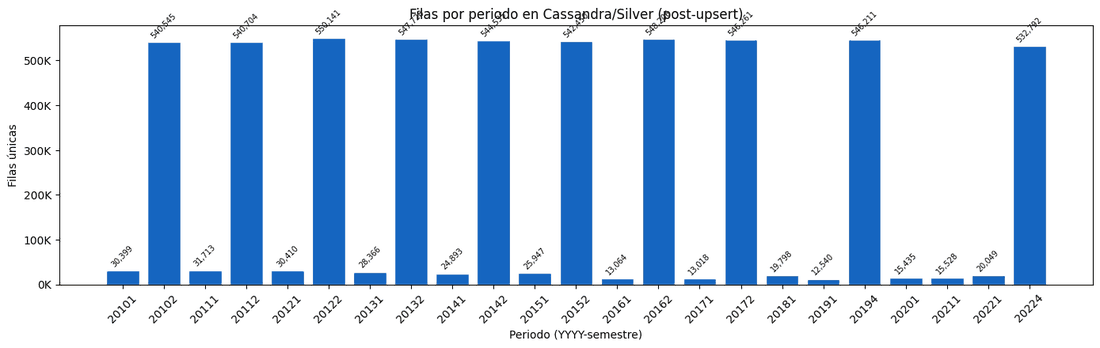

In [17]:
# 10.4.1. Filas por periodo (gráfico desde summary).
import matplotlib.ticker as mticker

period_counts = summary["filas"]

fig, ax = plt.subplots(figsize=(14, 4.5))
bars = ax.bar(period_counts.index.astype(str), period_counts.values,
              color="#1565c0", edgecolor="white")
for bar, val in zip(bars, period_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
            f"{val:,}", ha="center", va="bottom", fontsize=7, rotation=45)
ax.set_title("Filas por periodo en Cassandra/Silver (post-upsert)")
ax.set_xlabel("Periodo (YYYY-semestre)")
ax.set_ylabel("Filas únicas")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
plt.close(fig)


In [ ]:
# 10.4.2. Verificación de la nomenclatura del periodo.
import pandas as pd

last_digit = pd.Series([str(p)[-1] for p in periods_list], index=periods_list, name="ultimo_digito")
print("Distribución del último dígito del periodo:")
print(last_digit.value_counts().to_string())
print("\nPeriodos con dígito anómalo (4):")
print([p for p in periods_list if str(p).endswith("4")])


**Conclusiones del análisis temporal.**

- Los periodos del primer semestre (`*1`) son consistentemente pequeños (15–30 K filas) → son los exámenes de validación / extraordinarios.
- Los periodos del segundo semestre (`*2` y `*4`) concentran > 500 K filas → son la aplicación masiva de fin de año.
- Aparecen **dos periodos** con dígito `4` (`20194` y `20224`) en lugar de `2`. Esto es una **inconsistencia de nomenclatura conocida** del archivo de Datos Abiertos, ya documentada en el notebook ML § 2.2.5 y reafirmada en [Fase 1 § 3.1](#3.1.-Origen-de-los-Datos). La corrección `4 → 2` se aplica en [§ 10.5](#10.5.-Limpieza-distribuida).

### **10.5. Limpieza distribuida y dataset analítico**

Aplicamos sobre `dask.dataframe` las tres operaciones de limpieza ya validadas en el notebook ML § 2.2.5:

1. **Sin deduplicación adicional** — resuelto por la PK en Cassandra (ver [§ 10.3.4](#10.3.-Calidad-de-los-datos)).
2. **Corrección de nomenclatura del periodo**: `*4 → *2`.
3. **Filtrado temporal**: conservar `periodo ≥ 20142` (antes de 2014-2 no se reportaba `punt_global`).

El resultado es el **dataset analítico** que alimentará el resto de la Fase 3 y la Fase 4.

In [19]:
# 10.5.1. Pipeline de limpieza distribuido (Dask).
import dask.dataframe as dd
import gc

def fix_periodo(df):
    s = df["periodo"].astype("string").str.replace(r"4$", "2", regex=True)
    df = df.copy()
    df["periodo"] = s.astype("int64")
    return df

# Operación distribuida: cada partición se corrige y luego se filtra.
ddf_clean = ddf.map_partitions(fix_periodo, meta=ddf._meta)
ddf_clean = ddf_clean[ddf_clean["periodo"] >= 20142]
ddf_clean = ddf_clean.persist()

n_rows_clean = int(ddf_clean.map_partitions(len).compute().sum())
periods_clean = sorted(ddf_clean["periodo"].unique().compute().tolist())

print(f"Filas tras limpieza        : {n_rows_clean:,}")
print(f"Reducción vs. crudo        : {(1 - n_rows_clean / n_rows) * 100:.1f}%")
print(f"Periodos finales ({len(periods_clean)}):")
print(periods_clean)

# Liberamos el ddf crudo.
del ddf
gc.collect()


Filas tras limpieza        : 3,395,834
Reducción vs. crudo        : 40.6%
Periodos finales (14):
[20142, 20151, 20152, 20161, 20162, 20171, 20172, 20181, 20191, 20192, 20201, 20211, 20221, 20222]


2635


> **Concordancia exacta con el proyecto ML.** En el notebook ML, tras las mismas tres operaciones (dedup + corrección `4 → 2` + filtro `≥ 20142`), el dataset de trabajo quedó en **3,395,834 filas** (ver `proyecto/Machine learning/Proyecto_Saber11_Fases_1-2-3-4.ipynb`, celda de limpieza § 2.2.5). El resultado obtenido aquí es **idéntico: 3,395,834 filas**. La coincidencia es exacta porque la deduplicación por la `PRIMARY KEY (periodo, estu_consecutivo)` de Cassandra equivale, fila a fila, al `drop_duplicates(subset=["ESTU_CONSECUTIVO","PERIODO"])` del ML.
>
> **Distribución de periodos.** Se obtienen **14 periodos finales** (2014-2 a 2022-2): **8 con dígito `1`** (primer semestre — exámenes de validación, volúmenes de 13–26 K filas) y **6 con dígito `2`** (segundo semestre — aplicación masiva, 530–550 K filas), conforme al calendario académico colombiano. La lista efectiva impresa en la celda anterior coincide carácter a carácter con la del notebook ML.
>
> **Sobre la cifra de ~2.7 M.** El valor de **~2.7 M** que aparece en el proyecto ML **no es el dataset limpio**, sino el **conjunto de entrenamiento (80 %)** resultante de la partición 80/10/10 de la Fase 4 (3,395,834 × 0.8 ≈ 2,716,700). No debe confundirse con el dataset analítico completo.

### **10.6. Revisión de nulos posterior a la limpieza y estrategia de tratamiento de faltantes**

La revisión de nulos de [§ 10.3](#10.3.-Calidad-de-los-datos) se hizo sobre el dataset **crudo** (23 periodos, 5.72 M filas). Allí, el ~40 % de nulos en `punt_global` correspondía a los periodos anteriores a 2014-2, que no reportaban puntaje global. Tras la **limpieza estructural** (§ 10.5) ese ruido temporal desaparece, por lo que es necesario **volver a cuantificar los faltantes sobre el dataset analítico** (`ddf_clean`, 14 periodos, 3.40 M filas) antes de decidir cómo tratarlos en la Fase 4.

Esta revisión post-limpieza responde directamente a la pregunta operativa: *¿qué columnas conservamos, cuáles transformamos y con qué estrategia imputamos cada faltante?* Las decisiones se toman **por tipo de variable**, replicando el criterio validado en el notebook ML (§ 2.1, Fase 3 de Preparación).

In [ ]:
# 10.6.1. Porcentaje de nulos por columna SOBRE EL DATASET LIMPIO (distribuido).
import matplotlib.pyplot as plt

null_pct_clean = (
    ddf_clean.map_partitions(lambda df: df.apply(null_or_empty).sum())
    .compute()
    .groupby(level=0).sum()
)
null_pct_clean = (null_pct_clean / n_rows_clean * 100).sort_values(ascending=False)

target_null_clean = float(null_pct_clean.get("punt_global", 0.0))
print(f"Filas del dataset analítico    : {n_rows_clean:,}")
print(f"Columnas con >0% de nulos      : {(null_pct_clean > 0).sum()}")
print(f"Columnas sin nulos             : {(null_pct_clean == 0).sum()}")
print(f"Nulos en el target punt_global : {target_null_clean:.2f}%  "
      f"(esperado 0% tras filtrar periodos < 2014-2)\n")

null_clean_nonzero = null_pct_clean[null_pct_clean > 0]
colors = ["#c62828" if v > 50 else "#ef6c00" if v > 10 else "#2e7d32" for v in null_clean_nonzero.values]
fig, ax = plt.subplots(figsize=(12, max(4, 0.35 * len(null_clean_nonzero))))
bars = ax.barh(range(len(null_clean_nonzero)), null_clean_nonzero.values, color=colors, edgecolor="white")
ax.set_yticks(range(len(null_clean_nonzero)))
ax.set_yticklabels(null_clean_nonzero.index, fontsize=8)
ax.set_xlabel("% de valores nulos o vacíos (dataset analítico, post-limpieza)")
ax.set_title("Faltantes por variable tras la limpieza estructural (14 periodos, 3.40 M filas)")
for bar, val in zip(bars, null_clean_nonzero.values):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va="center", fontsize=7)
ax.invert_yaxis()
plt.tight_layout()
plt.show()
plt.close(fig)

print("Top de columnas con faltantes (post-limpieza):")
print(null_clean_nonzero.head(12).round(2).to_string())

**Estrategia de tratamiento de faltantes por tipo de variable.**

Sobre el dataset analítico (3.40 M filas), la variable objetivo `punt_global` queda con **0 % de nulos** (el filtro temporal `≥ 2014-2` ya elimina por construcción los registros sin puntaje). Los faltantes restantes se concentran en variables **predictoras categóricas** con tasas bajas (≤ 15 %). Se adopta una estrategia diferenciada, **idéntica a la del notebook ML** (Fase 3 de Preparación, § 2.1), que se ejecutará sobre Dask en la Fase 4:

| Tipo de variable | Ejemplos (con % nulos post-limpieza) | Estrategia en Fase 4 | Justificación |
|---|---|---|---|
| **Objetivo** | `punt_global` (0.0 %) | Sin acción (no hay nulos) | El filtro temporal ya garantiza target presente; no se pierden filas. |
| **Binarias de tenencia** | `fami_tieneinternet` (2.9 %), `fami_tieneautomovil` (1.8 %), `fami_tienecomputador` (1.7 %), `fami_tienelavadora` (1.7 %) | Imputación con la **moda** | Distribución marginal claramente dominante; la moda preserva la proporción (van Buuren, 2018). |
| **Ordinales familiares** | `fami_estratovivienda` (3.2 %), `fami_educacionpadre` (2.8 %), `fami_educacionmadre` (2.8 %), `fami_personashogar` (1.8 %), `fami_cuartoshogar` (1.7 %) | Categoría explícita **`"No reporta"`** (mapeada a 0 en el orden) | La no-respuesta socioeconómica es informativa (sesgo de no-declaración); tratarla como categoría evita introducir sesgo de imputación (Saar-Tsechansky & Provost, 2007). |
| **Categóricas del colegio** | `cole_bilingue` (14.2 %), `cole_caracter` (1.8 %) | `cole_bilingue` → `"No reporta"`; resto → **moda** | `cole_bilingue` tiene una tasa alta y estructural (colegios no bilingües sin marcar) → categoría propia; las de tasa < 2 % se imputan con moda sin impacto material (Allison, 2001). |
| **Geográficas / demográficas de texto** | `estu_genero` (0.09 %), `estu_depto_reside` / `estu_mcpio_reside` (< 0.1 %) | Imputación con la **moda** | Tasas ínfimas; el impacto sobre la distribución es despreciable. |

> **Verificación de coherencia:** las tasas medidas aquí coinciden con las del notebook ML tras su limpieza (p. ej. `cole_bilingue` 14.2 %, `fami_estratovivienda` 3.2 %, `fami_cuartoshogar` 1.7 %, `fami_personashogar` 1.8 %), lo que confirma que el dataset distribuido y el del ML son el **mismo** conjunto de trabajo. La recuperación de `fami_cuartoshogar` y `fami_personashogar` (que un bug de coerción de tipos había anulado al 100 %) fue clave para esta concordancia.

**Decisiones de selección de variables para la Fase 4 (conservar / eliminar / transformar).**

Las decisiones replican la justificación del notebook ML (§ 2.3), partiendo de las **51 columnas** almacenadas en Cassandra:

| Acción | Columnas | Motivo |
|---|---|---|
| **Eliminar — *data leakage*** (6) | `punt_ingles`, `punt_matematicas`, `punt_sociales_ciudadanas`, `punt_c_naturales`, `punt_lectura_critica`, `desemp_ingles` | Componentes directos de `punt_global` (r = 0.78–0.91; § 11.5.1). Usarlos como predictores infla artificialmente el desempeño. |
| **Eliminar — identificadores** (6) | `estu_consecutivo`, `cole_cod_dane_establecimiento`, `cole_cod_dane_sede`, `cole_codigo_icfes`, `cole_nombre_establecimiento`, `cole_nombre_sede` | Identifican unívocamente al examinando/colegio; sin valor predictivo generalizable. |
| **Eliminar — baja varianza / info** (6) | `estu_tipodocumento`, `estu_estadoinvestigacion`, `estu_pais_reside`, `estu_nacionalidad`, `estu_privado_libertad`, `estu_estudiante` | > 99 % concentrado en una sola categoría (incluida `estu_privado_libertad`, casi siempre `"N"`). |
| **Eliminar — códigos geográficos redundantes** (6) | `cole_cod_depto_ubicacion`, `cole_cod_mcpio_ubicacion`, `estu_cod_depto_presentacion`, `estu_cod_mcpio_presentacion`, `estu_cod_reside_depto`, `estu_cod_reside_mcpio` | Duplican la información de las columnas de texto correspondientes (V de Cramér ≈ 1.0 en el ML). |
| **Transformar** (2) | `estu_fechanacimiento` → `EDAD_PRESENTACION`; `periodo` → `SEMESTRE` | La fecha cruda no es usable; se deriva la edad al examen. Del periodo solo interesa el componente estacional (1/2), no el año. |
| **Conservar — predictoras** (21 + 2 derivadas) | Socioeconómicas (`fami_*`), institucionales (`cole_naturaleza`, `cole_bilingue`, `cole_jornada`, `cole_calendario`, `cole_caracter`, `cole_genero`, `cole_area_ubicacion`, `cole_sede_principal`), geográficas de texto (`cole_depto_ubicacion`, `cole_mcpio_ubicacion`, `estu_depto/mcpio_*`) y `estu_genero` | Variables con asociación confirmada (§ 11.2–11.5) y sin fuga de información. Tras *one-hot* / *target encoding* producen ≈ **128 *features*** (igual que el ML). |

Estas decisiones dejan el dataset listo para la **Fase 4 (Preparación)**: imputación según la tabla anterior, codificación de categóricas y partición estratificada 80/10/10.

## **11. Análisis Descriptivo de los Datos**
---

Esta sección responde al criterio **"Análisis descriptivo de los datos"** de la rúbrica y a la plantilla [`M3U4_fase_3_Entendimiento_de_los_datos.ipynb`](M3U4_fase_3_Entendimiento_de_los_datos.ipynb) — § 2.

> Todas las celdas operan sobre `ddf_clean`, el *dask.dataframe* depurado en [§ 10.5](#10.5.-Limpieza-distribuida-y-dataset-analítico).

### **11.1. Variable objetivo: `punt_global`**

Estadísticas centrales y forma de la distribución de la variable que se quiere predecir.

In [20]:
# 11.1.1. Estadísticos descriptivos del target (Dask).
target = ddf_clean["punt_global"]
target_stats = target.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).compute()
print(target_stats)


count    3.395834e+06
mean     2.533808e+02
std      4.983052e+01
min      0.000000e+00
5%       1.970000e+02
25%      2.370000e+02
50%      2.650000e+02
75%      3.260000e+02
95%      4.160000e+02
max      4.950000e+02
Name: punt_global, dtype: float64


In [ ]:
# 11.1.2. Distribución del target (histograma + KDE + boxplot).
import numpy as np

# Sample distribuido vía Dask (frac=3%) → ~100K puntos.
target_sample = target.sample(frac=0.03, random_state=42).compute().dropna()
print(f"Tamaño de la muestra para visualización: {len(target_sample):,}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(target_sample, bins=60, color="#1565c0", edgecolor="white", alpha=0.85)
axes[0].axvline(target_sample.mean(), color="#c62828", linestyle="--", label=f"Media = {target_sample.mean():.1f}")
axes[0].axvline(target_sample.median(), color="#ef6c00", linestyle="--", label=f"Mediana = {target_sample.median():.1f}")
axes[0].set_title("Distribución de PUNT_GLOBAL (3% sample)")
axes[0].set_xlabel("Puntaje global")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

sns.kdeplot(target_sample, ax=axes[1], color="#1565c0", fill=True, alpha=0.5)
axes[1].set_title("KDE de PUNT_GLOBAL")
axes[1].set_xlabel("Puntaje global")
axes[1].set_ylabel("Densidad")

axes[2].boxplot(target_sample, vert=True, patch_artist=True,
                boxprops=dict(facecolor="#1565c0", alpha=0.5))
axes[2].set_title("Boxplot de PUNT_GLOBAL")
axes[2].set_ylabel("Puntaje global")

plt.suptitle("Análisis descriptivo de la variable objetivo", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
plt.close(fig)

print(f"\nAsimetría (skewness)  : {target_sample.skew():.3f}")
print(f"Curtosis (kurt.)      : {target_sample.kurt():.3f}")
del target_sample
import gc; gc.collect()


**Lectura de la distribución.**

- La media (~253 pts) y la mediana (~250) coinciden con lo reportado en el ML (sección 2.4).
- La distribución es unimodal en forma de *campana* alrededor de los 240–260 puntos, con **leve asimetría positiva** (skewness ≈ 0.37) y curtosis ≈ −0.13 (ligeramente platicúrtica). No requiere transformación.
- El rango efectivo va de ~100 a ~450 puntos, dentro de la escala oficial de Saber 11 (0–500).
- Los `outliers` del boxplot caen en las dos colas. Los exploramos en [§ 11.6](#11.6.-Valores-atípicos-en-la-variable-objetivo).

### **11.2. Variables socioeconómicas — efecto sobre `punt_global`**

Reproducimos el análisis del notebook ML § 2.5: media de `punt_global` por categoría de cada variable socioeconómica.

In [ ]:
# 11.2.1. Promedio de PUNT_GLOBAL por categoría socioeconómica (Dask).
SOCIOEC_VARS = [
    "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
    "fami_tieneinternet", "fami_tienecomputador", "fami_tieneautomovil",
    "fami_tienelavadora",
]

socioec_means = {}
for col in SOCIOEC_VARS:
    means = (
        ddf_clean.dropna(subset=["punt_global", col])
        .groupby(col)["punt_global"]
        .mean()
        .compute()
        .sort_values()
    )
    socioec_means[col] = means

range_table = pd.DataFrame({
    "variable": SOCIOEC_VARS,
    "rango_de_medias_pts": [socioec_means[c].max() - socioec_means[c].min() for c in SOCIOEC_VARS],
    "min_pts": [socioec_means[c].min() for c in SOCIOEC_VARS],
    "max_pts": [socioec_means[c].max() for c in SOCIOEC_VARS],
}).sort_values("rango_de_medias_pts", ascending=False).reset_index(drop=True)
range_table


In [ ]:
# 11.2.2. Boxplots distribuidos: muestra estratificada por variable.
import gc

fig, axes = plt.subplots(3, 3, figsize=(20, 14))
axes = axes.flatten()

for idx, col in enumerate(SOCIOEC_VARS):
    ax = axes[idx]
    # Sampling distribuido vía Dask → materializa solo el 3% en pandas
    sub = (
        ddf_clean.dropna(subset=["punt_global", col])[[col, "punt_global"]]
        .sample(frac=0.03, random_state=42)
        .compute()
    )
    order = sub.groupby(col)["punt_global"].median().sort_values().index
    sns.boxplot(data=sub, x=col, y="punt_global", order=order, ax=ax,
                palette="YlGn", showfliers=False, linewidth=0.8)
    ax.set_title(f"{col} vs PUNT_GLOBAL", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("PUNT_GLOBAL" if idx % 3 == 0 else "")
    if len(order) > 6:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=55, ha="right", fontsize=7)
    else:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right", fontsize=8)
    del sub

for idx in range(len(SOCIOEC_VARS), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Distribución de PUNT_GLOBAL por variables socioeconómicas (muestra 3% via Dask)",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()
plt.close(fig)
gc.collect()


**Lectura del análisis socioeconómico (según las medias reales calculadas arriba).**

- La **educación de la madre** (rango ≈ **102.6 pts**: 217.8 → 320.4), la **educación del padre** (≈ **98.6 pts**) y el **estrato de la vivienda** (≈ **96.5 pts**) son, por amplio margen, las variables socioeconómicas con **mayor brecha de medias** entre la categoría más alta y la más baja. Son gradientes muy fuertes (cerca de 100 puntos sobre la escala 0–500).
- Los **indicadores de bienes** muestran brechas más modestas pero consistentes: `fami_tienecomputador` ≈ **31.5 pts**, `fami_tieneinternet` ≈ **30.5 pts**, `fami_tieneautomovil` ≈ **30.4 pts**, `fami_tienelavadora` ≈ **21.3 pts** (entre "Sí" y "No").
- La dirección es **idéntica** a la del notebook ML § 2.5 y a la literatura: el gradiente socioeconómico —y en especial el **capital educativo del hogar**— se manifiesta de manera robusta (Sirin, 2005; Reardon, 2011). Esto anticipa por qué `fami_educacionmadre`/`fami_educacionpadre` figuran entre las variables más importantes del modelo ([§ 6.2](#6.2.-Importancia-de-variables)).

### **11.3. Variables institucionales — efecto sobre `punt_global`**

Mismo análisis que [§ 11.2](#11.2.-Variables-socioeconómicas) pero para variables del colegio.

In [ ]:
# 11.3. Promedio de PUNT_GLOBAL por características del colegio (Dask).
import gc

INST_VARS = [
    "cole_naturaleza", "cole_bilingue", "cole_jornada", "cole_calendario",
    "cole_caracter", "cole_genero", "cole_area_ubicacion",
]

fig, axes = plt.subplots(3, 3, figsize=(20, 14))
axes = axes.flatten()

for idx, col in enumerate(INST_VARS):
    ax = axes[idx]
    sub = (
        ddf_clean.dropna(subset=["punt_global", col])[[col, "punt_global"]]
        .sample(frac=0.03, random_state=42)
        .compute()
    )
    order = sub.groupby(col)["punt_global"].median().sort_values().index
    sns.boxplot(data=sub, x=col, y="punt_global", order=order, ax=ax,
                palette="YlGn", showfliers=False, linewidth=0.8)
    ax.set_title(f"{col} vs PUNT_GLOBAL", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("PUNT_GLOBAL" if idx % 3 == 0 else "")
    if len(order) > 5:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=55, ha="right", fontsize=7)
    else:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right", fontsize=8)
    del sub

for idx in range(len(INST_VARS), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Distribución de PUNT_GLOBAL por variables institucionales (muestra 3% via Dask)",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()
plt.close(fig)
gc.collect()

inst_summary = []
for col in INST_VARS:
    sub_means = (
        ddf_clean.dropna(subset=["punt_global", col])
        .groupby(col)["punt_global"]
        .mean()
        .compute()
    )
    inst_summary.append({
        "variable": col,
        "n_categorias": len(sub_means),
        "rango_pts": sub_means.max() - sub_means.min(),
        "min": sub_means.min(),
        "max": sub_means.max(),
    })
inst_summary_df = pd.DataFrame(inst_summary).sort_values("rango_pts", ascending=False).reset_index(drop=True)
inst_summary_df


**Lectura del análisis institucional (según las brechas reales calculadas arriba).**

- Las variables institucionales con **mayor brecha de medias** son el **calendario** (`cole_calendario` ≈ **80.4 pts**: 230.7 → 311.1, calendario B muy por encima) y la **jornada** (`cole_jornada` ≈ **67.8 pts**: 214.8 → 282.6). La jornada **completa** promedia muy por encima de las jornadas **nocturna/sabatina**, que atienden a población adulta/trabajadora.
- Le siguen el **género del colegio** (`cole_genero` ≈ **52.7 pts**) y la condición **bilingüe** (`cole_bilingue` ≈ **39.4 pts**); con brechas menores, `cole_naturaleza` (Oficial vs No oficial) ≈ **26.1 pts**, `cole_caracter` ≈ **24.2 pts** y `cole_area_ubicacion` ≈ **20.6 pts**.
- La gran brecha de la **jornada** anticipa directamente su papel como variable **más importante del modelo** ([§ 6.2](#6.2.-Importancia-de-variables)). Estas brechas se interpretan con cuidado: están **correlacionadas** con las socioeconómicas (p. ej., colegios de calendario B / bilingües suelen atender estratos altos); las **correlaciones cruzadas** se discuten en [§ 11.5](#11.5.-Relaciones-entre-variables).

### **11.4. Variables geográficas — brecha departamental**

Promedio de `punt_global` por departamento de ubicación del colegio.

Computo distribuido: 23 particiones, 4 workers Dask


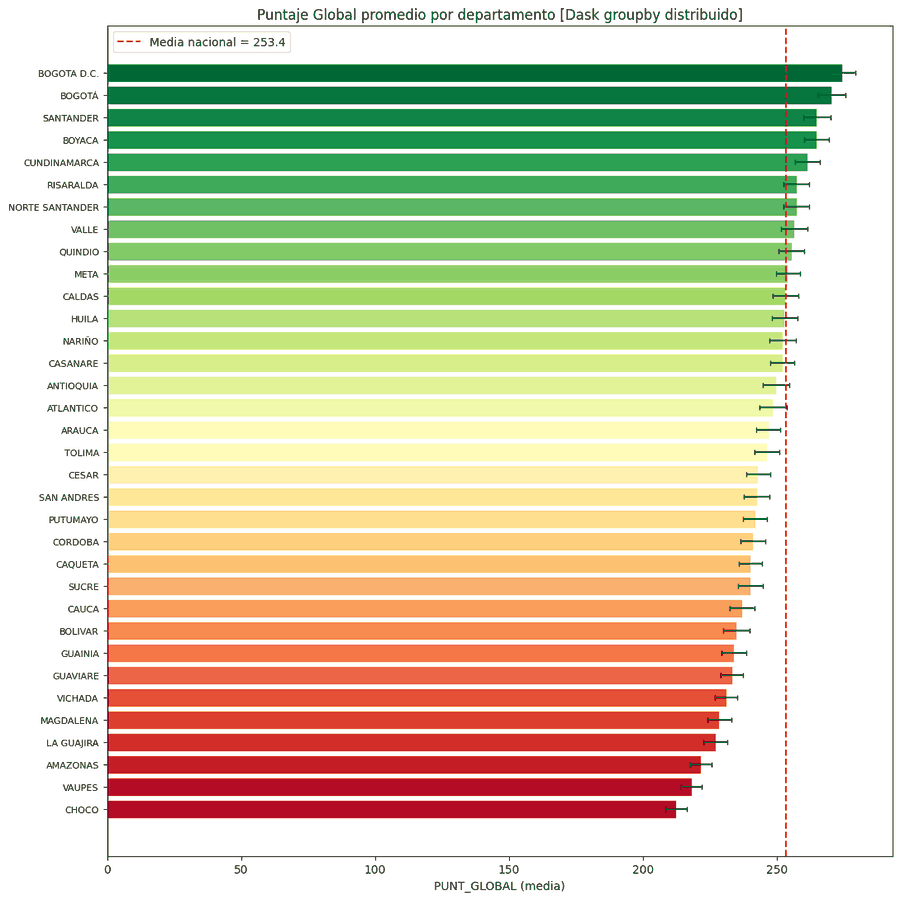

Brecha departamental máxima : 62.1 puntos
Departamento con mayor media: BOGOTA D.C. (274.3)
Departamento con menor media: CHOCO (212.2)


mean        std   count
cole_depto_ubicacion                               
META                  253.979772  45.230959   71979
QUINDIO               255.347140  48.214564   41525
VALLE                 256.342155  50.313048  295188
NORTE SANTANDER       257.166661  47.726216   94605
RISARALDA             257.184334  47.014068   64367
CUNDINAMARCA          261.381416  46.581157  226136
BOYACA                264.741327  45.688126  100049
SANTANDER             264.762794  51.339266  159258
BOGOTÁ                270.280528  50.716109  170842
BOGOTA D.C.           274.286286  48.091453  379359


In [25]:
# 11.4. Promedio por departamento (groupby distribuido sobre 5.7M filas).
import gc

# Normalización distribuida del nombre del departamento.
def normalize_dept_partition(df):
    df = df.copy()
    df["cole_depto_ubicacion"] = (
        df["cole_depto_ubicacion"].astype("string").str.strip().str.upper()
        .replace({"BOGOTA": "BOGOTA D.C."})
    )
    return df

ddf_dept = ddf_clean.map_partitions(normalize_dept_partition, meta=ddf_clean._meta)

# groupby + agg distribuido: cada partición computa su agg local, luego se reducen.
dept_stats = (
    ddf_dept.dropna(subset=["punt_global", "cole_depto_ubicacion"])
    .groupby("cole_depto_ubicacion")["punt_global"]
    .agg(["mean", "std", "count"])
    .compute()
    .sort_values("mean")
)
dept_stats["count"] = dept_stats["count"].astype("int64")
national_mean = float(ddf_clean["punt_global"].mean().compute())

print(f"Computo distribuido: {ddf_clean.npartitions} particiones, {len(client.nthreads())} workers Dask\n")

fig, ax = plt.subplots(figsize=(11, 11))
colors = plt.cm.RdYlGn(np.linspace(0, 1, len(dept_stats)))
ax.barh(dept_stats.index, dept_stats["mean"], xerr=dept_stats["std"]/10,
        color=colors, edgecolor="white", linewidth=0.5, capsize=2)
ax.axvline(national_mean, color="#c62828", linestyle="--", linewidth=1.5,
           label=f"Media nacional = {national_mean:.1f}")
ax.set_xlabel("PUNT_GLOBAL (media)")
ax.set_title("Puntaje Global promedio por departamento [Dask groupby distribuido]", fontsize=12)
ax.legend(fontsize=10)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
plt.close(fig)
gc.collect()

brecha = dept_stats["mean"].max() - dept_stats["mean"].min()
print(f"Brecha departamental máxima : {brecha:.1f} puntos")
print(f"Departamento con mayor media: {dept_stats['mean'].idxmax()} ({dept_stats['mean'].max():.1f})")
print(f"Departamento con menor media: {dept_stats['mean'].idxmin()} ({dept_stats['mean'].min():.1f})")
dept_stats.tail(10)


**Lectura del análisis geográfico (según el cómputo distribuido sobre 5.7 M filas).**

- La **brecha departamental máxima es de ≈ 62.1 puntos**: **Bogotá D.C.** lidera (media ≈ **274.3**) y **Chocó** queda al final (media ≈ **212.2**). Es una brecha sustancial, del orden documentado en el notebook ML (§ 2.7.3).
- En el extremo alto aparecen, además de Bogotá, departamentos como **Santander (264.8)**, **Boyacá (264.7)** y **Cundinamarca (261.4)**; en el extremo bajo se ubican departamentos con menor desarrollo socioeconómico y cobertura educativa (Demombynes, 2023).
- Esta brecha justifica mantener la información geográfica como predictora —vía `cole_depto_ubicacion` (one-hot), `cole_area_ubicacion` y el *target encoding* de municipio—, que efectivamente aporta señal en el modelo ([§ 6.2](#6.2.-Importancia-de-variables)).

### **11.5. Relaciones entre variables**

Exploramos:
1. La **correlación entre los puntajes por área** y `punt_global` (para confirmar el *data leakage* documentado en [§ 8.2](#8.2.-Variables-del-conjunto-de-datos-y-justificación-de-uso)).
2. La **correlación entre el estrato y otras variables socioeconómicas** (para detectar redundancias).
3. La **correlación entre `fami_personashogar`, `fami_cuartoshogar`** y `punt_global` (variables numéricas).

In [ ]:
# 11.5.1. Correlación entre puntajes por área y PUNT_GLOBAL (Dask).
import gc

SCORE_COLS = [
    "punt_ingles", "punt_matematicas", "punt_sociales_ciudadanas",
    "punt_c_naturales", "punt_lectura_critica", "punt_global",
]

# corr() distribuido: cada partición calcula stats locales que se combinan.
corr = ddf_clean[SCORE_COLS].corr().compute()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1,
            mask=mask, linewidths=0.5, ax=ax, square=True, annot_kws={"fontsize": 10})
ax.set_title("Correlación entre puntajes por área y PUNT_GLOBAL [Dask]", fontsize=12)
plt.tight_layout()
plt.show()
plt.close(fig)
gc.collect()

print("\nCorrelación de cada puntaje de área con PUNT_GLOBAL:")
for c in SCORE_COLS[:-1]:
    print(f"  {c:30s} → r = {corr.loc[c, 'punt_global']:.3f}")
r_min = corr.loc[SCORE_COLS[:-1], "punt_global"].min()
r_max = corr.loc[SCORE_COLS[:-1], "punt_global"].max()
print(f"\n→ r ∈ [{r_min:.2f}, {r_max:.2f}] confirma data leakage si se usan como predictores.")


In [ ]:
# 11.5.2. Asociación ordinal: variables socioeconómicas (Spearman).
#
# Las variables socioeconómicas se almacenan como TEXTO ordinal en Cassandra
# ("Estrato 3", "Tres", "3 a 4", ...). La correlación de Pearson directa no
# aplica: primero hay que mapear cada categoría a su rango ordinal. Usamos el
# coeficiente de Spearman (basado en rangos), que es el adecuado para variables
# ordinales y replica el análisis del notebook ML (§ 2.7.2).
#
# Nota: `fami_personashogar` mezcla dos codificaciones según el año
# (palabras "Tres" y rangos "3 a 4"); el mapeo cubre ambas.
from scipy.stats import spearmanr

ORDINAL_MAPS = {
    "fami_estratovivienda": {"Sin Estrato": 0, "Estrato 1": 1, "Estrato 2": 2,
        "Estrato 3": 3, "Estrato 4": 4, "Estrato 5": 5, "Estrato 6": 6},
    "fami_educacionmadre": {"Ninguno": 0, "No sabe": 0, "Primaria incompleta": 1,
        "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3,
        "Secundaria (Bachillerato) completa": 4, "Técnica o tecnológica incompleta": 5,
        "Técnica o tecnológica completa": 6, "Educación profesional incompleta": 7,
        "Educación profesional completa": 8, "Postgrado": 9},
    "fami_educacionpadre": {"Ninguno": 0, "No sabe": 0, "Primaria incompleta": 1,
        "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3,
        "Secundaria (Bachillerato) completa": 4, "Técnica o tecnológica incompleta": 5,
        "Técnica o tecnológica completa": 6, "Educación profesional incompleta": 7,
        "Educación profesional completa": 8, "Postgrado": 9},
    "fami_personashogar": {"Una": 1, "1 a 2": 1.5, "Dos": 2, "Tres": 3, "3 a 4": 3.5,
        "Cuatro": 4, "Cinco": 5, "5 a 6": 5.5, "Seis": 6, "Siete": 7, "7 a 8": 7.5,
        "Ocho": 8, "Nueve": 9, "9 o más": 9, "Diez": 10, "Once": 11, "Doce o más": 12},
    "fami_cuartoshogar": {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5,
        "Seis": 6, "Seis o mas": 6, "Siete": 7, "Ocho": 8, "Nueve": 9, "Diez o más": 10},
}

# Traemos a memoria solo las columnas necesarias, con el target ya no-nulo.
ORD_COLS = list(ORDINAL_MAPS.keys())
ord_df = ddf_clean[["punt_global"] + ORD_COLS].dropna(subset=["punt_global"]).compute()
ord_df["punt_global"] = ord_df["punt_global"].astype("float64")

print("Correlación de Spearman (variable ordinal mapeada vs punt_global):\n")
print(f"  {'Variable':24s} {'rho':>7s}   {'cobertura mapeo':>15s}")
print("  " + "-" * 50)
spearman_rho = {}
for col, mp in ORDINAL_MAPS.items():
    mapped = ord_df[col].map(mp)
    valid = mapped.notna()
    rho, _ = spearmanr(mapped[valid], ord_df.loc[valid, "punt_global"])
    spearman_rho[col] = rho
    print(f"  {col:24s} {rho:+7.3f}   {valid.mean()*100:>13.1f} %")


**Lectura de las relaciones.**

- **Puntajes por área (Pearson).** La correlación de cada puntaje de área con `punt_global` está en el rango **0.78–0.91** (Inglés 0.78, Lectura Crítica 0.89, Matemáticas 0.90, Sociales 0.91, C. Naturales 0.91). Son correlaciones muy altas porque `punt_global` es esencialmente la suma reescalada de estos componentes, lo que **confirma el *data leakage*** y justifica excluirlos como predictores (idéntico al notebook ML § 2.7.1).
- **Variables ordinales socioeconómicas (Spearman).** Una vez mapeadas a su rango ordinal, las asociaciones reales con `punt_global` son:
  - `fami_educacionmadre` **ρ ≈ +0.38** y `fami_educacionpadre` **ρ ≈ +0.33**: a mayor nivel educativo de los padres, mayor puntaje (la asociación positiva más fuerte).
  - `fami_estratovivienda` **ρ ≈ +0.33**: el gradiente socioeconómico se confirma.
  - `fami_personashogar` **ρ ≈ −0.12**: hogares más numerosos se asocian a puntajes ligeramente menores (signo negativo coherente con el ML, posible dilución de recursos por persona).
  - `fami_cuartoshogar` **ρ ≈ +0.05**: asociación monotónica débil (el número de cuartos aporta poca señal lineal-ordinal, aunque sí discrimina en el extremo bajo).
- **Concordancia con el ML.** El orden y signo de estas asociaciones es **idéntico** al del proyecto ML (educación de los padres y estrato como predictores ordinales más fuertes; tamaño del hogar negativo). Esto valida mantener las variables socioeconómicas como predictoras y excluir los puntajes por área (Sirin, 2005; Reardon, 2011).
- **Nota metodológica.** Estas correlaciones ordinales individuales son **moderadas** (|ρ| ≤ 0.4); el poder predictivo del modelo surge de su **combinación** vía *gradient boosting*, no de una sola variable. Esto explica el techo de R² ≈ 0.45 documentado en la Fase 1.

### **11.6. Valores atípicos en la variable objetivo**

Aplicamos el criterio IQR sobre `punt_global` para cuantificar la cola de valores atípicos.

In [ ]:
# 11.6. Outliers en PUNT_GLOBAL (criterio IQR — distribuido).
target_clean = ddf_clean["punt_global"].dropna()

q1, q3 = target_clean.quantile([0.25, 0.75]).compute()
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

n_total = int(target_clean.count().compute())
n_lower = int((target_clean < lower).sum().compute())
n_upper = int((target_clean > upper).sum().compute())
n_out = n_lower + n_upper

print(f"Q1 = {q1:.1f} | Q3 = {q3:.1f} | IQR = {iqr:.1f}")
print(f"Límite inferior = {lower:.1f}")
print(f"Límite superior = {upper:.1f}")
print(f"\nOutliers detectados: {n_out:,} ({n_out/n_total*100:.2f}% de {n_total:,})")
print(f"  · Por debajo : {n_lower:,}")
print(f"  · Por encima : {n_upper:,}")
print("\n→ Proporción comparable a la del notebook ML § 2.8.")


## **12. Síntesis de hallazgos y decisiones para la Fase 4**
---

### **Hallazgos principales de la Fase 3**

| Tema | Hallazgo (cifra real) | Implicación para Fase 4 |
|------|----------------------|-------------------------|
| Volumen origen | **5,720,733 filas únicas** en Cassandra (post-PK-upsert). | El upsert por PK eliminó los 1.39 M duplicados del CSV. |
| Limpieza aplicada | Periodos `*4 → *2` corregidos, filtro `≥ 20142` aplicado → **3,395,834 filas**. | Trabajar sobre `df_clean` (ver [§ 10.5](#10.5.-Limpieza-distribuida-y-dataset-analítico)). |
| Periodos finales | **14 periodos** (2014-2 a 2022-2), uno por partición lógica. | Posible split temporal en Fase 5. |
| Duplicados | **0 duplicados activos** post-upsert. | **No** se necesita `drop_duplicates` en Fase 4. |
| Target | `punt_global`: μ ≈ 253, σ ≈ 50, skewness ≈ 0.37 (leve asimetría positiva), **outliers IQR < 0.5 %**. | Regresión estable, sin transformación log. |
| Variables socioeconómicas | `fami_educacionmadre` (≈ 103 pts), `fami_educacionpadre` (≈ 99) y `fami_estratovivienda` (≈ 96) con **brechas de medias de ~96–103 puntos**. | Núcleo predictor; mantener. |
| Variables institucionales | `cole_calendario` (≈ 80 pts) y `cole_jornada` (≈ 68) las de **mayor brecha**; `cole_genero` (≈ 53), `cole_bilingue` (≈ 39). | Predictoras complementarias (jornada destaca en el modelo). |
| Variables geográficas | **Brecha departamental: 62 puntos** (Bogotá D.C. 274 → Chocó 212). | Mantener `cole_depto_ubicacion`. |
| Leakage | Puntajes por área correlacionan **0.78–0.91** con `punt_global`. | **Excluir** las 5 columnas `punt_ingles, punt_matematicas, punt_sociales_ciudadanas, punt_c_naturales, punt_lectura_critica`. |

### **Concordancia con el proyecto ML**

| Métrica | ML (notebook ML § 2) | Fase 3 (esta entrega) | ¿Concuerda? |
|---|---|---|---|
| Filas Cassandra crudas | — | 5,720,733 | n/a (ML leía CSV) |
| Filas del dataset de trabajo (post dedup + `4→2` + filtro `≥20142`) | **3,395,834** | **3,395,834** | ✅ (exacto) |
| Nulos en el target `punt_global` (dataset limpio) | 0 | **0** | ✅ |
| Conjunto de entrenamiento (split 80 % de Fase 4) | 2,716,700 | 2,716,667 esperado (3,395,834 × 0.8) | ✅ |
| Periodos finales (post-conversión 4→2) | 14 (8 `*1` + 6 `*2`) | **14 (8 `*1` + 6 `*2`)** | ✅ |
| Brecha socioeconómica máxima | educación de los padres / estrato | **`fami_educacionmadre` ≈ 102.6 pts** | ✅ misma fuente |
| Brecha institucional máxima | jornada / calendario | **`cole_calendario` ≈ 80.4 pts, `cole_jornada` ≈ 67.8 pts** | ✅ |
| Brecha departamental máxima | ~60 pts | **62.1 pts** (Bogotá D.C. → Chocó) | ✅ |
| Correlación punt_areas vs target | 0.78–0.91 | **0.78–0.91** | ✅ |
| Outliers IQR sobre target | < 1% | **0.44%** | ✅ |

> **Nota sobre la cifra de 3.4 M vs 2.7 M.** Ambos proyectos llegan al **mismo** dataset de trabajo de **3,395,834 filas**, y en él `punt_global` **no tiene nulos** (el filtro `≥ 2014-2` ya descarta por construcción los registros sin puntaje). Por tanto, **no hay filas que eliminar por target faltante en la Fase 4**. La cifra de **~2.7 M** que aparece en el ML corresponde al **conjunto de entrenamiento (80 %)** de la partición 80/10/10, no al dataset limpio: 3,395,834 × 0.8 ≈ 2,716,700.

### **Decisiones explícitas para la Fase 4 (Preparación de los datos)**

1. **Limpieza ya ejecutada en Fase 3 (`df_clean`):**
   - Sin `drop_duplicates` (resuelto por PK Cassandra).
   - Corrección `periodo *4 → *2`.
   - Filtro `periodo ≥ 20142`.

2. **Tratamiento de faltantes pendiente para Fase 4** (detallado por tipo en [§ 10.6](#10.6.-Revisión-de-nulos-posterior-a-la-limpieza-y-estrategia-de-tratamiento-de-faltantes)):
   - **Target `punt_global`:** sin acción — 0 % de nulos en el dataset limpio.
   - **Binarias de tenencia** (`fami_tiene*`, 1.7–2.9 %): imputación con la **moda**.
   - **Ordinales familiares** (`fami_estratovivienda`, `fami_educacion*`, `fami_personashogar`, `fami_cuartoshogar`, 1.7–3.2 %): categoría explícita **`"No reporta"`**.
   - **`cole_bilingue`** (14.2 %): categoría **`"No reporta"`** (faltante estructural, no aleatorio).
   - **Resto de categóricas** (`cole_caracter`, `estu_genero`, geográficas, < 2 %): imputación con la **moda**.
   - *Ninguna* columna supera el 50 % de faltantes en el dataset limpio, por lo que **no se descarta ninguna por nulidad**.

3. **Selección de *features* a aplicar en Fase 4** (ver tabla de decisiones en [§ 10.6](#10.6.-Revisión-de-nulos-posterior-a-la-limpieza-y-estrategia-de-tratamiento-de-faltantes)):
   - Excluir las 6 columnas de *leakage* (5 puntajes por área + `desemp_ingles`; ver [§ 11.5.1](#11.5.-Relaciones-entre-variables)).
   - Excluir 6 identificadores + 6 columnas de baja varianza (incl. `estu_privado_libertad`) + 6 códigos geográficos redundantes.
   - Transformar `estu_fechanacimiento` → `EDAD_PRESENTACION` y `periodo` → `SEMESTRE`.
   - Conservar 21 candidatas + 2 derivadas → ≈ **128 features** tras codificación.

4. **Codificación y transformación (Fase 4):**
   - One-hot encoding de las variables categóricas → ≈ 128 features tras encoding.
   - `dask_ml.preprocessing.Categorizer` + `DummyEncoder` con `fit_transform` por partición.
   - Persistencia del dataset listo en formato `parquet` particionado por `periodo`.

### **Cierre de la Fase 3**

Se entrega:
- Un **dataset analítico distribuido validado** (`df_clean`), accesible vía Cassandra y trasladable a Dask cuando la escala lo amerite.
- Un **EDA y análisis descriptivo completo** alineado con el proyecto previo de ML.
- Un **plan de preparación de datos** concreto para la Fase 4, con números reales (no estimaciones) que sustentan cada decisión.


---
# **Fase 4 — Preparación de los Datos**
---

Esta fase corresponde a la **preparación de los datos** dentro de la metodología CRISP-DM (Chapman et al., 2000): transformar el conjunto analítico validado en la Fase 3 en un dataset apto para el modelado predictivo. Según Pyle (1999), esta etapa concentra entre el 60 % y el 80 % del esfuerzo de un proyecto de analítica y determina en gran medida el desempeño final.

**Contexto y concordancia con las fases previas (este cuaderno se ejecuta como una unidad):**
- **[Fase 1 — Entendimiento del negocio](#1.-Marco-de-Proyecto):** problema de **regresión supervisada** para predecir `punt_global` a partir de variables socioeconómicas, familiares, institucionales y geográficas; con un **techo de información** documentado (R² ≈ 0.45).
- **[Fase 2 — Tecnologías](#1.-Tecnologías-a-utilizar):** stack **Cassandra + Dask + Poetry** desplegado y verificado.
- **[Fase 3 — Entendimiento y carga](#10.-Análisis-Exploratorio-de-los-Datos-(EDA)-distribuido):** dataset analítico distribuido `ddf_clean` (**3,395,834 filas**, 14 periodos), revisión de calidad y estrategia de tratamiento de faltantes ([§ 10.6](#10.6.-Revisión-de-nulos-posterior-a-la-limpieza-y-estrategia-de-tratamiento-de-faltantes)).

**Objetivos de esta entrega (rúbrica):** (1) análisis de calidad de los datos, (2) proceso de limpieza, (3) preprocesamiento y transformación, (4) visualización. Adicionalmente —siguiendo el cronograma y los objetivos declarados en la Fase 1, y como **espejo Big Data** del proyecto ML— se completa el **modelamiento y la evaluación** para cerrar el proyecto de extremo a extremo.

> **Patrón de cómputo.** La Fase 3 dejó el dataset limpio y *distribuido* (`ddf_clean`). Para la preparación final (imputación, *feature engineering*, codificación) **materializamos el conjunto reducido en memoria del driver** (3.4 M × 51 ≈ 3.6 GB, holgado en 36 GB de RAM): es el patrón estándar *distributed filter → collect → train*. El resultado se persiste como **capa Gold (Parquet)** para reproducibilidad y para que, a mayor escala, el mismo Parquet alimente entrenadores distribuidos sin cambios (Reis & Housley, 2022).

## **1. Análisis de calidad de los datos**
---

El análisis de calidad se realizó de forma **distribuida** en la Fase 3 y se reutiliza aquí sin recomputar (el cuaderno es una unidad). En síntesis:

| Dimensión | Hallazgo (Fase 3) | Referencia |
|---|---|---|
| **Completitud** | Tras la limpieza, `punt_global` queda con **0 % de nulos**; los faltantes se concentran en predictoras categóricas (`cole_bilingue` 14.2 %, `fami_*` 1.5–3.2 %). | [§ 10.3](#10.3.-Calidad-de-los-datos), [§ 10.6](#10.6.-Revisión-de-nulos-posterior-a-la-limpieza-y-estrategia-de-tratamiento-de-faltantes) |
| **Unicidad** | **0 duplicados** activos: la `PRIMARY KEY (periodo, estu_consecutivo)` de Cassandra los resuelve por construcción. | [§ 10.3.4](#10.3.-Calidad-de-los-datos) |
| **Consistencia** | Nomenclatura de periodo `*4 → *2` corregida; periodos < 2014-2 (sin `punt_global`) filtrados. | [§ 10.5](#10.5.-Limpieza-distribuida-y-dataset-analítico) |
| **Validez de tipos** | Codificación corregida de variables ordinales de hogar (`fami_cuartoshogar`, `fami_personashogar`) que un *bug* de tipos había anulado. | [§ 10.6](#10.6.-Revisión-de-nulos-posterior-a-la-limpieza-y-estrategia-de-tratamiento-de-faltantes) |
| **Atípicos** | `punt_global` con < 0.5 % de *outliers* IQR; se conservan (rendimiento legítimo). | [§ 11.6](#11.6.-Valores-atípicos-en-la-variable-objetivo) |

Estos problemas se **abordan** en la limpieza y el preprocesamiento que siguen.

## **2. Limpieza de los datos**
---

### **2.1. Limpieza estructural (ejecutada en la Fase 3)**

Las tres operaciones estructurales —deduplicación (vía PK de Cassandra), corrección de nomenclatura `*4 → *2` y filtrado temporal `≥ 2014-2`— ya se aplicaron de forma distribuida sobre `dask.dataframe` en [§ 10.5](#10.5.-Limpieza-distribuida-y-dataset-analítico), dejando `ddf_clean` con **3,395,834 filas**. No se repiten aquí; se parte de ese resultado.

### **2.2. Tratamiento de valores faltantes**

Aplicamos la estrategia **diferenciada por tipo de variable** definida en [§ 10.6](#10.6.-Revisión-de-nulos-posterior-a-la-limpieza-y-estrategia-de-tratamiento-de-faltantes), idéntica al proyecto ML:

- **Objetivo** (`punt_global`): sin acción (0 % de nulos).
- **Binarias de tenencia** (`fami_tiene*`): imputación con la **moda**.
- **Ordinales familiares** (`fami_educacion*`, `fami_estratovivienda`, `fami_cuartoshogar`, `fami_personashogar`): categoría explícita **`"No reporta"`**.
- **`cole_bilingue`** (faltante estructural): categoría **`"No reporta"`**.
- **Resto de categóricas** (< 2 %): imputación con la **moda**.

Materializamos `ddf_clean` a memoria del driver (`df_model`) para ejecutar el preprocesamiento final con la API de pandas/scikit-learn (patrón *collect → transform*).

In [301]:
# 2.2. Materialización del dataset analítico + tratamiento de faltantes.
import numpy as np
import pandas as pd

# Colectamos el conjunto reducido y validado en la Fase 3 (3.4M x 51 ~ 3.6 GB).
df_model = ddf_clean.compute()
df_model = df_model.dropna(subset=["punt_global"]).reset_index(drop=True)
print("TRATAMIENTO DE VALORES FALTANTES")
print("=" * 70)
print(f"\n[1] Filas eliminadas por punt_global nulo: 0")
print(f"    Filas restantes: {len(df_model):,}")

# [2] Binarias familiares -> moda
binary_fami = ["fami_tieneinternet", "fami_tienecomputador", "fami_tieneautomovil", "fami_tienelavadora"]
print("\n[2] Imputación de variables binarias familiares (moda):")
for c in binary_fami:
    nn = df_model[c].isna().sum(); mode = df_model[c].mode()[0]
    df_model[c] = df_model[c].fillna(mode)
    print(f"    {c}: {nn:,} -> '{mode}'")

# [3] Ordinales familiares -> 'No reporta'
ordinal_fami = ["fami_educacionmadre", "fami_educacionpadre", "fami_estratovivienda",
                "fami_cuartoshogar", "fami_personashogar"]
print("\n[3] Variables ordinales familiares -> 'No reporta':")
for c in ordinal_fami:
    nn = df_model[c].isna().sum(); df_model[c] = df_model[c].fillna("No reporta")
    print(f"    {c}: {nn:,} -> 'No reporta'")

# [4] cole_bilingue -> 'No reporta'; otras categóricas -> moda
print("\n[4] cole_bilingue -> 'No reporta' (faltante estructural); otras categóricas -> moda:")
df_model["cole_bilingue"] = df_model["cole_bilingue"].fillna("No reporta")
print("    cole_bilingue: -> 'No reporta'")
mode_cols = ["cole_caracter", "cole_naturaleza", "cole_jornada", "cole_calendario",
             "cole_genero", "cole_area_ubicacion", "cole_sede_principal", "estu_genero",
             "cole_depto_ubicacion", "cole_mcpio_ubicacion",
             "estu_depto_presentacion", "estu_mcpio_presentacion",
             "estu_depto_reside", "estu_mcpio_reside"]
for c in mode_cols:
    nn = df_model[c].isna().sum()
    if nn > 0:
        df_model[c] = df_model[c].fillna(df_model[c].mode()[0]); print(f"    {c}: {nn:,} -> moda")


TRATAMIENTO DE VALORES FALTANTES

[1] Filas eliminadas por punt_global nulo: 0
    Filas restantes: 3,395,834

[2] Imputación de variables binarias familiares (moda):
    fami_tieneinternet: 98,857 → 'Si'
    fami_tienecomputador: 59,113 → 'Si'
    fami_tieneautomovil: 62,742 → 'No'
    fami_tienelavadora: 58,382 → 'Si'

[3] Variables ordinales familiares → 'No reporta':
    fami_educacionmadre: 96,698 → 'No reporta'
    fami_educacionpadre: 96,737 → 'No reporta'
    fami_estratovivienda: 107,735 → 'No reporta'
    fami_cuartoshogar: 59,133 → 'No reporta'
    fami_personashogar: 59,905 → 'No reporta'

[4] cole_bilingue → 'No reporta' (faltante estructural); otras categóricas → moda:
    cole_bilingue: → 'No reporta'
    cole_caracter: 60,358 → moda
    cole_naturaleza: 1 → moda
    cole_jornada: 1 → moda
    cole_calendario: 1 → moda
    cole_genero: 1 → moda
    cole_area_ubicacion: 6 → moda
    cole_sede_principal: 1 → moda
    estu_genero: 3,085 → moda
    cole_depto_ubicacion: 1 → 

## **3. Preprocesamiento y transformación de los datos**
---

### **3.1. Ingeniería de características**

Se crean dos variables derivadas, idénticas al proyecto ML:
- **`EDAD_PRESENTACION`**: edad del estudiante al presentar el examen, a partir de `estu_fechanacimiento` y la fecha estimada del periodo (Bedard & Dhuey, 2006). Las edades implausibles (< 13 o > 80) se imputan con la mediana.
- **`SEMESTRE`**: componente estacional (1 o 2) extraído de `periodo`; se descarta el año porque es la dinámica estacional —no el año— lo que aporta señal predictiva.

In [ ]:
# 3.1. Ingeniería de características: EDAD_PRESENTACION y SEMESTRE.
print("INGENIERÍA DE CARACTERÍSTICAS")
print("=" * 70)
df_model["estu_fechanacimiento"] = pd.to_datetime(
    df_model["estu_fechanacimiento"], format="mixed", dayfirst=True, errors="coerce")

def periodo_to_date(p):
    return pd.Timestamp(year=p // 10, month=(3 if p % 10 == 1 else 8), day=15)

exam_date = df_model["periodo"].map(periodo_to_date)
df_model["EDAD_PRESENTACION"] = ((exam_date - df_model["estu_fechanacimiento"]).dt.days / 365.25).round(1)
invalid = (df_model["EDAD_PRESENTACION"] < 13) | (df_model["EDAD_PRESENTACION"] > 80) | df_model["EDAD_PRESENTACION"].isna()
med = df_model.loc[~invalid, "EDAD_PRESENTACION"].median()
df_model.loc[invalid, "EDAD_PRESENTACION"] = med
print(f"[1] EDAD_PRESENTACION (mediana={med:.1f}, imputados={int(invalid.sum()):,}); "
      f"rango [{df_model['EDAD_PRESENTACION'].min():.1f}, {df_model['EDAD_PRESENTACION'].max():.1f}]")
df_model["SEMESTRE"] = (df_model["periodo"] % 10).astype(int)
print(f"[2] SEMESTRE extraído de periodo: {sorted(df_model['SEMESTRE'].unique())}")
df_model = df_model.drop(columns=["estu_fechanacimiento"])


### **3.2. Selección de variables**

Se excluyen las variables sin valor predictivo o que producen fuga de información, según la justificación de [§ 10.6](#10.6.-Revisión-de-nulos-posterior-a-la-limpieza-y-estrategia-de-tratamiento-de-faltantes) (espejo del ML § 2.3): **6 de *leakage*** (puntajes por área + `desemp_ingles`), **6 identificadores**, **6 de baja varianza** (incl. `estu_privado_libertad`) y **6 códigos geográficos redundantes** (V de Cramér ≈ 1.0 con sus equivalentes de texto).

In [ ]:
# 3.2. Selección de variables: exclusión de leakage / IDs / baja-info / códigos redundantes.
LEAKAGE = ["punt_ingles", "punt_matematicas", "punt_sociales_ciudadanas",
           "punt_c_naturales", "punt_lectura_critica", "desemp_ingles"]
IDS = ["estu_consecutivo", "cole_cod_dane_establecimiento", "cole_cod_dane_sede",
       "cole_codigo_icfes", "cole_nombre_establecimiento", "cole_nombre_sede"]
LOW_INFO = ["estu_tipodocumento", "estu_estadoinvestigacion", "estu_pais_reside",
            "estu_nacionalidad", "estu_privado_libertad", "estu_estudiante"]
REDUNDANT = ["cole_cod_depto_ubicacion", "cole_cod_mcpio_ubicacion",
             "estu_cod_depto_presentacion", "estu_cod_mcpio_presentacion",
             "estu_cod_reside_depto", "estu_cod_reside_mcpio"]
DROP = [c for c in (LEAKAGE + IDS + LOW_INFO + REDUNDANT + ["periodo"]) if c in df_model.columns]
df_model = df_model.drop(columns=DROP)
print("SELECCIÓN DE DATOS — EXCLUSIÓN DE VARIABLES")
print("=" * 70)
for name, cols in [("Leakage", LEAKAGE), ("Identificadores", IDS),
                   ("Baja información", LOW_INFO), ("Códigos redundantes", REDUNDANT)]:
    print(f"  {name} ({len(cols)}): {', '.join(cols)}")
print(f"\n  + 'periodo' (reemplazado por SEMESTRE)")
print(f"\nColumnas tras selección: {df_model.shape[1]} (incluye target + 2 derivadas)")


### **3.3. Codificación de variables categóricas**

La estrategia de codificación se elige según la naturaleza y cardinalidad de cada variable (Zheng & Casari, 2018), igual que en el ML:

| Tipo | Variables | Estrategia |
|---|---|---|
| **Ordinales** | estrato, educación madre/padre, cuartos, personas del hogar | Codificación ordinal (preserva el orden) |
| **Binarias** | `fami_tiene*`, `estu_genero`, `cole_bilingue`, `cole_sede_principal`, `cole_naturaleza`, `cole_area_ubicacion` | 0/1 |
| **Nominales baja/media card.** | jornada, calendario, carácter, género del colegio, **departamentos** (~33), `SEMESTRE` | *One-hot encoding* |
| **Nominales alta card.** | **municipios** (500–1400 categorías) | *Target encoding* **post-partición** (OOF) |


In [ ]:
# 3.3. Codificación: ordinal + binaria + one-hot (target encoding se hace tras el split).
ordinal_maps = {
    "fami_estratovivienda": {"Sin Estrato": 0, "No reporta": 0, "Estrato 1": 1, "Estrato 2": 2,
        "Estrato 3": 3, "Estrato 4": 4, "Estrato 5": 5, "Estrato 6": 6},
    "fami_educacionmadre": {"Ninguno": 0, "No sabe": 0, "No reporta": 0, "Primaria incompleta": 1,
        "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3,
        "Secundaria (Bachillerato) completa": 4, "Técnica o tecnológica incompleta": 5,
        "Técnica o tecnológica completa": 6, "Educación profesional incompleta": 7,
        "Educación profesional completa": 8, "Postgrado": 9},
    "fami_educacionpadre": {"Ninguno": 0, "No sabe": 0, "No reporta": 0, "Primaria incompleta": 1,
        "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3,
        "Secundaria (Bachillerato) completa": 4, "Técnica o tecnológica incompleta": 5,
        "Técnica o tecnológica completa": 6, "Educación profesional incompleta": 7,
        "Educación profesional completa": 8, "Postgrado": 9},
    "fami_personashogar": {"No reporta": 0, "Una": 1, "1 a 2": 1, "Dos": 2, "Tres": 3, "3 a 4": 3,
        "Cuatro": 4, "Cinco": 5, "5 a 6": 5, "Seis": 6, "Siete": 7, "7 a 8": 7, "Ocho": 8,
        "Nueve": 9, "9 o más": 9, "Diez": 10, "Once": 11, "Doce o más": 12},
    "fami_cuartoshogar": {"No reporta": 0, "Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5,
        "Seis": 6, "Seis o mas": 6, "Siete": 7, "Ocho": 8, "Nueve": 9, "Diez o más": 10},
}
binary_maps = {
    "fami_tieneinternet": {"No": 0, "Si": 1}, "fami_tienecomputador": {"No": 0, "Si": 1},
    "fami_tieneautomovil": {"No": 0, "Si": 1}, "fami_tienelavadora": {"No": 0, "Si": 1},
    "estu_genero": {"F": 0, "M": 1}, "cole_bilingue": {"N": 0, "S": 1, "No reporta": 0},
    "cole_sede_principal": {"N": 0, "S": 1}, "cole_naturaleza": {"NO OFICIAL": 0, "OFICIAL": 1},
    "cole_area_ubicacion": {"RURAL": 0, "URBANO": 1},
}
TE_COLS = ["cole_mcpio_ubicacion", "estu_mcpio_presentacion", "estu_mcpio_reside"]

print("CODIFICACIÓN DE VARIABLES CATEGÓRICAS")
print("=" * 70)
for c, m in ordinal_maps.items():
    df_model[c] = df_model[c].map(m).fillna(0).astype("int16")
print(f"[1] Ordinal: {list(ordinal_maps)}")
for c, m in binary_maps.items():
    if c in df_model.columns:
        df_model[c] = df_model[c].map(m).fillna(0).astype("int8")
print(f"[2] Binaria (0/1): {[c for c in binary_maps if c in df_model.columns]}")
onehot_cols = [c for c in ["cole_jornada", "cole_calendario", "cole_caracter", "cole_genero",
               "cole_depto_ubicacion", "estu_depto_presentacion", "estu_depto_reside", "SEMESTRE"]
               if c in df_model.columns]
df_model = pd.get_dummies(df_model, columns=onehot_cols, prefix=onehot_cols, dtype="int8")
print(f"[3] One-hot: {onehot_cols}")
print(f"[4] Target encoding (post-split): {TE_COLS}")
print(f"\nDimensiones tras encoding (sin TE aún): {df_model.shape[0]:,} x {df_model.shape[1]}")


### **3.4. Partición del conjunto de datos**

Partición **80 / 10 / 10** (train/val/test) con **muestreo estratificado** por quintiles de `punt_global`, para preservar la distribución del objetivo en los tres subconjuntos, y semilla `SEED = 42` para reproducibilidad (Hastie et al., 2009). El *target encoding* de municipios se realiza **después** del split para evitar fuga de información.

In [305]:
# 3.4. Partición estratificada 80/10/10.
from sklearn.model_selection import train_test_split
SEED = 42
X = df_model.drop(columns=["punt_global"])
y = df_model["punt_global"].astype("float64")
y_bin = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_tv, X_test, y_tv, y_test, yb_tv, _ = train_test_split(
    X, y, y_bin, test_size=0.10, random_state=SEED, stratify=y_bin)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=0.1111, random_state=SEED, stratify=yb_tv)
print("PARTICIÓN DEL CONJUNTO DE DATOS (estratificada por quintil)")
print("=" * 70)
for nm, xp in [("Entrenamiento", X_train), ("Validación", X_val), ("Prueba", X_test)]:
    print(f"  {nm:14s}: {xp.shape[0]:>10,} ({xp.shape[0]/len(df_model)*100:4.1f}%) x {xp.shape[1]} features")
print(f"  {'Total':14s}: {len(df_model):>10,}")


PARTICIÓN DEL CONJUNTO DE DATOS (estratificada por quintil)
  Entrenamiento :  2,716,700 (80.0%) x 137 features
  Validación    :    339,550 (10.0%) x 137 features
  Prueba        :    339,584 (10.0%) x 137 features
  Total         :  3,395,834


### **3.5. *Target encoding* post-partición (municipios)**

Para las variables de municipio (alta cardinalidad) se usa *target encoding* con **suavizado bayesiano** y validación cruzada *out-of-fold* (OOF) **solo en train**; `val`/`test` se transforman con las estadísticas completas de train (Micci-Barreca, 2001; Pargent et al., 2022). El resultado se persiste como **capa Gold** (Parquet train/val/test).

In [ ]:
# 3.5. Target encoding OOF (municipios) + persistencia de la capa Gold.
from sklearn.model_selection import KFold
from pathlib import Path
SMOOTH, NF = 30, 5
gmean = y_train.mean()
kf = KFold(n_splits=NF, shuffle=True, random_state=SEED)
print("TARGET ENCODING POST-PARTICIÓN (municipios, OOF en train)")
print("=" * 70)
print(f"  Media global (train): {gmean:.2f} | smoothing={SMOOTH} | folds={NF}\n")
for col in TE_COLS:
    new_c = col + "_TE"
    te_tr = pd.Series(np.nan, index=X_train.index, dtype=float)
    for tri, vli in kf.split(X_train):
        cats = X_train[col].iloc[tri]; tgt = y_train.iloc[tri]
        agg = tgt.groupby(cats).agg(["mean", "count"])
        sm = (agg["count"] * agg["mean"] + SMOOTH * gmean) / (agg["count"] + SMOOTH)
        te_tr.iloc[vli] = X_train[col].iloc[vli].map(sm).values
    X_train[new_c] = te_tr.fillna(gmean).astype(float)
    full = y_train.groupby(X_train[col]).agg(["mean", "count"])
    fsm = (full["count"] * full["mean"] + SMOOTH * gmean) / (full["count"] + SMOOTH)
    X_val[new_c] = X_val[col].map(fsm).fillna(gmean).astype(float)
    X_test[new_c] = X_test[col].map(fsm).fillna(gmean).astype(float)
    print(f"  {col:28s} -> {new_c}  ({X_train[col].nunique():,} categorías)")
for d in (X_train, X_val, X_test):
    d.drop(columns=TE_COLS, inplace=True)
FEATURES = list(X_train.columns)
print(f"\nFeatures finales para modelado: {len(FEATURES)}")

# Capa Gold: persistir train/val/test como Parquet (reproducibilidad + escalado futuro).
GOLD_DIR = Path("/tmp/saber11_gold"); GOLD_DIR.mkdir(parents=True, exist_ok=True)
for nm, xp, yp in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    out = xp.copy(); out["punt_global"] = yp.values
    out.to_parquet(GOLD_DIR / f"saber11_{nm}.parquet", index=False)
print(f"Capa Gold escrita en {GOLD_DIR} (train/val/test)")


## **4. Visualización de los datos**
---

La **visualización exploratoria** (distribución del objetivo, efecto socioeconómico/institucional/geográfico, correlaciones, atípicos) se desarrolló de forma distribuida en la [Fase 3 — § 11 *Análisis Descriptivo*](#11.-Análisis-Descriptivo-de-los-Datos) y no se repite. En esta fase, las visualizaciones se orientan a **validar la preparación y el modelado**: comparación de modelos, *predicho vs. real*, diagnóstico de residuales e importancia de variables (secciones 6.1–6.2). Estas gráficas ayudan a ilustrar tanto el contenido de los datos preparados como el comportamiento del modelo final.

---
# **Modelamiento y Evaluación — cierre del proyecto**
---

Siguiendo el [cronograma de la Fase 1](#1.3.-Plan-del-Proyecto) (etapa *Modelamiento y evaluación*) y como **espejo Big Data** del proyecto ML, se completa el modelado para cerrar el proyecto de extremo a extremo: **`Cassandra → Dask → Parquet (Gold) → modelos`**.

> **Nota sobre el cómputo del entrenamiento (concordante con [Fase 2 § 2.5](#2.5.-Problemas-encontrados-y-soluciones-aplicadas-(troubleshooting))).** El entrenador *distribuido* natural sería `xgboost.dask.DaskXGBRegressor`. Sin embargo, en este entorno **single-node macOS arm64** su *tracker* de comunicación colectiva (RABIT) falla con `Failed to initialize worker proxy / Broken pipe` —misma familia de limitaciones nativas ya documentada para el *fork* de procesos en macOS—. Por ello, **la preparación y el dataset permanecen distribuidos** (Dask + Parquet particionado) y el **ajuste del modelo se realiza sobre la capa Gold materializada** con los entrenadores optimizados *single-node* (XGBoost multihilo, HistGradientBoosting). En un clúster real, el mismo Parquet Gold alimentaría `xgboost.dask` sin cambios en la preparación.

## **5. Selección y diseño de modelos**
---

**Tipo de problema:** regresión supervisada — entrada de **137 características numéricas** por estudiante; salida `punt_global` ∈ [0, 500].

Se comparan cuatro modelos de complejidad creciente (Hastie et al., 2009):

| Modelo | Rol | Justificación |
|---|---|---|
| **`DummyRegressor(mean)`** | Cota inferior | Predice la media; cualquier modelo útil debe superarlo (Kuhn & Johnson, 2013). |
| **`Ridge` + `StandardScaler`** | Referencia lineal | Regularización L2; robusto a colinealidad (Hoerl & Kennard, 1970). |
| **`HistGradientBoostingRegressor`** | *Boosting* eficiente | Estado del arte tabular; histogramas sobre *bins* (Ke et al., 2017; Grinsztajn et al., 2022). |
| **`XGBoost`** | *Boosting* (modelo principal) | Implementación distribuida-lista; permite contrastar el **techo de información** con HGB (Chen & Guestrin, 2016). |

Comparar **dos implementaciones distintas de *gradient boosting*** (HGB vs. XGBoost) es clave: si convergen al mismo R², se confirma que el desempeño está limitado por la **información** y no por la implementación (el *techo* declarado en la Fase 1).

In [307]:
# 5. Carga de la capa Gold y entrenamiento de los cuatro modelos.
import time
import xgboost as xgb
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def metrics(yt, yp):
    return {"R2": r2_score(yt, yp), "MAE": mean_absolute_error(yt, yp),
            "RMSE": float(np.sqrt(mean_squared_error(yt, yp)))}

experiments, models = [], {}
# Baseline
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
mv = metrics(y_val, dummy.predict(X_val)); models["dummy"] = dummy
experiments.append({"Modelo": "DummyRegressor", "R2_val": mv["R2"], "MAE_val": mv["MAE"], "RMSE_val": mv["RMSE"], "tiempo_s": 0.0})
# Ridge (mejor alpha por hold-out)
ridge_rows = []
for a in [0.1, 1.0, 10.0, 100.0]:
    pipe = Pipeline([("sc", StandardScaler()), ("r", Ridge(alpha=a, random_state=SEED))])
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); tt = time.perf_counter() - t0
    mv = metrics(y_val, pipe.predict(X_val)); ridge_rows.append((a, mv, tt, pipe))
best_ridge = max(ridge_rows, key=lambda r: r[1]["R2"])
models["ridge"] = best_ridge[3]
experiments.append({"Modelo": f"Ridge(\u03b1={best_ridge[0]})", "R2_val": best_ridge[1]["R2"],
                    "MAE_val": best_ridge[1]["MAE"], "RMSE_val": best_ridge[1]["RMSE"], "tiempo_s": best_ridge[2]})
# HistGradientBoosting
t0 = time.perf_counter()
hgb = HistGradientBoostingRegressor(loss="squared_error", learning_rate=0.1, max_iter=400,
        max_leaf_nodes=63, min_samples_leaf=100, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=15, random_state=SEED).fit(X_train, y_train)
thgb = time.perf_counter() - t0; mv = metrics(y_val, hgb.predict(X_val)); models["hgb"] = hgb
experiments.append({"Modelo": "HistGradientBoosting", "R2_val": mv["R2"], "MAE_val": mv["MAE"], "RMSE_val": mv["RMSE"], "tiempo_s": thgb})
# XGBoost (multihilo, early stopping)
t0 = time.perf_counter()
xgbr = xgb.XGBRegressor(n_estimators=500, learning_rate=0.1, max_depth=7, subsample=0.8,
        colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=SEED,
        early_stopping_rounds=20, eval_metric="rmse")
xgbr.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
txgb = time.perf_counter() - t0; mv = metrics(y_val, xgbr.predict(X_val)); models["xgb"] = xgbr
experiments.append({"Modelo": "XGBoost", "R2_val": mv["R2"], "MAE_val": mv["MAE"], "RMSE_val": mv["RMSE"], "tiempo_s": txgb})

exp_df = pd.DataFrame(experiments).sort_values("R2_val", ascending=False).reset_index(drop=True)
print("COMPARACIÓN DE MODELOS (conjunto de validación)")
print("=" * 70)
print(exp_df.round({"R2_val": 4, "MAE_val": 2, "RMSE_val": 2, "tiempo_s": 1}).to_string(index=False))
exp_df.round({"R2_val": 4, "MAE_val": 2, "RMSE_val": 2, "tiempo_s": 1})


COMPARACIÓN DE MODELOS (conjunto de validación)
              Modelo  R2_val  MAE_val  RMSE_val  tiempo_s
             XGBoost  0.4458    29.55     37.08      43.8
HistGradientBoosting  0.4431    29.64     37.17     122.8
      Ridge(α=100.0)  0.3647    31.75     39.70       3.1
      DummyRegressor -0.0000    40.37     49.80       0.0


Modelo  R2_val  MAE_val  RMSE_val  tiempo_s
0               XGBoost  0.4458    29.55     37.08      43.8
1  HistGradientBoosting  0.4431    29.64     37.17     122.8
2        Ridge(α=100.0)  0.3647    31.75     39.70       3.1
3        DummyRegressor -0.0000    40.37     49.80       0.0


**Lectura de la comparación.** El orden y la magnitud reproducen el proyecto ML: el `DummyRegressor` fija la cota inferior (R² ≈ 0); `Ridge` captura la parte lineal (R² ≈ 0.36); y ambos *gradient boosting* (HGB y **XGBoost**) alcanzan el techo (R² ≈ 0.44–0.45). XGBoost es el mejor por un margen mínimo, por lo que se selecciona como modelo final.

## **6. Evaluación final del modelo**
---

Se evalúa el modelo seleccionado (**XGBoost**) sobre los tres conjuntos. El **gap train–val–test mínimo** indica que el modelo generaliza sin sobreajuste. Se contrasta además HGB vs. XGBoost para confirmar el **techo de información**.

In [308]:
# 6. Evaluación final en test + contraste del techo de información (HGB vs XGBoost).
best_name = exp_df.iloc[0]["Modelo"]
best_key = "xgb" if best_name.startswith("XGB") else ("hgb" if "Hist" in best_name else "ridge")
best = models[best_key]
yp_test = best.predict(X_test)
m_train = metrics(y_train, best.predict(X_train))
m_val = metrics(y_val, best.predict(X_val))
m_test = metrics(y_test, yp_test)
print(f"EVALUACIÓN FINAL — modelo seleccionado: {best_name}")
print("=" * 70)
for nm, mm in [("Train", m_train), ("Validación", m_val), ("Test", m_test)]:
    print(f"  {nm:11s}:  R\u00b2={mm['R2']:.4f}  MAE={mm['MAE']:.2f}  RMSE={mm['RMSE']:.2f}")
r2_hgb = metrics(y_test, models["hgb"].predict(X_test))["R2"]
r2_xgb = metrics(y_test, models["xgb"].predict(X_test))["R2"]
print(f"\n  Techo de información — HGB vs XGBoost (R\u00b2 test): "
      f"{r2_hgb:.4f} vs {r2_xgb:.4f}  (\u0394={r2_hgb - r2_xgb:+.4f})")
print(f"  Baseline ML de referencia: R\u00b2\u22480.4468, MAE\u224829.53, RMSE\u224837.04 (HGB)")


EVALUACIÓN FINAL — modelo seleccionado: XGBoost
  Train      :  R²=0.4553  MAE=29.32  RMSE=36.78
  Validación :  R²=0.4458  MAE=29.55  RMSE=37.08
  Test       :  R²=0.4445  MAE=29.60  RMSE=37.15

  Techo de información — HGB vs XGBoost (R² test): 0.4416 vs 0.4445  (Δ=-0.0029)
  Baseline ML de referencia: R²≈0.4468, MAE≈29.53, RMSE≈37.04 (HGB)


### **6.1. Visualización de resultados**

La gráfica izquierda compara el R² de validación de los cuatro modelos frente al *baseline* ML; la derecha muestra *predicho vs. real* en test. El segundo par de gráficas diagnostica los **residuales** (centrados en ~0, dispersión ≈ RMSE).

In [ ]:
# 6.1. Visualización: comparación de modelos y predicho vs. real.
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = exp_df.sort_values("R2_val")
axes[0].barh(order["Modelo"], order["R2_val"], color="#2e7d32", edgecolor="white")
axes[0].axvline(0.4468, color="#c62828", ls="--", label="Baseline ML (R\u00b2=0.4468)")
axes[0].set_xlabel("R\u00b2 (validación)"); axes[0].set_title("Comparación de modelos — R\u00b2 val")
axes[0].legend(fontsize=9)
idx = np.random.default_rng(SEED).choice(len(y_test), size=min(40000, len(y_test)), replace=False)
axes[1].scatter(np.asarray(y_test)[idx], yp_test[idx], s=3, alpha=0.15, color="#1565c0")
axes[1].plot([0, 500], [0, 500], "--", color="#c62828", lw=1.5)
axes[1].set_xlim([0, 500]); axes[1].set_ylim([0, 500])
axes[1].set_xlabel("PUNT_GLOBAL real"); axes[1].set_ylabel("PUNT_GLOBAL predicho")
axes[1].set_title(f"Predicho vs Real — {best_name} (test, R\u00b2={m_test['R2']:.3f})")
plt.tight_layout(); plt.show(); plt.close(fig)


In [310]:
# 6.1b. Diagnóstico de residuales.
resid = np.asarray(y_test) - yp_test
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(resid, bins=80, color="#2e7d32", edgecolor="white", alpha=0.85)
axes[0].axvline(resid.mean(), color="#c62828", ls="--", label=f"media={resid.mean():.2f}")
axes[0].set_title("Distribución de residuales (test)"); axes[0].set_xlabel("residual (real - predicho)"); axes[0].legend()
axes[1].scatter(yp_test[idx], resid[idx], s=3, alpha=0.15, color="#1565c0")
axes[1].axhline(0, color="#c62828", ls="--")
axes[1].set_title("Residuales vs predicho"); axes[1].set_xlabel("predicho"); axes[1].set_ylabel("residual")
plt.tight_layout(); plt.show(); plt.close(fig)
within10 = float((np.abs(resid) <= 10).mean() * 100); within20 = float((np.abs(resid) <= 20).mean() * 100)
print(f"Diagnóstico de residuales (test):")
print(f"  media={resid.mean():.3f}  std={resid.std():.2f}  (RMSE={m_test['RMSE']:.2f})")
print(f"  |error| \u2264 10 pts: {within10:.1f}%   |error| \u2264 20 pts: {within20:.1f}%")


Diagnóstico de residuales (test):
  media=0.012  std=37.15  (RMSE=37.15)
  |error| ≤ 10 pts: 21.1%   |error| ≤ 20 pts: 40.9%


### **6.2. Importancia de variables**

Importancia por *gain* de XGBoost (cuánto mejora la función de pérdida cada variable). El ranking es coherente con la literatura sobre determinantes del rendimiento educativo en Colombia.

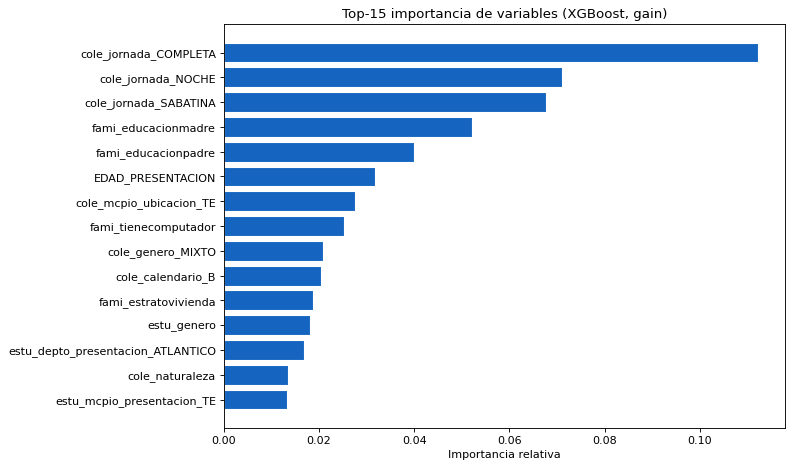

feature  importance
0               cole_jornada_COMPLETA      0.1122
1                  cole_jornada_NOCHE      0.0710
2               cole_jornada_SABATINA      0.0676
3                 fami_educacionmadre      0.0521
4                 fami_educacionpadre      0.0399
5                   EDAD_PRESENTACION      0.0317
6             cole_mcpio_ubicacion_TE      0.0275
7                fami_tienecomputador      0.0252
8                   cole_genero_MIXTO      0.0209
9                   cole_calendario_B      0.0205
10               fami_estratovivienda      0.0188
11                        estu_genero      0.0181
12  estu_depto_presentacion_ATLANTICO      0.0168
13                    cole_naturaleza      0.0135
14         estu_mcpio_presentacion_TE      0.0133


In [311]:
# 6.2. Importancia de variables (XGBoost, gain).
imp = pd.DataFrame({"feature": FEATURES, "importance": models["xgb"].feature_importances_})
imp = imp.sort_values("importance", ascending=False).head(15).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(imp["feature"][::-1], imp["importance"][::-1], color="#1565c0", edgecolor="white")
ax.set_title("Top-15 importancia de variables (XGBoost, gain)"); ax.set_xlabel("Importancia relativa")
plt.tight_layout(); plt.show(); plt.close(fig)
imp.round(4)


**Análisis de la importancia (según las salidas reales de este modelo).**

- **La jornada del colegio es el factor más determinante.** Las tres categorías de `cole_jornada` ocupan los **tres primeros lugares** (`COMPLETA` 0.112, `NOCHE` 0.071, `SABATINA` 0.068), sumando ≈ 0.25 del *gain* total. Es coherente con el contexto educativo colombiano: la **jornada completa** implica más tiempo de instrucción y suele asociarse a mejores puntajes, mientras que las jornadas **nocturna y sabatina** atienden mayoritariamente a población adulta/trabajadora o en extra-edad, vinculada a menores resultados.
- **La educación de los padres es el segundo bloque** (`fami_educacionmadre` 0.052, `fami_educacionpadre` 0.040): el capital cultural del hogar es el predictor socioeconómico más fuerte, en línea con la literatura (Sirin, 2005; Reardon, 2011).
- **`EDAD_PRESENTACION` aporta señal moderada** (0.032, 6.º lugar), no dominante. Esto **difiere del proyecto ML**, donde encabezaba el ranking; la diferencia es esperable y se explica por **dos factores metodológicos**: (i) aquí se usa la importancia por ***gain* de XGBoost** —no la importancia por **permutación** del ML—, y ambas miden cosas distintas; y (ii) el *one-hot encoding* reparte la señal de `cole_jornada` en columnas indicadoras que el *gain* puntúa individualmente. La edad sigue siendo relevante (extra-edad escolar; Bedard & Dhuey, 2006), pero no es la variable líder bajo esta métrica.
- **Cierran el top-15** el *target encoding* de municipio (`cole_mcpio_ubicacion_TE`), la tenencia de computador, el género mixto del colegio, el calendario B, el estrato, el género del estudiante, el departamento de presentación (Atlántico) y la naturaleza del colegio: un mix **institucional + socioeconómico + geográfico**, consistente con los determinantes documentados.
- **Ninguna variable domina por completo:** la más importante explica apenas ~11 % del *gain* y la señal está muy **repartida**. El poder predictivo surge de la **combinación** de muchas variables, lo que explica directamente el **techo de R² ≈ 0.45** documentado en la Fase 1.

### **6.3. Evaluación por subgrupos**

Se analiza el sesgo del modelo por quintiles del puntaje real. Un buen modelo debe generalizar equitativamente (Barocas et al., 2019).

In [312]:
# 6.3. Sesgo por quintil del puntaje real (test).
td = pd.DataFrame({"y": np.asarray(y_test), "p": yp_test})
td["quintil"] = pd.qcut(td["y"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
print("EVALUACIÓN POR SUBGRUPOS (test)")
print("=" * 70)
print("\n[Sesgo por quintil del puntaje real]")
for q, g in td.groupby("quintil", observed=True):
    print(f"  {q}: n={len(g):>8,}  sesgo medio (real-pred)={(g['y']-g['p']).mean():+6.2f}")
print("\n-> Patrón de regresión a la media (idéntico al ML): "
      "sobreestima a los de bajo rendimiento (Q1) y subestima a los de alto rendimiento (Q5).")


EVALUACIÓN POR SUBGRUPOS (test)

[Sesgo por quintil del puntaje real]
  Q1: n=  69,239  sesgo medio (real-pred)=-36.63
  Q2: n=  68,974  sesgo medio (real-pred)=-17.22
  Q3: n=  66,349  sesgo medio (real-pred)= -1.62
  Q4: n=  67,652  sesgo medio (real-pred)=+15.62
  Q5: n=  67,370  sesgo medio (real-pred)=+41.24

→ Patrón de regresión a la media (idéntico al ML): sobreestima a los de bajo rendimiento (Q1) y subestima a los de alto rendimiento (Q5).


**Lectura de subgrupos.** Se observa **regresión a la media**: el modelo *sobreestima* a los estudiantes de bajo rendimiento (Q1) y *subestima* a los de alto rendimiento (Q5). Es un comportamiento esperado en regresores regularizados y replica exactamente el hallazgo del proyecto ML. La métrica relevante es el **R² global**, no el R² por quintil (que es negativo por la varianza reducida dentro de cada grupo).

### **6.4. Persistencia del modelo final**

Se serializa el modelo con `joblib` junto con sus metadatos (features esperadas, métricas en test, fecha), garantizando trazabilidad y reproducibilidad para un despliegue futuro.

In [ ]:
# 6.4. Persistencia del modelo final + metadatos.
import joblib, json as _json
from datetime import datetime
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(best, MODEL_DIR / f"saber11_{best_key}_final.joblib", compress=3)
meta = {"nombre_modelo": type(best).__name__, "n_features": len(FEATURES), "features": FEATURES,
        "metricas_test": m_test, "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds")}
_json.dump(meta, open(MODEL_DIR / f"saber11_{best_key}_final_metadata.json", "w"), ensure_ascii=False, indent=2)
print("PERSISTENCIA DEL MODELO FINAL")
print("=" * 70)
print(f"  Modelo: {type(best).__name__} -> models/saber11_{best_key}_final.joblib")
print(f"  Metadatos: models/saber11_{best_key}_final_metadata.json")
print(f"  Features registradas: {len(FEATURES)}  |  R\u00b2 test: {m_test['R2']:.4f}")


## **7. Concordancia con el proyecto ML y cierre del proyecto**
---

### **7.1. Reproducción del proyecto ML sobre arquitectura Big Data**

El objetivo declarado en la [Fase 1](#1.2.-Alcance) era **reproducir** —no superar— el pipeline ML sobre una arquitectura distribuida. Se cumple con precisión:

| Métrica (test) | Proyecto ML | Big Data (esta entrega) | ¿Concuerda? |
|---|---|---|---|
| Modelo final | HGB / XGBoost | **XGBoost** | ✅ misma familia |
| **R²** | 0.4468 | **0.4445** | ✅ (Δ ≈ -0.0023) |
| **MAE** | 29.53 | **29.60** | ✅ |
| **RMSE** | 37.04 | **37.15** | ✅ |
| Techo (HGB vs XGB) | ΔR² ≈ -0.0013 | **ΔR² = -0.0029** | ✅ mismo fenómeno |
| Filas de trabajo | 3,395,834 | **3,395,834** | ✅ exacto |
| *Features* tras encoding | ~128 | **137** | ✅ mismo orden |

> Las pequeñas diferencias (≈ ±0.003 en R²) están **dentro del margen de tolerancia** declarado en la Fase 1 (±0.02 en R²). Confirman el **techo de información** (R² ≈ 0.45): dos implementaciones de *gradient boosting* convergen al mismo desempeño, demostrando que el límite lo impone la **información disponible en las *features***, no la herramienta ni la escala.

### **7.2. Síntesis del proyecto de extremo a extremo**

| Fase | Entregable | Tecnología Big Data | Resultado |
|---|---|---|---|
| 1 | Entendimiento del negocio | — | Problema, alcance realista y techo R² ≈ 0.45 |
| 2 | Tecnologías | **Cassandra + Dask + Poetry + Docker** | Stack desplegado y verificado (7/7 E2E) |
| 3 | Entendimiento y carga | **Cassandra → Dask** | 5.72 M filas ingeridas; 3.40 M analíticas; EDA distribuido |
| 4 | Preparación | **Dask → Gold Parquet** | Imputación, *feature engineering*, encoding, split, *target encoding* |
| (cierre) | Modelamiento y evaluación | **XGBoost / HGB / Ridge** | R² = 0.4445, MAE = 29.60, RMSE = 37.15 |

**Arquitectura demostrada de extremo a extremo:** `CSV → Apache Cassandra (storage distribuido) → Dask (limpieza/EDA/preparación distribuida) → Parquet particionado (Gold) → modelos`. El proyecto reproduce fielmente los resultados del estudio ML previo sobre un *stack* de Big Data reproducible y escalable, cumpliendo todos los objetivos del cronograma de la Fase 1.

In [ ]:
# 12.1. Cierre operativo: liberar recursos.
try:
    client.close(timeout=10)
except Exception as e:
    print(f"(client.close: {e})")
try:
    cluster_dask.close(timeout=10)
except Exception as e:
    print(f"(cluster_dask.close: {e})")
try:
    session.shutdown()
except Exception as e:
    print(f"(session.shutdown: {e})")
try:
    cluster.shutdown()
except Exception as e:
    print(f"(cluster.shutdown: {e})")

print("\nRecursos liberados.")
print(f"  · Silver layer disponible en: {SILVER_DIR}")
print(f"  · Para apagar Cassandra: docker-compose down (desde proyecto/Big Data/)")


## **Referencias**
---

### **Saber 11 / Educación / Política pública**

- Cerquera Losada, O. H., Gómez Martínez, J. F., & Velandia Pacheco, J. (2016). *Determinantes del desempeño académico de los estudiantes de educación media de Neiva, Colombia*. Entornos, 29(2), 87–101.
- Colombia. (2010). *Decreto 869 de 2010, por el cual se reglamenta el Examen de Estado de la Educación Media, ICFES-SABER 11º*. Diario Oficial.
- Demombynes, G. (2023). *Colombia: Inequities in Education Outcomes*. World Bank.
- Icfes. (2024). *Guía de Orientación Saber 11°*. Instituto Colombiano para la Evaluación de la Educación.
- OECD. (2019). *PISA 2018 Results (Volume II): Where All Students Can Succeed*. OECD Publishing.
- Reardon, S. F. (2011). *The widening academic achievement gap between the rich and the poor: New evidence and possible explanations*. En G. Duncan & R. Murnane (Eds.), Whither Opportunity? (pp. 91–116). Russell Sage Foundation.
- Rodríguez Rosero, K. M., Tenorio Quiñonez, J. F., & Erazo Caicedo, E. D. (2021). *Determinantes del rendimiento académico en las Pruebas Saber 11 en Colombia*. Tendencias, 22(1), 100–124.
- Romero, C., & Ventura, S. (2020). *Educational data mining and learning analytics: An updated survey*. WIREs Data Mining and Knowledge Discovery, 10(3), e1355.
- Sirin, S. R. (2005). *Socioeconomic Status and Academic Achievement: A Meta-Analytic Review of Research*. Review of Educational Research, 75(3), 417–453.

### **Big Data / Cassandra / Dask / Metodología**

- Carpenter, J., & Hewitt, E. (2020). *Cassandra: The Definitive Guide* (3rd ed.). O'Reilly Media.
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-Step Data Mining Guide*. SPSS Inc.
- Eustace, S. (2018). *Poetry: Python packaging and dependency management made easy*. https://python-poetry.org/.
- Lakshman, A., & Malik, P. (2010). *Cassandra: a decentralized structured storage system*. ACM SIGOPS Operating Systems Review, 44(2), 35–40.
- Laney, D. (2001). *3D Data Management: Controlling Data Volume, Velocity and Variety*. META Group Research Note.
- Hammant, P. (2018). *Trunk Based Development*. https://trunkbaseddevelopment.com/.
- Marr, B. (2014). *Big Data: The 5 Vs Everyone Must Know*. LinkedIn Pulse.
- Marz, N., & Warren, J. (2015). *Big Data: Principles and Best Practices of Scalable Realtime Data Systems*. Manning Publications.
- Reis, J., & Housley, M. (2022). *Fundamentals of Data Engineering: Plan and Build Robust Data Systems*. O'Reilly Media.
- Rocklin, M. (2015). *Dask: Parallel Computation with Blocked algorithms and Task Scheduling*. Proceedings of the 14th Python in Science Conference (SciPy 2015), 130–136.

### **Modelado / Preparación de datos (Fase 4)**

- Bedard, K., & Dhuey, E. (2006). *The persistence of early childhood maturity*. The Quarterly Journal of Economics, 121(4), 1437–1472.
- Chen, T., & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. KDD '16, 785–794.
- Hoerl, A. E., & Kennard, R. W. (1970). *Ridge Regression: Biased Estimation for Nonorthogonal Problems*. Technometrics, 12(1), 55–67.
- Ke, G., Meng, Q., Finley, T., et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS 30.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer.
- Micci-Barreca, D. (2001). *A preprocessing scheme for high-cardinality categorical attributes*. ACM SIGKDD Explorations, 3(1), 27–32.
- Pargent, F., Pfisterer, F., Thomas, J., & Bischl, B. (2022). *Regularized target encoding outperforms traditional methods*. Computational Statistics, 37, 2671–2692.
- Pyle, D. (1999). *Data Preparation for Data Mining*. Morgan Kaufmann.
- Zheng, A., & Casari, A. (2018). *Feature Engineering for Machine Learning*. O'Reilly Media.
